# Data preview: Dataset G (Caron, GSE229791, CITE-seq) and Dataset H (Zheng, FACS-purified PBMC populations)
In this notebook I examine two immune-cell datasets in the same way as `data_preview.ipynb` (Dataset A, Baron),
`data_preview_dataset_B_and_C.ipynb` (B and C) and `data_preview_dataset_D_E_F.ipynb` (D, E and F): **Dataset G = Caron et
al. (GSE229791, the MMoCHi paper; CITE-seq = 10x 3' v3.1 RNA plus a 277-antibody TotalSeq-A surface-protein panel; immune
cells from up to eight tissue sites of two organ donors, plus FACS-sorted blood T-cell subsets and monocytes of one
volunteer)** and **Dataset H = the purified PBMC populations of Zheng et al. 2017 (10x), supplied as two pre-processed
files that turn out to have been built by the project notebook `sorted_pbmc.ipynb`**. They are the first non-pancreas
datasets. The structure is the same as before: first what the downloaded or supplied files contain and how the
expression matrices were obtained, then a full inspection of each dataset (overview → integrity / missing values →
labels → per-cell QC → gene-level behaviour → markers → global structure → summary → preprocessing proposal), and
finally a comparison with each other and with A–F. For G the RNA sections are kept and protein (ADT) checks are added
where they fit: ADT integrity, per-cell ADT totals, isotype controls, protein vs RNA for the same markers, and whether
labels separate in protein space. No model is fitted here.

## 0. Shared setup
Imports, paths, plot style and the helper functions. The first helper cell is copied unchanged from
`data_preview_dataset_D_E_F.ipynb` §0 (itself the parameterised version of `data_preview.ipynb` §1.2–1.7), so G and H
run the same checks as A–F. The second helper cell adds what G and H need on top: immune label vocabularies and
marker panels, protein (ADT) helpers, an integrity table built from precomputed numbers (G is too large to hold in
memory at once, see G.0), and a silhouette on a fixed random subsample.

In [1]:
# --- Imports ---------------------------------------------------------------
import warnings
warnings.filterwarnings("ignore", category=UserWarning)          # silence pandas/numexpr version chatter
warnings.filterwarnings("ignore", category=DeprecationWarning)   # np.fromstring(sep=...) chatter

import sys
import gc
import gzip
import json
import time
import textwrap
from pathlib import Path
import numpy as np
import pandas as pd
import scipy.sparse as sp
import anndata as ad
import scanpy as sc
import h5py
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.metrics import silhouette_score
import GEOparse
GEOparse.set_verbosity("ERROR")

# --- Reproducibility ------------------------------------------------------------
# PCA (randomised solver), the G subsample and the silhouette subsampling are the only random steps.
SEED = 0
np.random.seed(SEED)

# --- Paths ------------------------------------------------------------------
# Raw files follow the project pattern data/raw/<author>_<accession>/ (data/ is git-ignored). The SOFT file and the two
# Zheng files were copied (not moved) from ~/Downloads/proj_data/; the six GEO supplementary matrices of GSE229791 were
# downloaded from the GEO HTTPS mirror of the FTP URLs listed in the SOFT file. See the §0 cell of each dataset.
PROJECT   = Path("/home/professor/cell-type-annotaion-benchmark")
RAW       = PROJECT / "data" / "raw"
INTERIM   = PROJECT / "data" / "interim"
CARON_DIR = RAW / "caron_GSE229791"
CARON_SOFT = CARON_DIR / "GSE229791_family.soft.gz"
CARON_SAMPLES = ["D496", "D503", "PDC101"]
CARON_GEX = {s: CARON_DIR / f"GSE229791_{s}.gex.matrix.txt.gz" for s in CARON_SAMPLES}
CARON_ADT = {s: CARON_DIR / f"GSE229791_{s}.adt.matrix.txt.gz" for s in CARON_SAMPLES}
ZHENG_DIR = RAW / "zheng_purified_pbmc"
ZHENG_IN_H5 = ZHENG_DIR / "zheng_purified_pbmc_counts.h5ad"
ZHENG_CSV   = ZHENG_DIR / "zheng_purified_pbmc_metadata.csv"
SORTED_NB   = PROJECT / "sorted_pbmc.ipynb"      # read only: the notebook that produced the two Zheng files (H.0)
CARON_H5, CARON_ADT_H5, ZHENG_H5 = INTERIM / "caron_human.h5ad", INTERIM / "caron_human_adt.h5ad", INTERIM / "zheng_human.h5ad"
EARLIER_H5 = {"A Baron": INTERIM / "baron_human.h5ad", "B Xin": INTERIM / "xin_human.h5ad", "C Muraro": INTERIM / "muraro_human.h5ad",
              "D Segerstolpe": INTERIM / "segerstolpe_human.h5ad", "E Lawlor": INTERIM / "lawlor_human.h5ad", "F Enge": INTERIM / "enge_human.h5ad"}
for p in [CARON_SOFT, *CARON_GEX.values(), *CARON_ADT.values(), ZHENG_IN_H5, ZHENG_CSV, SORTED_NB, *EARLIER_H5.values()]:
    assert p.exists(), f"{p} missing: see the §0 cell of the corresponding dataset for where it comes from"

# --- Plot style (identical to data_preview.ipynb) -------------------------------
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 9, "axes.titlesize": 10,
    "legend.frameon": False,
})
from importlib.metadata import version
print("python", sys.executable)
print("scanpy", version("scanpy"), "| anndata", version("anndata"), "| scikit-learn", version("scikit-learn"),
      "| GEOparse", version("GEOparse"), "| h5py", version("h5py"))

python /home/professor/miniconda3/envs/dataenv/bin/python
scanpy 1.12.4 | anndata 0.13.4 | scikit-learn 1.7.1 | GEOparse 2.0.4 | h5py 3.15.1


In [2]:
# --- Helper functions (copied unchanged from data_preview_dataset_D_E_F.ipynb §0) -----------------

def soft_samples(gse):
    """One row per GSM: title/description/platform plus every 'key: value' characteristic as its own column."""
    rows = {}
    for gsm_id, gsm in gse.gsms.items():
        m = gsm.metadata
        r = {"title": m["title"][0], "description": "; ".join(m.get("description", [])),
             "platform": m["platform_id"][0], "source": m["source_name_ch1"][0],
             "table_rows": gsm.table.shape[0], "supplementary_file": m.get("supplementary_file_1", ["NONE"])[0]}
        for ch in m.get("characteristics_ch1", []):
            k, _, v = ch.partition(":")
            r[k.strip()] = v.strip()
        rows[gsm_id] = r
    return pd.DataFrame.from_dict(rows, orient="index")


def integrity_checks(adata, integer_expected):
    """Same list as data_preview.ipynb §1.2 (non-integer check only where the values are supposed to be counts)."""
    X = adata.X
    checks = {
        "NaN/Inf in matrix":         int((~np.isfinite(X.data)).sum()),
        "negative values":           int((X.data < 0).sum()),
        "non-integer values":        int((X.data != np.round(X.data)).sum()),
        "NaN cells in obs":          int(adata.obs.isna().sum().sum()),
        "NaN cells in var":          int(adata.var.isna().sum().sum()),
        "duplicated cell IDs":       int(adata.obs_names.duplicated().sum()),
        "duplicated gene names":     int(adata.var_names.duplicated().sum()),
        "cells with zero total":     int((np.asarray(X.sum(1)).ravel() == 0).sum()),
        "genes detected in 0 cells": int((np.asarray((X > 0).sum(0)).ravel() == 0).sum()),
    }
    s = pd.Series(checks, name="count").to_frame()
    s["expected"] = ["0", "0", "0" if integer_expected else "n/a (not counts)", "0", "0", "0", "0", "0", "-"]
    return s


def gene_vec(adata, symbol, layer=None):
    """Dense vector of one gene, looked up by symbol (var['symbol'])."""
    j = np.flatnonzero(adata.var["symbol"].values == symbol)
    assert len(j) == 1, (symbol, len(j))
    M = adata.X if layer is None else adata.layers[layer]
    return np.asarray(M[:, j[0]].todense()).ravel()


def gene_level(adata, unit):
    """Detection counts, top genes and mean/variance per gene (data_preview.ipynb §1.5)."""
    X = adata.X
    n_cells_expr = np.asarray((X > 0).sum(0)).ravel()
    gene_tot = np.asarray(X.sum(0)).ravel()
    mean = np.asarray(X.mean(0)).ravel()
    var = np.asarray(X.multiply(X).mean(0)).ravel() - mean ** 2
    print("Genes detected in at most k cells:")
    for k in [0, 2, 9, 19, 49]:
        print(f"  <= {k:>2} cells: {(n_cells_expr <= k).sum():>5}  ({100 * (n_cells_expr <= k).mean():.1f}%)")
    top = pd.Series(gene_tot / gene_tot.sum() * 100, index=adata.var["symbol"].values).sort_values(ascending=False).head(15)
    print(f"\nTop-15 genes by share of all {unit} (%):"); print(top.round(2).to_string())
    return n_cells_expr, mean, var


def plot_gene_level(n_cells_expr, mean, var, n_obs, unit):
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
    k = mean > 0
    axes[0].scatter(mean[k], var[k], s=2, alpha=0.3, color=PALETTE[0], linewidths=0)
    xx = np.logspace(np.log10(mean[k].min()), np.log10(mean[k].max()), 50)
    axes[0].plot(xx, xx, color=INK, lw=1, ls="--", label="Poisson: var = mean")
    slope, icpt = np.polyfit(np.log10(mean[k]), np.log10(var[k]), 1)
    axes[0].plot(xx, 10 ** icpt * xx ** slope, color=PALETTE[1], lw=1.5, label=f"fit: slope {slope:.2f}")
    axes[0].set_xscale("log"); axes[0].set_yscale("log")
    axes[0].set_xlabel(f"mean {unit} per cell"); axes[0].set_ylabel("variance"); axes[0].legend(fontsize=8)
    axes[0].set_title(f"(a) Variance grows with the mean ({unit})")
    det = n_cells_expr / n_obs * 100
    axes[1].hist(det[det > 0], bins=np.logspace(np.log10(det[det > 0].min()), 2, 50), color=PALETTE[0],
                 edgecolor="#fcfcfb", lw=0.5)
    axes[1].set_xscale("log"); axes[1].set_xlabel("% of cells in which the gene is detected (log)")
    axes[1].set_ylabel("genes"); axes[1].set_title("(b) Most genes are detected in few cells")
    fig.tight_layout(); plt.show()
    return slope


def detection_heatmap(adata, genes, labels, row_order, title, layer=None):
    """% of cells with value > 0 for each marker, per label (data_preview.ipynb §1.6)."""
    genes = [g for g in dict.fromkeys(genes) if (adata.var["symbol"] == g).sum() == 1]
    detect = pd.DataFrame({g: gene_vec(adata, g, layer) > 0 for g in genes},
                          index=adata.obs_names).groupby(np.asarray(labels)).mean().loc[row_order] * 100
    fig, ax = plt.subplots(figsize=(0.45 * len(genes) + 2.5, 0.38 * len(row_order) + 1.6))
    im = ax.imshow(detect.values, cmap="Blues", vmin=0, vmax=100, aspect="auto")
    ax.set_xticks(range(len(genes)), genes, rotation=45, ha="right"); ax.set_yticks(range(len(row_order)), row_order)
    ax.grid(False)
    for i in range(detect.shape[0]):
        for j in range(detect.shape[1]):
            v = detect.values[i, j]
            ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=6.5, color="white" if v > 60 else INK)
    fig.colorbar(im, ax=ax, label="% of cells with value > 0", shrink=0.8)
    ax.set_title(title); fig.tight_layout(); plt.show()
    return detect


def throwaway_pca(adata):
    """Inspection-only pipeline from data_preview.ipynb §1.7: normalise to 10k -> log1p -> 2,000 HVGs -> z-score -> PCA."""
    tmp = adata.copy()
    sc.pp.normalize_total(tmp, target_sum=1e4)
    sc.pp.log1p(tmp)
    sc.pp.highly_variable_genes(tmp, n_top_genes=2000, flavor="seurat")
    tmp = tmp[:, tmp.var.highly_variable].copy()
    sc.pp.scale(tmp, max_value=10)
    sc.tl.pca(tmp, n_comps=50, random_state=SEED)
    evr = tmp.uns["pca"]["variance_ratio"]
    print("Explained variance, PC1..PC10 (%):", np.round(100 * evr[:10], 1))
    print(f"Cumulative variance in 20 / 50 PCs: {100 * evr[:20].sum():.1f}% / {100 * evr.sum():.1f}%")
    loadings = pd.DataFrame(tmp.varm["PCs"][:, :2], index=tmp.var_names, columns=["PC1", "PC2"])
    return tmp.obsm["X_pca"], evr, loadings


def scatter_groups(ax, P, groups, colors, title, perm):
    g = np.asarray(groups)[perm]; Pp = P[perm]
    for name, c in colors.items():
        s = g == name
        ax.scatter(Pp[s, 0], Pp[s, 1], s=3, alpha=0.6, color=c, label=f"{name}", linewidths=0)
    ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.set_title(title); ax.legend(markerscale=4, fontsize=7)


def hormone_purity(adata, labels, hormone, order):
    """B.6 check: is the highest of the islet hormones the labelled one, and is a second hormone almost as high?"""
    H = pd.DataFrame({t: np.log1p(gene_vec(adata, g)) for t, g in hormone.items()}, index=adata.obs_names)
    top_h = H.idxmax(axis=1)
    srt = np.sort(H.values, axis=1)
    mixed = srt[:, -2] > 0.8 * srt[:, -1]                  # second hormone within 20% of the top one (log scale)
    labels = pd.Series(np.asarray(labels), index=adata.obs_names)
    tab = pd.DataFrame({
        "n_cells": [(labels == t).sum() for t in order],
        "top hormone = label": [(top_h[labels == t] == t).sum() for t in order],
        "top hormone != label": [(top_h[labels == t] != t).sum() for t in order],
        "two hormones high (mixed)": [int(mixed[(labels == t).values].sum()) for t in order],
    }, index=order)
    return tab, top_h, mixed


# Pancreas label hierarchy (top level), shared with data_preview.ipynb §1.3 and B_and_C §0, extended with the label
# vocabularies of D (Segerstolpe), E (Lawlor) and F (Enge) after lower-casing (see each X.3 for the mapping).
LINEAGE = {
    "alpha": "endocrine", "beta": "endocrine", "delta": "endocrine", "gamma": "endocrine", "pp": "endocrine",
    "epsilon": "endocrine", "acinar": "exocrine", "ductal": "exocrine",
    "activated_stellate": "stromal", "quiescent_stellate": "stromal", "mesenchymal": "stromal",
    "endothelial": "stromal", "schwann": "stromal", "macrophage": "immune", "mast": "immune", "t_cell": "immune",
    "unassigned": "unassigned",
    # new in D/E/F
    "co-expression": "endocrine", "unclassified_endocrine": "endocrine", "psc": "stromal", "stellate": "stromal",
    "mhc_class_ii": "immune", "unclassified": "unassigned", "none/other": "unassigned", "unsure": "unassigned",
    "not_applicable": "unassigned",
}
LINEAGE_ORDER = ["endocrine", "exocrine", "stromal", "immune"]
LINEAGE_COLOR = dict(zip(LINEAGE_ORDER, PALETTE[:4])) | {"unassigned": MUTED}
COND_COLOR = {"non-diabetic": PALETTE[0], "T2D": PALETTE[1]}

# Marker panel of data_preview.ipynb §1.6 (one canonical marker per Baron type) + the independent endocrine markers of
# B_and_C §B.6, and the independent check panel of §C.6.
MARKERS = {
    "alpha": "GCG", "beta": "INS", "delta": "SST", "gamma": "PPY", "epsilon": "GHRL",
    "acinar": "PRSS1", "acinar ": "CPA1", "ductal": "KRT19",
    "activated_stellate": "COL1A1", "quiescent_stellate": "RGS5", "endothelial": "PECAM1",
    "schwann": "SOX10", "macrophage": "SDS", "mast": "TPSAB1", "t_cell": "CD3E",
}
EXTRA_ENDOCRINE = ["IRX2", "ARX", "MAFA", "HHEX", "CHGA"]
CHECK = ["IRX2", "ARX", "MAFA", "HADH", "HHEX", "CHGA", "REG1A", "CELA3A", "CFTR", "SOX9", "PDGFRB", "RGS5", "ESAM", "VWF"]


def type_order(labels):
    """Labels grouped by lineage (endocrine, exocrine, stromal, immune), largest first, unassigned-type labels last."""
    vc = pd.Series(labels).value_counts()
    return [t for l in LINEAGE_ORDER + ["unassigned"] for t in vc.index if LINEAGE[t] == l]

In [3]:
# --- Extensions for G and H (immune cells, CITE-seq protein, large cell numbers) -------------------------------

def integrity_table(checks, integer_expected):
    """Same rows and 'expected' column as integrity_checks(), from numbers computed elsewhere (G is streamed, G.0)."""
    s = pd.Series(checks, name="count").to_frame()
    s["expected"] = ["0", "0", "0" if integer_expected else "n/a (not counts)", "0", "0", "0", "0", "0", "-"]
    return s


def silhouette(P, groups, n=10_000):
    """Silhouette on the first 20 PCs. G and H have 10-100x more cells than A-F, so above n cells it is computed on a
    fixed random subsample of n cells (sklearn sample_size, seeded)."""
    groups = np.asarray(groups)
    return silhouette_score(P[:, :20], groups, sample_size=n if len(groups) > n else None, random_state=SEED)


def lognorm(X):
    """Library-size normalisation to 10,000 + log1p on a sparse cells x genes matrix (same transform as throwaway_pca)."""
    X = sp.csr_matrix(X, dtype=np.float32)
    tot = np.asarray(X.sum(1)).ravel()
    L = sp.csr_matrix(X.multiply((1e4 / np.maximum(tot, 1))[:, None]), dtype=np.float32)
    L.data = np.log1p(L.data)
    return L


def clr(M):
    """Per-cell centred log-ratio of ADT counts: log1p(x) minus the mean of log1p(x) over that cell's ADTs."""
    L = np.log1p(np.asarray(M, dtype=np.float32))
    return L - L.mean(axis=1, keepdims=True)


def marker_call(L, symbols, markers, min_scaled=0.4, max_ratio=0.85):
    """Muraro-style provisional call (B_and_C §C.3): mean log-normalised expression of each label's markers, scaled by
    its own 99th percentile, argmax; 'unassigned' if the best score is weak (< min_scaled) or a runner-up is close
    (>= max_ratio x best). Inspection only, never ground truth."""
    symbols = np.asarray(symbols)
    used = {t: [g for g in gs if (symbols == g).sum() == 1] for t, gs in markers.items()}
    score = pd.DataFrame({t: np.asarray(L[:, [int(np.flatnonzero(symbols == g)[0]) for g in gs]].mean(1)).ravel()
                          for t, gs in used.items()})
    q = score.quantile(0.99).replace(0, np.nan).fillna(score.max()).replace(0, 1)
    scaled = (score / q).clip(lower=0)
    srt = np.sort(scaled.values, axis=1)
    ok = (srt[:, -1] >= min_scaled) & (srt[:, -2] < max_ratio * srt[:, -1])
    return np.where(ok, scaled.idxmax(axis=1).to_numpy(), "unassigned"), used


def value_heatmap(df, title, cbar_label, cmap="Blues", vmin=None, vmax=None, fmt="{:.0f}", center_white=None):
    """Annotated heatmap of a labels x markers table (detection %, median CLR, ...)."""
    fig, ax = plt.subplots(figsize=(0.45 * df.shape[1] + 2.8, 0.38 * df.shape[0] + 1.6))
    im = ax.imshow(df.values, cmap=cmap, vmin=vmin, vmax=vmax, aspect="auto")
    ax.set_xticks(range(df.shape[1]), df.columns, rotation=45, ha="right"); ax.set_yticks(range(df.shape[0]), df.index)
    ax.grid(False)
    hi = np.nanpercentile(df.values, 70) if center_white is None else center_white
    for i in range(df.shape[0]):
        for j in range(df.shape[1]):
            v = df.values[i, j]
            ax.text(j, i, fmt.format(v), ha="center", va="center", fontsize=6.5, color="white" if v > hi else INK)
    fig.colorbar(im, ax=ax, label=cbar_label, shrink=0.8)
    ax.set_title(title); fig.tight_layout(); plt.show()


# Immune label vocabulary (top level), added to the pancreas LINEAGE table so that the cross-dataset section can place
# G and H labels next to A-F. Keys are the lower-cased labels used in G.3 and H.3.
IMMUNE_LINEAGE = {
    # G: provisional protein labels (G.3) and FACS sort gates of PDC101
    "t": "immune", "b": "immune", "nk": "immune", "myeloid": "immune", "plasma": "immune", "pdc": "immune",
    "epithelial": "epithelial", "erythroid": "erythroid",
    "cd4_n": "immune", "cd4_cm": "immune", "cd4_em": "immune", "cd8_n": "immune", "cd8_cm": "immune",
    "cd8_em": "immune", "cd8_emra": "immune", "monocyte": "immune",
    # H: sorted populations
    "cd19+ b": "immune", "cd14+ monocyte": "immune", "cd34+": "progenitor", "cd4+ helper t": "immune",
    "cd56+ nk": "immune", "cd8+ cytotoxic t": "immune", "cd4+/cd45ro+ memory t": "immune",
    "cd8+/cd45ra+ naive cytotoxic t": "immune", "cd4+/cd45ra+/cd25- naive t": "immune", "cd4+/cd25+ regulatory t": "immune",
}
LINEAGE.update(IMMUNE_LINEAGE)

# RNA marker panel for immune lineages, used (a) to check G's protein-based provisional labels in the other modality and
# (b) to estimate the purity of H's sorted populations. Canonical markers, not taken from either dataset.
IMMUNE_CALL = {
    "T": ["CD3E", "CD3D"], "B": ["MS4A1", "CD79A"], "NK": ["NKG7", "GNLY", "KLRD1"], "myeloid": ["CD14", "LYZ", "CSF1R"],
    "plasma": ["JCHAIN", "MZB1"], "pDC": ["LILRA4", "IL3RA"], "progenitor": ["CD34"], "erythroid": ["HBB", "HBA1"],
    "epithelial": ["EPCAM", "KRT8"],
}
IMMUNE_CHECK = ["PTPRC", "CD3E", "CD3D", "CD4", "CD8A", "MS4A1", "CD79A", "NKG7", "GNLY", "KLRD1", "CD14", "LYZ", "CSF1R",
                "FCGR3A", "JCHAIN", "MZB1", "LILRA4", "CD34", "HBB", "EPCAM", "KRT8", "TPSAB1", "PPBP"]
# T-cell subset markers (naive / memory / effector / regulatory), for the FACS-defined T-cell labels of G (PDC101) and H.
TSUBSET_RNA = ["CD4", "CD8A", "CD8B", "CCR7", "SELL", "LEF1", "TCF7", "IL7R", "CD27", "CD28", "GZMK", "GZMB", "GZMH",
               "PRF1", "GNLY", "NKG7", "KLRG1", "FOXP3", "IL2RA", "CTLA4", "CD14", "LYZ"]

---
# Dataset G — Caron et al. (GSE229791, human immune cells from organ-donor tissues and FACS-sorted blood, CITE-seq)

## G.0 What is in the SOFT file, and conversion of the RNA and protein matrices
The SOFT file was copied (not moved) from `~/Downloads/proj_data/(rna+protein)GSE229791_family.soft.gz` to
`data/raw/caron_GSE229791/GSE229791_family.soft.gz` (the parentheses and `+` were dropped from the name).

In [4]:
gse_g = GEOparse.get_GEO(filepath=str(CARON_SOFT))
print("GEO accession:", gse_g.name, "|", gse_g.metadata["title"][0])
print("PubMed IDs:", gse_g.metadata.get("pubmed_id"), "| contributors:", gse_g.metadata.get("contributor"))
print("Overall design:", gse_g.metadata["overall_design"][0])
print("Platforms:", {k: v.metadata["title"][0] for k, v in gse_g.gpls.items()}, "| number of samples (GSM):", len(gse_g.gsms))
print("Series supplementary files:", *gse_g.metadata["supplementary_file"], sep="\n  ")

meta_g = soft_samples(gse_g)
meta_g["sample"] = meta_g["title"].str.split().str[0]
print("\nGSM tables with rows:", int((meta_g.table_rows > 0).sum()), "| GSM supplementary files:",
      meta_g.supplementary_file.value_counts().to_dict())
print("Characteristic keys:", [c for c in meta_g.columns if c not in
      ("title", "description", "platform", "source", "table_rows", "supplementary_file", "sample")])
display(meta_g.groupby(["sample", "library type"]).agg(
    n_gsm=("title", "size"), tissue=("tissue", lambda s: "; ".join(sorted(set(s)))),
    cell_type=("cell type", lambda s: "; ".join(sorted(set(s)))),
    tags=("antibodies/tags", lambda s: " | ".join(sorted(set(s)))), platform=("platform", lambda s: "; ".join(sorted(set(s))))))
for (s_, lt), tags in meta_g.groupby(["sample", "library type"])["antibodies/tags"]:
    if lt == "HTO":
        print(f"{s_} HTO tags:", sorted(set(tags)))
first = next(iter(gse_g.gsms.values())).metadata
print("\ndata_processing (identical for every GSM):")
for line in first["data_processing"]:
    print(textwrap.fill(line, 130, initial_indent="  * ", subsequent_indent="    "))
print("\nextract_protocol (identical for every GSM):")
for line in first["extract_protocol_ch1"]:
    print(textwrap.fill(line, 130, initial_indent="  * ", subsequent_indent="    "))

GEO accession: GSE229791 | Multimodal hierarchical classification allows for efficient annotation of CITE-seq data
PubMed IDs: ['37461466', '39814026'] | contributors: ['Daniel,,Caron', 'Steven,,Wells', 'Peter,,Szabo', 'David,,Chen', 'Donna,,Farber', 'Peter,A,Sims']
Overall design: We performed CITE-seq on immune cell populations from human blood and different human organ donor tissues.
Platforms: {'GPL18573': 'Illumina NextSeq 500 (Homo sapiens)', 'GPL24676': 'Illumina NovaSeq 6000 (Homo sapiens)'} | number of samples (GSM): 102
Series supplementary files:
  ftp://ftp.ncbi.nlm.nih.gov/geo/series/GSE229nnn/GSE229791/suppl/GSE229791_D496.adt.matrix.txt.gz
  ftp://ftp.ncbi.nlm.nih.gov/geo/series/GSE229nnn/GSE229791/suppl/GSE229791_D496.gex.matrix.txt.gz
  ftp://ftp.ncbi.nlm.nih.gov/geo/series/GSE229nnn/GSE229791/suppl/GSE229791_D503.adt.matrix.txt.gz
  ftp://ftp.ncbi.nlm.nih.gov/geo/series/GSE229nnn/GSE229791/suppl/GSE229791_D503.gex.matrix.txt.gz
  ftp://ftp.ncbi.nlm.nih.gov/geo/series/

n_gsm   tissue                 cell_type  \
sample library type                                             
D496   ADT              16  various  mononuclear cells (MNCs)   
       HTO              16  various  mononuclear cells (MNCs)   
       mRNA             16  various  mononuclear cells (MNCs)   
D503   ADT              16  various  mononuclear cells (MNCs)   
       HTO              16  various  mononuclear cells (MNCs)   
       mRNA             16  various  mononuclear cells (MNCs)   
FACS   ADT               2    blood     T cells and monocytes   
       HTO               2    blood     T cells and monocytes   
       mRNA              2    blood     T cells and monocytes   

                                                                  tags  \
sample library type                                                      
D496   ADT                         TotalSeq-A Human Universal Cocktail   
       HTO           TotalSeq-A0251,TotalSeq-A0252,TotalSeq-A0253,T...   
       mRNA                                                       none   
D503   ADT                         TotalSeq-A Human Universal Cocktail   
       HTO           TotalSeq-A0251,TotalSeq-A0252,TotalSeq-A0253,T...   
       mRNA                                                       none   
FACS   ADT                         TotalSeq-A Human Universal Cocktail   
       HTO           TotalSeq-A0251,TotalSeq-A0252,TotalSeq-A0253,T...   
       mRNA                                                       none   

                     platform  
sample library type            
D496   ADT           GPL18573  
       HTO           GPL18573  
       mRNA          GPL24676  
D503   ADT           GPL18573  
       HTO           GPL18573  
       mRNA          GPL24676  
FACS   ADT           GPL18573  
       HTO           GPL18573  
       mRNA          GPL18573

D496 HTO tags: ['TotalSeq-A0251,TotalSeq-A0252,TotalSeq-A0253,TotalSeq-A0254,TotalSeq-A0255,TotalSeq-A0256,TotalSeq-A0257']
D503 HTO tags: ['TotalSeq-A0251,TotalSeq-A0252,TotalSeq-A0253,TotalSeq-A0254,TotalSeq-A0255,TotalSeq-A0256,TotalSeq-A0257,TotalSeq-A0258']
FACS HTO tags: ['TotalSeq-A0251,TotalSeq-A0252,TotalSeq-A0253,TotalSeq-A0254,TotalSeq-A0255,TotalSeq-A0256,TotalSeq-A0257,TotalSeq-A0258']

data_processing (identical for every GSM):
  * scRNA-seq reads were analyzed by pseudoalignment using kallisto v0.46.2 (GRCh38 with Gencode v24 annotation) and bustools
    v0.40.0. CITE-seq and hashtag barcodes were demultiplexed and extracted using DropSeqPipeline8
    (https://github.com/simslab/DropSeqPipeline8). Hashtags were demultiplexed by CLR normalization, k-means clustering, and
    statistical identification of singlets by fitting a negative binomial model as described in Stoeckius et al, Genome Biology,
    2018.
  * Assembly: GRCh38
  * Supplementary files format and content: 

**What the SOFT file contains.** GSE229791 is the data series of the MMoCHi paper (*Multimodal hierarchical
classification allows for efficient annotation of CITE-seq data*; Caron, Wells, Szabo, Chen, Farber, Sims; PubMed
37461466 and 39814026). Its **102 GSMs are sequencing libraries, not cells**: for each organ donor (**D496, D503**) 16 GEX
(mRNA) + 16 ADT + 16 HTO libraries (16 10x channels per donor), and 2 + 2 + 2 libraries for the FACS experiment (titled
`FACS …`; its matrices are named `PDC101`, the protocol says "PDC100-PDC101"). All GSM tables are empty and no GSM has a
supplementary file, so **there is no per-cell information in the SOFT at all**: tissue is `various` (donors) or `blood`
(FACS), cell type `mononuclear cells (MNCs)` or `T cells and monocytes`. The donors' GEX libraries were sequenced on a
NovaSeq 6000 (GPL24676), ADT/HTO libraries and the FACS GEX on a NextSeq 500 (GPL18573).

The useful content is in the protocol text:
* **Organ donors:** MNCs from several tissues per donor, each tissue labelled with its own **hashtag** (D496: 7 hashtags,
  TotalSeq-A0251–A0257; D503: 8, A0251–A0258), pooled, stained with the **TotalSeq-A Human Universal Cocktail** and run on
  10x 3' v3.1. For D496/D503 the hashtag therefore identifies the **tissue site**. No donor age, sex or clinical data are
  given.
* **FACS sample:** PBMC of one healthy **35-year-old male volunteer**, sorted into **seven T-cell populations (CD4 naive,
  TCM, TEM; CD8 naive, TCM, TEM, TEMRA) and monocytes**, each tagged with its own hashtag (HTO1–HTO8), "mean purity 94.4%
  (ranging from 97.1% to 91.8%)". For PDC101 the hashtag therefore **is the sort gate**, i.e. a label defined by surface
  protein, like Zheng's (H).
* **Processing:** kallisto 0.46.2 / bustools on **GRCh38 with GENCODE v24**; ADT and hashtag counts with DropSeqPipeline8;
  hashtags demultiplexed by CLR, k-means and a negative-binomial singlet model (Stoeckius et al. 2018). The deposited
  files contain "cell-identifying barcodes, hashtags, and count matrix".

**Cell-type labels are not in GEO.** The MMoCHi annotations the paper is about are not part of the series. Only the FACS
sort gates (PDC101) and the tissue of origin (organ donors) can be recovered (G.3).

The series supplementary files are six tab-separated matrices, **one RNA (`gex`) and one protein (`adt`) table per
sample** (D496, D503, PDC101). They were downloaded from the GEO HTTPS mirror of the listed FTP URLs into
`data/raw/caron_GSE229791/`; no archive is involved. Each is a dense text table: rows = features (`accession`, `gene`),
columns = cells named `<barcode>-<lane>.<HTO>.<tissue or sort gate>`.

**Conversion.** The three GEX tables have 60,725 gene rows and 89,800 / 123,103 / 10,487 cell columns, too large to load
densely here. The cell below streams them gene by gene into an on-disk sparse matrix (so `X` of `caron_human.h5ad` is
stored **CSC**, gene-major), and checks that the three files list the same genes in the same order, that every value is
a non-negative integer, and that every ADT table has exactly the same cell barcodes as its GEX table. The column
**order** differs in D496 and D503, so the ADT columns are re-ordered by barcode. RNA and protein are written as two
AnnData files with identical `obs` (same cells, same order): `data/interim/caron_human.h5ad` (RNA, `X` = UMI counts)
and `data/interim/caron_human_adt.h5ad` (`X` = ADT counts; PDC101's hashtag counts in `obsm['hto_counts']`). A fixed
random subsample (all 10,487 PDC101 cells + 10,000 per organ donor) is kept in memory for the steps that need a matrix
(markers, PCA); every per-cell and per-gene statistic is computed on all cells.

In [5]:
# --- Conversion: GEO text tables -> data/interim/caron_human.h5ad (RNA) + caron_human_adt.h5ad (protein) ----------
# The GEX tables are dense text (genes x cells, 60,725 rows x up to 123k columns, ~600 MB gzipped), far too large to load
# densely in this environment. They are therefore read gene by gene, all three files in lockstep (same gene rows, checked),
# and written block by block into an on-disk sparse matrix, so X is stored as CSC (gene-major, the order of the files).
# On the way, per-cell and per-gene statistics are accumulated over ALL cells, and a fixed random subsample of cells is
# kept in memory for the steps that need a matrix (markers, PCA): all PDC101 cells + SUB_PER_DONOR cells per organ donor.
G_BLOCK = 2000
SUB_PER_DONOR = 10_000


def parse_header(path):
    with gzip.open(path, "rt") as f:
        return f.readline().rstrip("\n").split("\t")[2:]


def parse_row(line):
    """'accession <tab> gene <tab> v1 <tab> v2 ...' -> (accession, gene, int32 array); raises on any non-integer token."""
    acc, sym, rest = line.rstrip("\n").split("\t", 2)
    return acc, sym, np.fromstring(rest, dtype=np.int32, sep="\t")


def read_table(path):
    """Small dense table (ADT): header cells, accessions, names, features x cells int32 array."""
    with gzip.open(path, "rt") as f:
        cols = f.readline().rstrip("\n").split("\t")[2:]
        acc, name, rows = [], [], []
        for line in f:
            a, n, v = parse_row(line)
            acc.append(a); name.append(n); rows.append(v)
    return cols, acc, name, np.vstack(rows)


def cell_obs(sample, cols):
    """Column names are '<barcode>-<lane>.<HTO>.<tissue or sort gate>'."""
    parts = pd.Series(cols).str.split(".", expand=True)
    assert parts.shape[1] == 3 and parts.notna().all().all(), f"{sample}: unexpected column-name pattern"
    bc = parts[0].str.rsplit("-", n=1, expand=True)
    o = pd.DataFrame({"sample": sample, "barcode": bc[0].to_numpy(), "lane": (sample + "_" + bc[1]).to_numpy(),
                      "hto": parts[1].to_numpy()}, index=pd.Index((sample + ":" + pd.Series(cols)).to_numpy(), name="cell_id"))
    if sample == "PDC101":    # FACS-sorted PBMC: the hashtag encodes the sort gate (SOFT extract protocol)
        o["tissue"], o["sort_gate"], o["donor"] = "blood_FACS_sorted", parts[2].to_numpy(), "PDC101"
        o["source"] = "healthy volunteer PBMC, FACS-sorted"
    else:                     # organ donor: the hashtag encodes the tissue site
        o["tissue"], o["sort_gate"], o["donor"] = parts[2].to_numpy(), "none", sample
        o["source"] = "organ donor tissue MNCs"
    return o


def build_caron():
    t0 = time.time()
    cols = {s: parse_header(CARON_GEX[s]) for s in CARON_SAMPLES}
    obs = pd.concat([cell_obs(s, cols[s]) for s in CARON_SAMPLES])
    assert obs.index.is_unique, "cell IDs are not unique"
    n_s = [len(cols[s]) for s in CARON_SAMPLES]
    offs = np.concatenate([[0], np.cumsum(n_s)]); N = int(offs[-1])
    rng = np.random.default_rng(SEED)
    sub = np.sort(np.concatenate([offs[i] + (np.arange(n) if s == "PDC101" else rng.choice(n, min(SUB_PER_DONOR, n), replace=False))
                                  for i, (s, n) in enumerate(zip(CARON_SAMPLES, n_s))]))
    sub_pos = np.full(N, -1, np.int64); sub_pos[sub] = np.arange(len(sub))

    cell_tot, cell_ng, cell_mt, cell_max = np.zeros(N), np.zeros(N, np.int64), np.zeros(N), np.zeros(N)
    acc_l, sym_l, g_n, g_sum, g_sq, g_max = [], [], [], [], [], []
    sub_r, sub_c, sub_v = [], [], []
    blk = {"idx": [], "val": [], "ptr": [0]}
    tmp = INTERIM / "caron_human.X.tmp.h5"
    handles = [gzip.open(CARON_GEX[s], "rt") for s in CARON_SAMPLES]
    try:
        for h in handles:
            h.readline()
        with h5py.File(tmp, "w") as f:
            def flush():
                if len(blk["ptr"]) == 1:
                    return
                M = sp.csc_matrix((np.concatenate(blk["val"]).astype(np.float32), np.concatenate(blk["idx"]).astype(np.int32),
                                   np.asarray(blk["ptr"], dtype=np.int64)), shape=(N, len(blk["ptr"]) - 1))
                if "X" not in f:
                    ad.io.write_elem(f, "X", M, dataset_kwargs=dict(compression="gzip"))
                else:
                    ad.io.sparse_dataset(f["X"]).append(M)
                blk["idx"].clear(); blk["val"].clear(); blk["ptr"][:] = [0]

            j = 0
            while True:
                lines = [h.readline() for h in handles]
                if not lines[0]:
                    assert not any(lines), "the three GEX files have different numbers of gene rows"
                    break
                rows = [parse_row(l) for l in lines]
                acc, sym = rows[0][0], rows[0][1]
                assert all(r[0] == acc and r[1] == sym for r in rows), f"gene row {j}: the files disagree on the gene"
                assert all(len(r[2]) == n for r, n in zip(rows, n_s)), f"gene row {j}: wrong number of values"
                nzs = [np.flatnonzero(r[2]) for r in rows]
                idx = np.concatenate([offs[i] + nz for i, nz in enumerate(nzs)])
                val = np.concatenate([r[2][nz] for r, nz in zip(rows, nzs)]).astype(np.float64)
                assert (val > 0).all(), f"gene row {j}: negative count"
                cell_tot[idx] += val; cell_ng[idx] += 1                   # indices are unique within one gene
                cell_max[idx] = np.maximum(cell_max[idx], val)
                if sym.startswith("MT-"):
                    cell_mt[idx] += val
                acc_l.append(acc); sym_l.append(sym); g_n.append(len(idx)); g_sum.append(val.sum())
                g_sq.append((val ** 2).sum()); g_max.append(val.max() if len(val) else 0.0)
                k = sub_pos[idx] >= 0
                sub_r.append(sub_pos[idx][k].astype(np.int32)); sub_c.append(np.full(int(k.sum()), j, np.int32))
                sub_v.append(val[k].astype(np.float32))
                blk["idx"].append(idx); blk["val"].append(val); blk["ptr"].append(blk["ptr"][-1] + len(idx))
                j += 1
                if j % G_BLOCK == 0:
                    flush()
            flush()
    finally:
        for h in handles:
            h.close()
    print(f"GEX: {j} gene rows read from {len(CARON_SAMPLES)} files in lockstep (identical gene list and order), "
          f"{N} cells, {int(sum(g_n)):,} non-zero entries, all integers >= 0 ({time.time() - t0:.0f} s)")

    # Genes: versioned Ensembl IDs (GENCODE v24 via kallisto, SOFT) + symbols; duplicated symbols kept apart.
    var = pd.DataFrame({"ensembl_id": acc_l, "symbol": sym_l})
    assert var.ensembl_id.is_unique
    dup = var.symbol.duplicated(keep=False)
    var.index = pd.Index(np.where(dup, var.symbol + "__" + var.ensembl_id, var.symbol), name="gene_id")
    assert var.index.is_unique
    var["is_mt"] = var.symbol.str.startswith("MT-")
    var["n_cells"], var["total_counts"], var["max_count"] = np.asarray(g_n), np.asarray(g_sum), np.asarray(g_max)
    gstats = pd.DataFrame({"n_cells": g_n, "sum": g_sum, "sumsq": g_sq}, index=var.index)

    obs["total_counts"], obs["n_genes"] = cell_tot, cell_ng
    obs["pct_mt"] = 100 * cell_mt / np.maximum(cell_tot, 1e-9)
    obs["top_gene_frac"] = cell_max / np.maximum(cell_tot, 1e-9)

    S = sp.csr_matrix((np.concatenate(sub_v), (np.concatenate(sub_r), np.concatenate(sub_c))), shape=(len(sub), len(var)),
                      dtype=np.float32)
    assert np.allclose(np.asarray(S.sum(1)).ravel(), cell_tot[sub]), "subsample does not match the streamed totals"
    sub_ad = ad.AnnData(X=S, obs=obs.iloc[sub].copy(), var=var[["ensembl_id", "symbol", "is_mt"]].copy())
    del sub_r, sub_c, sub_v; gc.collect()
    print(f"In-memory RNA subsample: {sub_ad.n_obs} cells ({sub_ad.obs['sample'].value_counts().to_dict()}), "
          f"{S.nnz:,} non-zeros")

    # Protein (ADT) and hashtag (HTO) tables: barcodes must match the GEX columns of the same sample exactly.
    adt_blocks, hto, panel, same_order = [], {}, None, {}
    for s in CARON_SAMPLES:
        c_adt, acc, name, M = read_table(CARON_ADT[s])
        assert len(c_adt) == len(cols[s]) and set(c_adt) == set(cols[s]), f"{s}: ADT and GEX cell barcodes differ"
        same_order[s] = c_adt == cols[s]
        M = M[:, pd.Index(c_adt).get_indexer(cols[s])]                       # ADT columns -> GEX column order
        is_hto = np.array([n.startswith("HTO") for n in name])
        if is_hto.any():
            hto[s] = (list(np.array(name)[is_hto]), M[is_hto])
        tab = pd.DataFrame(M[~is_hto], index=np.array(acc)[~is_hto])
        nm = pd.Series(np.array(name)[~is_hto], index=tab.index)
        if panel is None:
            panel = nm
        else:
            assert set(nm.index) == set(panel.index) and (nm.loc[panel.index] == panel).all(), f"{s}: different ADT panel"
        adt_blocks.append(tab.loc[panel.index].to_numpy())
    A = np.hstack(adt_blocks).T.astype(np.float32)                          # cells x ADTs
    print("ADT/GEX barcode sets identical in every sample; same column order:", same_order)
    avar = pd.DataFrame({"accession": panel.index.to_numpy(), "name": panel.to_numpy()})
    dupn = avar.name.duplicated(keep=False)
    avar.index = pd.Index(np.where(dupn, avar.name + "__" + avar.accession, avar.name), name="adt_id")
    avar["is_isotype"] = avar.name.str.contains("sotype", case=False)
    obs["adt_total"] = A.sum(1)
    obs["isotype_total"] = A[:, avar.is_isotype.to_numpy()].sum(1)
    obs["isotype_pct"] = 100 * obs.isotype_total / np.maximum(obs.adt_total, 1e-9)
    hto_names = sorted({n for s in hto for n in hto[s][0]}, key=lambda x: int(x[3:]))
    H = np.full((N, len(hto_names)), np.nan, np.float32)
    for s, (names, M) in hto.items():
        i = CARON_SAMPLES.index(s)
        H[offs[i]:offs[i + 1], [hto_names.index(n) for n in names]] = M.T
    src = [str(CARON_SOFT)] + [str(CARON_GEX[s]) for s in CARON_SAMPLES] + [str(CARON_ADT[s]) for s in CARON_SAMPLES]

    # Write RNA: obs/var/uns via anndata, then copy the streamed X group in.
    skel = ad.AnnData(obs=obs, var=var)
    skel.uns["X_source_assay"] = "counts"
    skel.uns["X_storage"] = "CSC, written gene block by gene block from the gene x cell GEO text tables"
    skel.uns["source_files"] = src
    skel.write_h5ad(CARON_H5, compression="gzip")
    with h5py.File(CARON_H5, "a") as f, h5py.File(tmp, "r") as g:
        g.copy(g["X"], f, "X")
    tmp.unlink()
    del adt_blocks
    a_adt = ad.AnnData(X=sp.csr_matrix(A), obs=obs.copy(), var=avar)
    del A; gc.collect()
    for c in ["adt_total", "isotype_total", "isotype_pct"]:
        sub_ad.obs[c] = obs.loc[sub_ad.obs_names, c].to_numpy()
    a_adt.obsm["hto_counts"] = H                                            # PDC101 only, NaN for the organ donors
    a_adt.uns["hto_names"] = hto_names
    a_adt.uns["X_source_assay"] = "adt_counts"
    a_adt.uns["source_files"] = src
    a_adt.write_h5ad(CARON_ADT_H5, compression="gzip")

    # Check the written RNA file: shape, storage, and the first/last gene blocks against the streamed totals.
    with h5py.File(CARON_H5, "r") as f:
        X_ = f["X"]; fmt = X_.attrs["encoding-type"]; shape = tuple(X_.attrs["shape"])
        ptr = X_["indptr"][:]; nnz_disk = X_["data"].shape[0]
        def col_sums(j0, j1):                                # per-gene sums of genes j0..j1-1, read straight from disk
            d = X_["data"][ptr[j0]:ptr[j1]].astype(np.float64)
            return np.bincount(np.repeat(np.arange(j1 - j0), np.diff(ptr[j0:j1 + 1])), weights=d, minlength=j1 - j0)
        G_ = len(var)
        ok = (np.allclose(col_sums(0, G_BLOCK), np.asarray(g_sum[:G_BLOCK]))
              and np.allclose(col_sums(G_ - G_BLOCK, G_), np.asarray(g_sum[-G_BLOCK:])))
    print(f"-> {CARON_H5}: {shape[0]} cells x {shape[1]} genes, X {fmt}, nnz on disk {nnz_disk:,} "
          f"(= streamed {int(sum(g_n)):,}: {nnz_disk == int(sum(g_n))}); first/last gene blocks match streamed sums: {ok}")
    print(f"-> {CARON_ADT_H5}: {a_adt.n_obs} cells x {a_adt.n_vars} ADTs; HTO counts for PDC101 in obsm['hto_counts'] ({hto_names})")

    print(f"Total time {time.time() - t0:.0f} s")
    return obs, var, gstats, a_adt, sub_ad, int(sum(g_n))

obs_g, var_g, gstats_g, adt_g, gsub, nnz_g = build_caron()
gc.collect();

GEX: 60725 gene rows read from 3 files in lockstep (identical gene list and order), 223390 cells, 508,827,854 non-zero entries, all integers >= 0 (453 s)


In-memory RNA subsample: 30487 cells ({'PDC101': 10487, 'D496': 10000, 'D503': 10000}), 59,420,174 non-zeros


ADT/GEX barcode sets identical in every sample; same column order: {'D496': False, 'D503': False, 'PDC101': True}


-> /home/professor/cell-type-annotaion-benchmark/data/interim/caron_human.h5ad: 223390 cells x 60725 genes, X csc_matrix, nnz on disk 508,827,854 (= streamed 508,827,854: True); first/last gene blocks match streamed sums: True
-> /home/professor/cell-type-annotaion-benchmark/data/interim/caron_human_adt.h5ad: 223390 cells x 277 ADTs; HTO counts for PDC101 in obsm['hto_counts'] ([np.str_('HTO1'), np.str_('HTO2'), np.str_('HTO3'), np.str_('HTO4'), np.str_('HTO5'), np.str_('HTO6'), np.str_('HTO7'), np.str_('HTO8'), np.str_('HTO9'), np.str_('HTO10'), np.str_('HTO12'), np.str_('HTO13'), np.str_('HTO14'), np.str_('HTO15')])
Total time 470 s


## G.1 Overview of the Caron (GSE229791) objects

In [6]:
N_g, G_g = len(obs_g), len(var_g)
print(f"RNA: {N_g} cells x {G_g} genes | non-zeros {nnz_g:,} | sparsity (fraction of zeros) {1 - nnz_g / (N_g * G_g):.4f}")
print(f"ADT: {adt_g.n_obs} cells x {adt_g.n_vars} antibody tags ({int(adt_g.var.is_isotype.sum())} isotype controls) | "
      f"sparsity {1 - adt_g.X.nnz / np.prod(adt_g.shape):.3f}")
print("Largest single RNA count:", int(var_g.max_count.max()), f"({var_g.max_count.idxmax()}) | largest ADT count:",
      int(adt_g.X.max()), f"({adt_g.var_names[int(np.asarray(adt_g.X.max(0).todense()).ravel().argmax())]})")
print("\nCells per sample and tissue site / sort gate:")
display(pd.crosstab([obs_g.tissue, obs_g.sort_gate], obs_g["sample"], margins=True))
print("10x lanes per sample:", obs_g.groupby("sample").lane.nunique().to_dict())
key_ = {"D496": "tissue", "D503": "tissue", "PDC101": "sort_gate"}
print("HTO <-> tissue (organ donors) / sort gate (PDC101) is one-to-one within each sample:",
      {s: bool((g.groupby("hto")[key_[s]].nunique() == 1).all() and (g.groupby(key_[s]).hto.nunique() == 1).all())
       for s, g in obs_g.groupby("sample")})
print("\nPer-cell RNA UMIs and ADT counts by sample (median [min - max]):")
display(obs_g.groupby("sample")[["total_counts", "n_genes", "adt_total"]].agg(
    lambda s: f"{s.median():,.0f} [{s.min():,.0f} - {s.max():,.0f}]"))
obs_g.head(3)

RNA: 223390 cells x 60725 genes | non-zeros 508,827,854 | sparsity (fraction of zeros) 0.9625
ADT: 223390 cells x 277 antibody tags (9 isotype controls) | sparsity 0.542


Largest single RNA count: 74399 (IGKC) | largest ADT count: 67993 (anti-Human_Podoplanin)

Cells per sample and tissue site / sort gate:


sample                             D496    D503  PDC101     All
tissue                 sort_gate                               
BAL                    none           0   20349       0   20349
blood                  none        8081   17934       0   26015
blood_FACS_sorted      cd4_cm         0       0    1035    1035
                       cd4_em         0       0    1475    1475
                       cd4_n          0       0    1134    1134
                       cd8_cm         0       0    1116    1116
                       cd8_em         0       0    1823    1823
                       cd8_emra       0       0    1031    1031
                       cd8_n          0       0    1205    1205
                       monocyte       0       0    1668    1668
bone_marrow            none       12350   19754       0   32104
jejunum_epithelium     none        8200   10848       0   19048
jejunum_lamina_propria none        8849   13203       0   22052
lung                   none       17348   12555       0   29903
lung_lymph_node        none       17151   14180       0   31331
spleen                 none       17821   14280       0   32101
All                               89800  123103   10487  223390

10x lanes per sample: {'D496': 16, 'D503': 16, 'PDC101': 2}
HTO <-> tissue (organ donors) / sort gate (PDC101) is one-to-one within each sample: {'D496': True, 'D503': True, 'PDC101': True}

Per-cell RNA UMIs and ADT counts by sample (median [min - max]):


,total_counts,n_genes,adt_total
sample,,,
D496,"6,205 [501 - 141,090]","2,328 [32 - 11,810]","1,065 [21 - 228,005]"
D503,"5,123 [501 - 176,072]","1,909 [26 - 13,828]","306 [5 - 30,427]"
PDC101,"3,675 [1,008 - 21,981]","1,014 [29 - 3,907]","1,203 [69 - 21,368]"


,sample,barcode,lane,hto,tissue,sort_gate,donor,source,total_counts,n_genes,pct_mt,top_gene_frac,adt_total,isotype_total,isotype_pct
cell_id,,,,,,,,,,,,,,,
D496:GAGATGGTCCTCTAAT-0.HTO1.blood,D496,GAGATGGTCCTCTAAT,D496_0,HTO1,blood,none,D496,organ donor tissue MNCs,6661.0,2606,8.992644,0.049092,851.0,3.0,0.352526
D496:CATTTCAAGGAGAGGC-0.HTO1.blood,D496,CATTTCAAGGAGAGGC,D496_0,HTO1,blood,none,D496,organ donor tissue MNCs,892.0,65,90.470852,0.187220,504.0,2.0,0.396825
D496:AGGACTTTCTAAGGAA-0.HTO1.blood,D496,AGGACTTTCTAAGGAA,D496_0,HTO1,blood,none,D496,organ donor tissue MNCs,5143.0,2155,7.777562,0.050749,823.0,0.0,0.000000


**What we have:** **223,390 cells × 60,725 genes (RNA)** and, for the same cells, **277 antibody-derived tags
(protein), 9 of them isotype controls**.

* **D496: 89,800 cells from 7 sites** (blood, bone marrow, jejunum epithelium, jejunum lamina propria, lung, lung lymph
  node, spleen); **D503: 123,103 cells from the same 7 sites + BAL** (bronchoalveolar lavage); **PDC101: 10,487
  FACS-sorted blood cells in 8 gates** (1,031–1,823 per gate). 16 10x lanes per donor, 2 for PDC101. Within each sample
  the hashtag maps one-to-one to the tissue (donors) or the sort gate (PDC101), so every deposited cell carries a
  singlet hashtag call.
* RNA `X` = **raw UMI counts** (integers; the largest single count is 74,399 UMIs of IGKC, a plasma-cell transcript),
  96.25% zeros. **The smallest per-cell total is 501 UMIs in both donors and 1,008 in PDC101**, so the authors deposited
  only cells above a UMI threshold; the SOFT does not state the rule. Median UMIs per cell: 6,205 (D496), 5,123 (D503),
  3,675 (PDC101).
* Protein `X` = raw ADT counts, 54% zeros. **D496 has about 3× more ADT counts per cell than D503** (median 1,065 vs 306)
  at similar RNA depth, a staining/sequencing difference between the two donors' runs (G.4, G.7).
* Both modalities are counts from the same droplets. R3 (library-size normalisation + log1p) applies to the RNA as for
  Baron; the protein needs its own normalisation (per-cell CLR is used for inspection below).

**Where the expression values live.** As for Zheng below and A–F, the values sit in the `X` matrix of an AnnData
object, with gene names as its column names (`var_names`) and `obs` / `var` only describing rows / columns. G has
**two** such matrices for the same cells: RNA (`caron_human.h5ad`, 223,390 × 60,725 UMI counts, too large to hold in memory
here, so it is opened on disk and only sliced) and protein (`adt_g`, 223,390 × 277 antibody-tag counts). One example sorted
cell per FACS gate, the same markers read from both. Even in single cells the window shows the G.6 finding: CD4 and CD8
are clear in protein but barely detected in RNA.

In [ ]:
# Where the expression values live (G): RNA and protein are two AnnData objects with the same cells in the same order.
# The RNA X is not held in memory in this notebook (G.0 streamed it to disk), so the file is opened in backed mode and
# only the small window below is read from it.
rna_g = ad.read_h5ad(CARON_H5, backed="r")
print("RNA X:", rna_g.shape, "| stored on disk as", rna_g.file["X"].attrs["encoding-type"], "| holds:", rna_g.uns["X_source_assay"])
print("Gene names = column names of RNA X (rna_g.var_names):", list(rna_g.var_names[:5]), "...")
print("Protein X (adt_g.X):", type(adt_g.X).__name__, adt_g.shape, "| antibody names = adt_g.var_names, e.g.", list(adt_g.var_names[:3]))
print("Same cells in the same order in both objects:", bool((rna_g.obs_names == adt_g.obs_names).all()))

# A small window into both matrices: one example sorted cell per FACS gate (PDC101, the only labelled cells) x markers.
ex_types = ["monocyte", "cd4_n", "cd4_em", "cd8_n", "cd8_em"]
ex_cells = [rna_g.obs_names[rna_g.obs["sort_gate"] == t][0] for t in ex_types]
ex_genes = ["CD14", "CD3E", "CD4", "CD8A", "CCR7"]
ex_adts = {"anti-human_CD14": "CD14", "anti-human_CD3": "CD3", "anti-human_CD4": "CD4", "anti-human_CD8": "CD8",
           "anti-human_CD197_(CCR7)": "CCR7"}   # antibody tag -> protein it detects
ex_window = pd.concat({"RNA (UMIs)": rna_g[ex_cells, ex_genes].to_memory().to_df(),
                       "protein (ADT counts)": adt_g[ex_cells, list(ex_adts)].to_df().rename(columns=ex_adts)}, axis=1)
ex_window.insert(0, ("", "sort_gate"), rna_g.obs.loc[ex_cells, "sort_gate"].values)
rna_g.file.close()
ex_window

RNA X: (223390, 60725) | stored on disk as csc_matrix | holds: counts
Gene names = column names of RNA X (rna_g.var_names): ['TAZ', 'RRP15', 'C6orf62', 'CTD-2210A23.1', 'ITPKA'] ...
Protein X (adt_g.X): csr_matrix (223390, 277) | antibody names = adt_g.var_names, e.g. ['Armenian_Hamster_IgG_Isotype_Ctrl', 'Hu_CD140b_(PDGFR)', 'Hu_CD314_(NKG2D)']
Same cells in the same order in both objects: True


RNA (UMIs)                 \
                                        sort_gate       CD14 CD3E  CD4 CD8A   
cell_id                                                                       
PDC101:CATTTCACAGGTTACT-0.HTO8.monocyte  monocyte        0.0  0.0  1.0  0.0   
PDC101:TCGCTCAGTTGGGTTT-0.HTO1.cd4_n        cd4_n        0.0  2.0  0.0  0.0   
PDC101:GCCAACGAGAGGTATT-0.HTO3.cd4_em      cd4_em        0.0  2.0  0.0  0.0   
PDC101:ATGTCTTAGATCACTC-0.HTO4.cd8_n        cd8_n        0.0  2.0  0.0  0.0   
PDC101:TGGGATTCAAAGCTCT-0.HTO6.cd8_em      cd8_em        0.0  2.0  0.0  2.0   

                                             protein (ADT counts)              \
                                        CCR7                 CD14   CD3   CD4   
cell_id                                                                         
PDC101:CATTTCACAGGTTACT-0.HTO8.monocyte  0.0                  9.0   0.0  26.0   
PDC101:TCGCTCAGTTGGGTTT-0.HTO1.cd4_n     0.0                  0.0  22.0  26.0   
PDC101:GCCAACGAGAGGTATT-0.HTO3.cd4_em    0.0                  0.0  16.0  41.0   
PDC101:ATGTCTTAGATCACTC-0.HTO4.cd8_n     2.0                  2.0  34.0   1.0   
PDC101:TGGGATTCAAAGCTCT-0.HTO6.cd8_em    1.0                  2.0  21.0   1.0   

                                                     
                                          CD8  CCR7  
cell_id                                              
PDC101:CATTTCACAGGTTACT-0.HTO8.monocyte   2.0   7.0  
PDC101:TCGCTCAGTTGGGTTT-0.HTO1.cd4_n      0.0  29.0  
PDC101:GCCAACGAGAGGTATT-0.HTO3.cd4_em     3.0   9.0  
PDC101:ATGTCTTAGATCACTC-0.HTO4.cd8_n     81.0  19.0  
PDC101:TGGGATTCAAAGCTCT-0.HTO6.cd8_em    58.0   7.0

## G.2 Data integrity and missing values
Same checklist as for A–F, on the RNA matrix (computed from the streamed statistics over all cells, because X is never
held in memory as a whole) and on the ADT matrix. CITE-seq adds three checks: duplicated antibody names, the isotype
controls, and whether the RNA and protein tables describe the same cells (checked during conversion, G.0).

In [7]:
mt_g = var_g.is_mt.to_numpy()
print("RNA matrix:")
display(integrity_table({
    "NaN/Inf in matrix": 0,                       # every token parsed as an integer (G.0), so neither can occur
    "negative values": 0,                          # asserted per gene row during the conversion
    "non-integer values": 0,                       # np.fromstring(dtype=int32) raises on any non-integer token
    "NaN cells in obs": int(obs_g.isna().sum().sum()),
    "NaN cells in var": int(var_g.isna().sum().sum()),
    "duplicated cell IDs": int(obs_g.index.duplicated().sum()),
    "duplicated gene names": int(var_g.index.duplicated().sum()),
    "cells with zero total": int((obs_g.total_counts == 0).sum()),
    "genes detected in 0 cells": int((var_g.n_cells == 0).sum()),
}, integer_expected=True))
print("ADT matrix:")
display(integrity_checks(adt_g, integer_expected=True))
constant_cols = [c for c in obs_g.columns if obs_g[c].nunique() == 1]
print(f"{len(constant_cols)} constant obs columns (no information):", constant_cols)
dup_g = var_g.symbol[var_g.symbol.duplicated(keep=False)]
print(f"\nGene symbols shared by several Ensembl IDs: {dup_g.nunique()} symbols on {len(dup_g)} rows "
      f"(kept apart as '<symbol>__<ENSG>'); of these rows detected in >= 1 cell: {int((var_g.n_cells[dup_g.index] > 0).sum())}; "
      f"e.g. {dup_g.value_counts().head(5).to_dict()}")
print("Same barcode in more than one cell ID (different lanes or samples):", int(obs_g.barcode.duplicated(keep=False).sum()),
      "| same barcode within one lane:", int(obs_g.duplicated(["lane", "barcode"]).sum()))

RNA matrix:


,count,expected
NaN/Inf in matrix,0,0
negative values,0,0
non-integer values,0,0
NaN cells in obs,0,0
NaN cells in var,0,0
duplicated cell IDs,0,0
duplicated gene names,0,0
cells with zero total,0,0
genes detected in 0 cells,10203,-


ADT matrix:


,count,expected
NaN/Inf in matrix,0,0
negative values,0,0
non-integer values,0,0
NaN cells in obs,0,0
NaN cells in var,0,0
duplicated cell IDs,0,0
duplicated gene names,0,0
cells with zero total,0,0
genes detected in 0 cells,0,-


0 constant obs columns (no information): []

Gene symbols shared by several Ensembl IDs: 313 symbols on 2210 rows (kept apart as '<symbol>__<ENSG>'); of these rows detected in >= 1 cell: 1426; e.g. {'Y_RNA': 784, 'Metazoa_SRP': 223, 'U3': 56, 'uc_338': 36, 'snoU13': 32}
Same barcode in more than one cell ID (different lanes or samples): 13068 | same barcode within one lane: 0


In [8]:
# Gene-name hygiene: mitochondrial / ribosomal / spike-in / odd names; and the antibody panel.
names_g = var_g.symbol
print("genes named 'MT-':      ", int(mt_g.sum()), "| detected:", int((var_g.n_cells[mt_g] > 0).sum()), list(names_g[mt_g][:6]), "...")
print("RPL/RPS ribosomal names:", int(names_g.str.match(r"^RP[LS]\d").sum()))
print("ERCC spike-ins:         ", int(names_g.str.startswith("ERCC-").sum()), "| ERCC* real genes:", list(names_g[names_g.str.match(r"^ERCC\d")]))
vers = var_g.ensembl_id.str.match(r"^ENSG\d+\.\d+$")
print("versioned Ensembl IDs (ENSG<digits>.<version>):", int(vers.sum()), "of", len(vers), "| the others:", var_g.ensembl_id[~vers].head(4).tolist(),
      "| symbols of the others:", var_g.symbol[~vers].head(4).tolist())
print("\nIsotype controls:", adt_g.var.name[adt_g.var.is_isotype].tolist())
dupa = adt_g.var[adt_g.var.name.duplicated(keep=False)]
print("Antibody names occurring more than once (Greek letters lost in the GEO file):", dupa.name.astype(str).value_counts().to_dict())
print("HTO rows: only in the PDC101 ADT table ->", adt_g.uns["hto_names"])
pdc = (obs_g["sample"] == "PDC101").to_numpy()
Hc = adt_g.obsm["hto_counts"][pdc]
used = [int(g[3:]) for g in obs_g.hto[pdc].unique()]
top_hto = np.array(adt_g.uns["hto_names"])[Hc.argmax(1)]
print("PDC101: hashtags used by the sort design:", sorted(used), "| cells whose highest HTO count = their assigned HTO:",
      int((top_hto == obs_g.hto[pdc].to_numpy()).sum()), "of", int(pdc.sum()))

genes named 'MT-':       37 | detected: 37 ['MT-TW', 'MT-ND5', 'MT-TM', 'MT-TY', 'MT-TL1', 'MT-TD'] ...
RPL/RPS ribosomal names: 1041
ERCC spike-ins:          0 | ERCC* real genes: ['ERCC5', 'ERCC1', 'ERCC6L2', 'ERCC6', 'ERCC2', 'ERCC6-PGBD3', 'ERCC3', 'ERCC6L', 'ERCC4', 'ERCC8']


versioned Ensembl IDs (ENSG<digits>.<version>): 60675 of 60725 | the others: ['ENSGR0000277120.5', 'ENSGR0000223511.6', 'ENSGR0000264510.6', 'ENSGR0000229232.6'] | symbols of the others: ['MIR6089', 'RP13-297E16.4', 'BX649553.3', 'KRT18P53']

Isotype controls: ['Armenian_Hamster_IgG_Isotype_Ctrl', 'Mouse_IgG1__isotype_Ctrl', 'Mouse_IgG2a__isotype_Ctrl', 'Mouse_IgG2b__isotype_Ctrl', 'Rat_IgG1_k_Isotype_Ctrl', 'Rat_IgG1__Isotype_Ctrl', 'Rat_IgG2a__Isotype_Ctrl', 'Rat_IgG2b__Isotype_Ctrl', 'Rat_IgG2c__Isotype_Ctrl']
Antibody names occurring more than once (Greek letters lost in the GEO file): {'anti-human_CD19': 2, 'anti-human_Ig_light_chain_': 2, 'anti-human_TCR_/': 2}
HTO rows: only in the PDC101 ADT table -> [np.str_('HTO1'), np.str_('HTO2'), np.str_('HTO3'), np.str_('HTO4'), np.str_('HTO5'), np.str_('HTO6'), np.str_('HTO7'), np.str_('HTO8'), np.str_('HTO9'), np.str_('HTO10'), np.str_('HTO12'), np.str_('HTO13'), np.str_('HTO14'), np.str_('HTO15')]
PDC101: hashtags used by the sort desi

**Integrity results**
* **RNA: no missing values, no negative or non-integer counts, no duplicated cell or gene IDs, no empty cells.** The
  written file was checked against the streamed statistics (same number of non-zeros; identical sums for the first and
  last 2,000 genes). **10,203 genes (16.8%) are never detected**: the matrix carries the full GENCODE v24 gene set
  (protein-coding, non-coding RNAs, pseudogenes), unlike the narrower gene sets of A–F.
* **313 symbols occur on several Ensembl IDs (2,210 rows)**, almost all small-RNA families (`Y_RNA` 784 rows,
  `Metazoa_SRP` 223, `U3` 56, …), kept apart as `<symbol>__<ENSG>`. 50 IDs carry GENCODE's `ENSGR` prefix (the PAR-Y
  copies of pseudo-autosomal genes) and share their symbol with the X copy, so e.g. `IL3RA` (CD123) is not unique and
  drops out of symbol-based lookups (G.6).
* **Mitochondrial genes are present** (37 `MT-` genes including tRNAs and rRNAs, all detected), so %MT can be measured,
  as for Xin and Lawlor. 1,041 RPL/RPS-named rows (many of them ribosomal pseudogenes). No ERCC spike-ins; `ERCC1…8`
  are the real genes.
* **Protein: no missing values, no negative or non-integer counts, every ADT detected, no cell without ADT counts.** The
  panel is identical in all three samples (same 277 oligo accessions). **Three antibody names occur twice**
  (`anti-human_CD19`, `anti-human_Ig_light_chain_`, `anti-human_TCR_/`): the GEO file lost the Greek letters (Igκ / Igλ,
  TCRα/β / TCRγ/δ), and CD19 is present as two antibodies. They are kept apart by accession. The **9 isotype controls**
  are mouse IgG1/IgG2a/IgG2b, rat IgG1/IgG1κ/IgG2a/IgG2b/IgG2c and Armenian hamster IgG.
* **Hashtags:** only PDC101's ADT table carries hashtag rows (14 hashtags, HTO1–HTO15 without HTO11; the design uses
  HTO1–8). For 10,486 of the 10,487 PDC101 cells the highest hashtag count is the assigned one. For the organ donors only
  the hashtag call (in the column name) is deposited, not the counts.
* The same barcode occurs in 13,068 cell IDs across different lanes or samples (expected: each lane is its own barcode
  space), never twice within a lane.

## G.3 Cell-type labels: what are we classifying?
**GEO does not contain cell-type labels for GSE229791.** The series belongs to the MMoCHi paper, whose result
is a cell-type annotation, but no per-cell annotation is deposited: the SOFT characteristics are per library, and the
matrices carry only barcode, hashtag and tissue/gate. As for Muraro (Dataset C), the authors' labels would have to be
obtained elsewhere; that was not attempted here. What GEO does provide:
* **PDC101 (10,487 cells): FACS sort gates**, recovered from the hashtag. These are labels defined by surface-protein
  gating at sort time, with the stated 91.8–97.1% purity, i.e. real labels for a T-subset + monocyte task.
* **D496 and D503 (212,903 cells): tissue of origin only.**

To read the QC, marker and PCA plots below, every cell gets a **provisional RNA marker label** with the Muraro rule
(`marker_call()`: mean log-normalised expression of canonical markers per lineage, scaled by its own 99th percentile,
argmax, `unassigned` if weak or ambiguous). It is computed on all cells from the marker columns of the on-disk matrix.
**This is not ground truth and must not be used for evaluation.** A protein-based rule was tried first and dropped:
per-cell CLR of EpCAM, CD235a and CD303 shows no positive population in these samples, so a scaled argmax assigned
background noise to "epithelial"/"erythroid", and per-donor two-component mixtures were pulled apart by the zero-count
spike. The protein is therefore used as the **independent check** of the RNA labels (G.6, G.7), and the PDC101 sort
gates test the rule itself (last table below).

In [9]:
# Sort-gate labels (PDC101 only): these are the FACS gates, i.e. labels defined by surface protein, not by clustering.
gate_g = obs_g.loc[pdc, "sort_gate"].astype(str)
display(gate_g.value_counts().rename("n_cells").to_frame().assign(**{"fraction_%": lambda d: (100 * d.n_cells / d.n_cells.sum()).round(2)}))

# Provisional RNA marker labels for every cell (inspection only, Muraro-style, B_and_C §C.3). Only the marker-gene columns
# are read from the on-disk CSC matrix, so all 223k cells can be called without loading X.
def read_gene_columns(path, cols_idx, totals):
    """Log-normalised (10k, log1p) values of a few genes for all cells, read column by column from a CSC h5ad."""
    out = np.zeros((len(totals), len(cols_idx)), np.float32)
    with h5py.File(path, "r") as f:
        X_ = f["X"]; ptr = X_["indptr"]
        for k, j in enumerate(cols_idx):
            a0, a1 = int(ptr[j]), int(ptr[j + 1])
            out[X_["indices"][a0:a1], k] = X_["data"][a0:a1]
    return np.log1p(out * (1e4 / np.maximum(totals, 1))[:, None])

uniq_sym = var_g.symbol[~var_g.symbol.duplicated(keep=False)]
call_genes = [g for gs in IMMUNE_CALL.values() for g in gs if g in set(uniq_sym)]
Lcall = read_gene_columns(CARON_H5, [var_g.index.get_loc(uniq_sym.index[uniq_sym == g][0]) for g in call_genes],
                         obs_g.total_counts.to_numpy())
obs_g["prov_label"], used_call_g = marker_call(Lcall, np.array(call_genes), IMMUNE_CALL)
print("Markers used per provisional label:", used_call_g)
del Lcall
ct_g = obs_g["prov_label"].astype(str)
counts_g = ct_g.value_counts()
display(pd.DataFrame({"n_cells": counts_g, "fraction_%": (100 * counts_g / counts_g.sum()).round(2)}))
PROV_ORDER = [t for t in IMMUNE_CALL if t in counts_g.index] + ["unassigned"]
SITE = obs_g["donor"].astype(str) + " " + obs_g["tissue"].astype(str)
xt_g = pd.crosstab(ct_g, SITE).loc[PROV_ORDER]
print("Provisional composition per tissue site (% of the site's cells):")
display((xt_g / xt_g.sum() * 100).round(1).style.background_gradient(cmap="Blues", axis=None).format("{:.1f}"))
print("PDC101: FACS sort gate (rows) vs provisional RNA label (columns), % of row -- a test of the provisional rule")
display((pd.crosstab(gate_g, ct_g[pdc], normalize="index") * 100).reindex(columns=PROV_ORDER, fill_value=0).round(1))

,n_cells,fraction_%
sort_gate,,
cd8_em,1823,17.38
monocyte,1668,15.91
cd4_em,1475,14.07
cd8_n,1205,11.49
cd4_n,1134,10.81
cd8_cm,1116,10.64
cd4_cm,1035,9.87
cd8_emra,1031,9.83


Markers used per provisional label: {'T': ['CD3E', 'CD3D'], 'B': ['MS4A1', 'CD79A'], 'NK': ['NKG7', 'GNLY', 'KLRD1'], 'myeloid': ['CD14', 'LYZ', 'CSF1R'], 'plasma': ['JCHAIN', 'MZB1'], 'pDC': ['LILRA4'], 'progenitor': ['CD34'], 'erythroid': ['HBB', 'HBA1'], 'epithelial': ['EPCAM', 'KRT8']}


,n_cells,fraction_%
prov_label,,
T,86719,38.82
unassigned,50131,22.44
myeloid,31002,13.88
NK,29782,13.33
B,8600,3.85
plasma,5675,2.54
epithelial,5311,2.38
progenitor,3327,1.49
erythroid,2532,1.13


Provisional composition per tissue site (% of the site's cells):


col_0,D496 blood,D496 bone_marrow,D496 jejunum_epithelium,D496 jejunum_lamina_propria,D496 lung,D496 lung_lymph_node,D496 spleen,D503 BAL,D503 blood,D503 bone_marrow,D503 jejunum_epithelium,D503 jejunum_lamina_propria,D503 lung,D503 lung_lymph_node,D503 spleen,PDC101 blood_FACS_sorted
prov_label,,,,,,,,,,,,,,,,
T,32.8,31.2,73.9,33.8,4.2,64.0,29.3,22.1,33.1,30.5,64.6,49.0,23.0,66.4,43.8,55.0
B,1.1,1.2,0.4,0.6,0.4,13.3,14.8,0.7,0.5,2.1,0.0,0.1,0.9,9.0,8.6,0.0
NK,10.1,19.8,0.9,0.4,4.3,0.4,9.9,39.0,15.8,26.6,7.6,2.7,18.3,2.5,22.8,7.1
myeloid,29.7,12.8,0.7,1.6,61.2,0.2,22.5,14.3,9.7,17.0,0.2,2.1,17.9,0.4,0.8,13.4
plasma,0.7,0.5,0.3,25.3,0.1,3.2,3.2,1.3,0.8,1.2,0.1,4.7,0.8,1.5,4.0,0.0
pDC,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.4,0.1,0.8,0.0,0.0,0.1,0.1,0.3,0.0
progenitor,1.2,1.5,1.2,7.9,0.7,1.0,0.9,1.1,1.2,1.9,0.9,3.0,1.8,0.6,1.0,0.5
erythroid,0.2,0.8,0.0,0.0,0.0,0.0,0.4,2.1,2.1,4.0,0.8,0.9,1.4,0.7,1.4,0.6
epithelial,1.4,1.6,2.2,4.1,2.3,1.9,1.3,2.1,2.9,1.9,2.8,3.9,5.3,2.2,2.1,0.7


PDC101: FACS sort gate (rows) vs provisional RNA label (columns), % of row -- a test of the provisional rule


prov_label,T,B,NK,myeloid,plasma,pDC,progenitor,erythroid,epithelial,unassigned
sort_gate,,,,,,,,,,
cd4_cm,76.2,0,0.7,0.0,0.0,0.0,0.4,0.5,0.5,21.7
cd4_em,72.1,0,1.5,0.1,0.0,0.0,0.3,0.7,1.0,24.3
cd4_n,77.2,0,0.1,0.0,0.1,0.1,0.3,0.1,0.5,21.6
cd8_cm,64.6,0,8.4,0.0,0.0,0.0,0.3,0.5,0.3,25.9
cd8_em,59.0,0,16.2,0.0,0.0,0.0,0.3,0.8,0.4,23.2
cd8_emra,34.1,0,26.1,0.0,0.0,0.0,0.3,1.8,1.0,36.7
cd8_n,73.1,0,4.6,0.0,0.0,0.0,0.2,0.3,0.5,21.2
monocyte,0.5,0,0.1,84.5,0.0,0.1,1.6,0.0,1.0,12.4


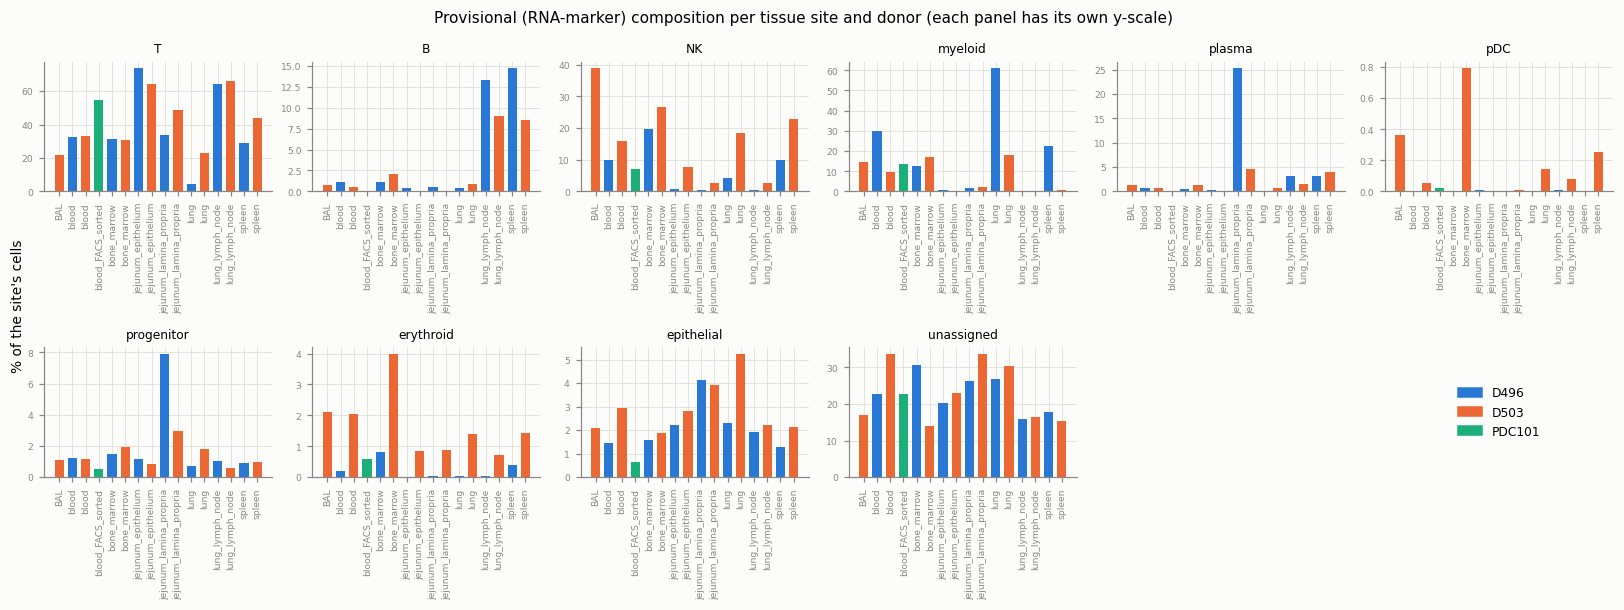

In [10]:
# Provisional composition per tissue site (fractions), small multiples per class, bars coloured by donor.
DONOR_COLOR_G = {"D496": PALETTE[0], "D503": PALETTE[1], "PDC101": PALETTE[2]}
sites = sorted(xt_g.columns, key=lambda s: (s.split()[1], s.split()[0]))
frac_g = xt_g[sites].div(xt_g[sites].sum(axis=0), axis=1) * 100
fig, axes = plt.subplots(2, 6, figsize=(15, 5.6))
for ax, t in zip(axes.ravel(), PROV_ORDER):
    ax.bar(range(len(sites)), frac_g.loc[t].to_numpy(), width=0.7, color=[DONOR_COLOR_G[s.split()[0]] for s in sites])
    ax.set_title(t, fontsize=8); ax.set_xticks(range(len(sites)), [s.split()[1] for s in sites], rotation=90)
    ax.tick_params(labelsize=6)
for ax in axes.ravel()[len(PROV_ORDER):]:
    ax.axis("off")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in DONOR_COLOR_G.values()]
axes.ravel()[-1].legend(handles, DONOR_COLOR_G.keys(), fontsize=8, loc="center")
fig.supylabel("% of the site's cells", fontsize=9)
fig.suptitle("Provisional (RNA-marker) composition per tissue site and donor (each panel has its own y-scale)", fontsize=10)
fig.tight_layout(); plt.show()

**Label observations**
* **PDC101 sort gates:** 8 classes with 1,031 (CD8 TEMRA) to 1,823 (CD8 TEM) cells, imbalance below 2×: a balanced,
  fine-grained T-subset task. Three gates (CD4 naive, CD8 naive, monocytes) have a direct counterpart among Zheng's
  populations (cross-dataset section).
* **The provisional rule reproduces the coarse sort lineages, not the subsets:** 72.1–77.2% of the CD4 gates and 73.1%
  of CD8 naive cells are called T, and 84.5% of the monocytes myeloid; most of the rest is `unassigned` (12.4–36.7%).
  **CD8 effector gates drift to NK** (CD8 TCM 8.4%, TEM 16.2%, TEMRA 26.1% called NK): cytotoxic CD8 T cells express
  NKG7/GNLY/KLRD1 (G.6), the NK markers of the rule. Any RNA-marker annotation will confuse CD8 TEMRA with NK cells.
* **Provisional composition over all cells:** T 38.8%, myeloid 13.9%, NK 13.3%, B 3.9%, plasma 2.5%, progenitor (CD34)
  1.5%, pDC 0.14% (311 cells), plus two doubtful classes, epithelial 2.4% and erythroid 1.1% (G.6 shows they are T-like in
  protein, i.e. ambient KRT8/HBB reads rather than real epithelial cells or erythrocytes), and 22.4% unassigned.
* **Composition follows the tissue:** D496 lung is 61.2% myeloid (presumably alveolar macrophages), jejunum epithelium
  64.6–73.9% T (intraepithelial lymphocytes), lung lymph node 64.0–66.4% T with 9.0–13.3% B, D496 lamina propria 25.3%
  plasma cells, D503 BAL 39.0% NK.
* **The same tissue differs between donors:** D496 lung 4.2% T / 61.2% myeloid vs D503 lung 23.0% T / 17.9% myeloid;
  lamina propria 25.3% plasma cells in D496 vs 4.7% in D503. Donor and tissue are crossed in G (7 shared sites), a batch
  structure none of A–F has.

## G.4 Per-cell quality metrics: RNA (UMIs, genes, %MT) and protein (ADT totals, isotype controls)
10x 3' v3.1 with UMIs, so library size is a UMI count. All metrics are computed on all cells (streamed in G.0).

In [11]:
qc_g = obs_g[["total_counts", "n_genes", "pct_mt", "top_gene_frac", "adt_total", "isotype_pct"]]
display(qc_g.describe().round(3).T)
print("Medians per tissue site:")
display(obs_g.groupby(SITE.to_numpy())[["total_counts", "n_genes", "pct_mt", "adt_total", "isotype_pct"]].median().round(1)
        .assign(n_cells=SITE.value_counts()).loc[sites])
SHARED_G = ((obs_g.n_genes >= 500) & (obs_g.total_counts >= 1000)).to_numpy()
thr = [0, 200, 500, 1000, 2000, 5000]
display(pd.DataFrame({"cells with >= t UMIs": [(obs_g.total_counts >= t).sum() for t in thr],
                      "cells with >= t genes": [(obs_g.n_genes >= t).sum() for t in thr]}, index=thr).T)
print(f"Cells passing the shared rule (>= 500 genes and >= 1,000 UMIs): {SHARED_G.sum()} of {N_g}; per sample (%):",
      (pd.Series(SHARED_G).groupby(obs_g["sample"].to_numpy()).mean() * 100).round(2).to_dict())
print("Cells with %MT > 10 / > 20 / > 50:", int((obs_g.pct_mt > 10).sum()), "/", int((obs_g.pct_mt > 20).sum()), "/", int((obs_g.pct_mt > 50).sum()))
print("Median %MT by provisional label:", obs_g.groupby("prov_label").pct_mt.median().round(2).to_dict())
r_rna_adt = spearmanr(obs_g.total_counts, obs_g.adt_total)[0]
r_iso = spearmanr(obs_g.isotype_total, obs_g.adt_total)[0]
print(f"Spearman correlation across cells: RNA UMIs vs ADT total {r_rna_adt:.2f} | isotype total vs ADT total {r_iso:.2f}")
print("Cells with isotype share > 2% / > 5% of their ADT counts:", int((obs_g.isotype_pct > 2).sum()), "/", int((obs_g.isotype_pct > 5).sum()))
adt_share = pd.Series(np.asarray(adt_g.X.sum(0)).ravel() / adt_g.X.sum() * 100, index=adt_g.var_names).sort_values(ascending=False)
print("Top-10 ADTs by share of all ADT counts (%):", adt_share.head(10).round(2).to_dict())

,count,mean,std,min,25%,50%,75%,max
total_counts,223390.0,7934.315,9101.812,501.000,4075.000,5435.000,7404.000,176072.000
n_genes,223390.0,2277.756,1292.607,26.000,1591.000,2025.000,2587.000,13828.000
pct_mt,223390.0,9.613,11.986,0.000,5.202,7.119,9.441,99.346
top_gene_frac,223390.0,0.062,0.054,0.008,0.038,0.051,0.067,0.838
adt_total,223390.0,1070.456,2032.761,5.000,291.000,566.000,1076.000,228005.000
isotype_pct,223390.0,0.191,0.269,0.000,0.000,0.097,0.298,5.864


Medians per tissue site:


,total_counts,n_genes,pct_mt,adt_total,isotype_pct,n_cells
D503 BAL,5224.0,2098.0,7.0,315.0,0.1,20349
D496 blood,6119.0,2276.0,9.0,958.0,0.1,8081
D503 blood,5320.0,1757.0,5.4,311.0,0.0,17934
PDC101 blood_FACS_sorted,3675.0,1014.0,4.0,1203.0,0.3,10487
D496 bone_marrow,5635.0,2277.0,8.9,965.0,0.1,12350
D503 bone_marrow,5690.0,2109.0,6.0,341.5,0.1,19754
D496 jejunum_epithelium,4913.0,2063.0,9.0,909.0,0.1,8200
D503 jejunum_epithelium,4588.5,1830.0,7.7,277.0,0.0,10848
D496 jejunum_lamina_propria,5595.0,2224.0,6.9,1296.0,0.1,8849
D503 jejunum_lamina_propria,4698.0,1780.0,6.9,314.0,0.1,13203


,0,200,500,1000,2000,5000
cells with >= t UMIs,223390,223390,223390,216817,208024,129776
cells with >= t genes,223390,220025,215448,201663,115183,12106


Cells passing the shared rule (>= 500 genes and >= 1,000 UMIs): 214598 of 223390; per sample (%): {'D496': 96.86, 'D503': 95.22, 'PDC101': 99.15}
Cells with %MT > 10 / > 20 / > 50: 46842 / 12315 / 4604
Median %MT by provisional label: {'B': 8.35, 'NK': 7.39, 'T': 6.18, 'epithelial': 7.28, 'erythroid': 6.57, 'myeloid': 8.32, 'pDC': 4.97, 'plasma': 4.69, 'progenitor': 6.74, 'unassigned': 8.13}


Spearman correlation across cells: RNA UMIs vs ADT total 0.40 | isotype total vs ADT total 0.44
Cells with isotype share > 2% / > 5% of their ADT counts: 246 / 5
Top-10 ADTs by share of all ADT counts (%): {'anti-human_CD9': 7.130000114440918, 'anti-human_IgG_Fc': 2.6600000858306885, 'anti-human_HLA-DR_DP_DQ': 2.5999999046325684, 'anti-human_CD206_(MMR)': 2.130000114440918, 'anti-human_CD69': 2.059999942779541, 'anti-human_CD5': 2.0199999809265137, 'anti-human_CD163': 2.0199999809265137, 'anti-human_CD58_(LFA-3)': 1.75, 'anti-human_CD31': 1.6200000047683716, 'anti-human_CD71': 1.5700000524520874}


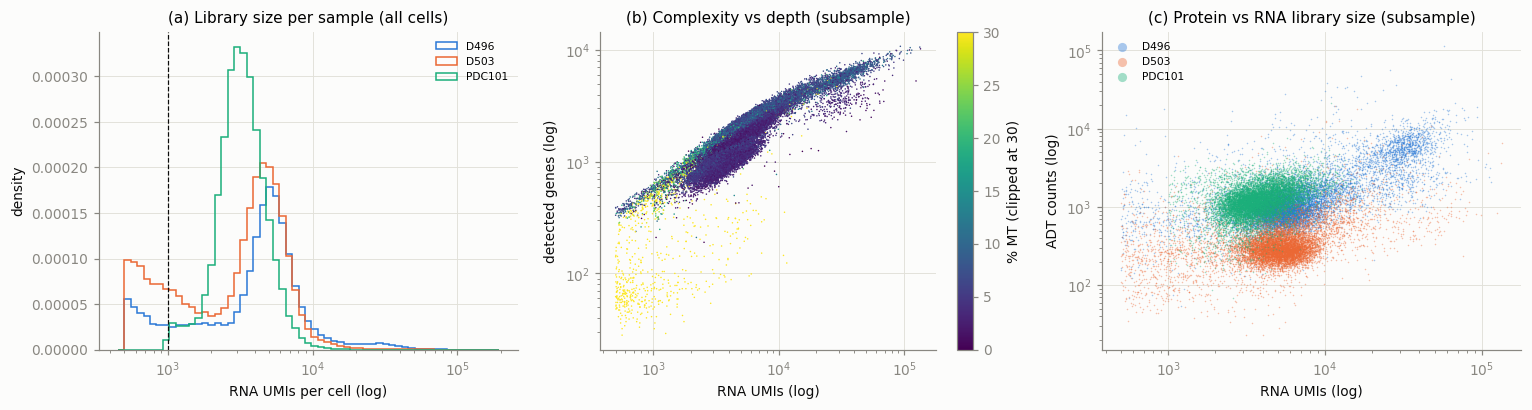

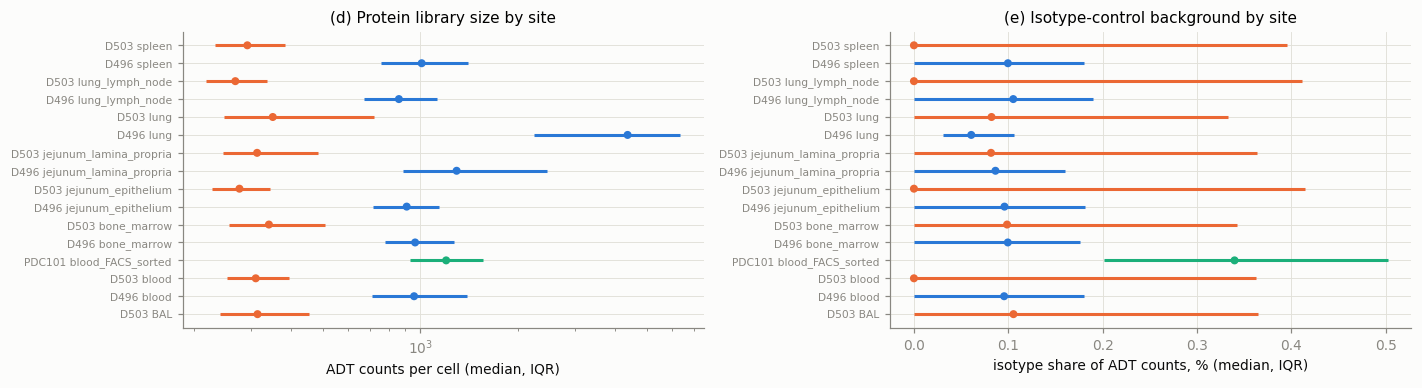

In [12]:
pidx = gsub.obs_names                                     # plot on the fixed subsample to keep the figure light
q = obs_g.loc[pidx]
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
bins = np.logspace(np.log10(obs_g.total_counts.min() * 0.9), np.log10(obs_g.total_counts.max() * 1.1), 60)
for s, c in DONOR_COLOR_G.items():
    axes[0].hist(obs_g.loc[obs_g["sample"] == s, "total_counts"], bins=bins, histtype="step", lw=1.5, color=c, label=s, density=True)
axes[0].axvline(1000, color=INK, lw=0.8, ls="--")
axes[0].set_xscale("log"); axes[0].set_xlabel("RNA UMIs per cell (log)"); axes[0].set_ylabel("density")
axes[0].set_title("(a) Library size per sample (all cells)"); axes[0].legend(fontsize=7)
sca = axes[1].scatter(q.total_counts, q.n_genes, c=q.pct_mt.clip(upper=30), s=1, cmap="viridis", linewidths=0, rasterized=True)
fig.colorbar(sca, ax=axes[1], label="% MT (clipped at 30)")
axes[1].set_xscale("log"); axes[1].set_yscale("log"); axes[1].set_xlabel("RNA UMIs (log)"); axes[1].set_ylabel("detected genes (log)")
axes[1].set_title("(b) Complexity vs depth (subsample)")
for s, c in DONOR_COLOR_G.items():
    m = (q["sample"] == s).to_numpy()
    axes[2].scatter(q.total_counts[m], q.adt_total[m], s=1, alpha=0.4, color=c, label=s, linewidths=0, rasterized=True)
axes[2].set_xscale("log"); axes[2].set_yscale("log"); axes[2].set_xlabel("RNA UMIs (log)"); axes[2].set_ylabel("ADT counts (log)")
axes[2].set_title("(c) Protein vs RNA library size (subsample)"); axes[2].legend(markerscale=6, fontsize=7)
fig.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
g = obs_g.groupby(SITE.to_numpy())
for ax, col, lab in [(axes[0], "adt_total", "ADT counts per cell (median, IQR)"), (axes[1], "isotype_pct", "isotype share of ADT counts, % (median, IQR)")]:
    med, q1, q3 = g[col].median()[sites], g[col].quantile(.25)[sites], g[col].quantile(.75)[sites]
    y = np.arange(len(sites)); cols_ = [DONOR_COLOR_G[s.split()[0]] for s in sites]
    ax.hlines(y, q1, q3, color=cols_, lw=2); ax.scatter(med, y, color=cols_, s=18, zorder=3)
    ax.set_yticks(y, sites, fontsize=7); ax.set_xlabel(lab)
axes[0].set_xscale("log"); axes[0].set_title("(d) Protein library size by site"); axes[1].set_title("(e) Isotype-control background by site")
fig.tight_layout(); plt.show()

**QC observations**
* **The deposited cells are pre-filtered on UMIs only.** Every cell has ≥ 501 UMIs, but panel (a) shows a low-depth
  shoulder (500–1,000 UMIs) in both donors that PDC101 lacks, and panel (b) a group of cells with few genes and very high
  %MT (yellow). **4,604 cells have > 50% mitochondrial UMIs** (12,315 > 20%, 46,842 > 10%) and 3,365 cells have fewer than
  200 genes: dying cells or near-empty droplets that a UMI cut alone leaves in.
* The shared rule (≥ 500 genes, ≥ 1,000 UMIs) keeps 214,598 of 223,390 cells (96.86% D496, 95.22% D503, 99.15% PDC101).
  **Unlike in the pancreas datasets, %MT is usable here:** median 7.1%, and similar across provisional labels (medians
  4.7–8.4%), so a %MT ceiling would not remove one cell type preferentially (Xin and Lawlor: beta-cell bias).
* **RNA depth is similar across sites except D496 lung** (median 24,104.5 UMIs, 4,879 genes, 4,367 ADT counts, vs
  4,588.5–6,144 UMIs at the other donor sites). Its cells are mostly myeloid (G.3), which are larger and RNA-rich.
  PDC101 is shallower (median 3,675 UMIs, 1,014 genes).
* **Protein depth is a donor effect:** median ADT counts per cell are 860–1,296 at D496 sites (4,367 in lung) vs
  269–351 at D503 sites, at similar RNA depth (panel d). RNA and ADT totals correlate only moderately across cells
  (Spearman 0.40, panel c).
* **Isotype background is low:** median 0.10% of a cell's ADT counts (maximum 5.9%; 246 cells > 2%, 5 cells > 5%),
  highest in PDC101 (median 0.3%). The isotype total follows the ADT total (Spearman 0.44), as expected for non-specific
  binding, so the isotypes can serve as a per-cell background estimate (e.g. for DSB normalisation) but do not flag a
  bad sample.
* **A few tags dominate the protein counts:** CD9 alone is 7.1% of all ADT counts, then IgG Fc, HLA-DR/DP/DQ, CD206,
  CD69, CD5 and CD163 (2.0–2.7% each).

## G.5 Gene-level behaviour: detection, top genes, mean–variance relationship
Computed on all cells and all genes from the streamed per-gene sums (G.0); same outputs as `gene_level()`.

Genes detected in at most k cells:
  <=  0 cells: 10203  (16.8%)
  <=  2 cells: 14386  (23.7%)
  <=  9 cells: 19103  (31.5%)
  <= 19 cells: 21863  (36.0%)
  <= 49 cells: 25733  (42.4%)

Top-15 genes by share of all UMIs (%):
MALAT1     3.49
IGKC       1.89
FTL        1.29
MT-CO2     1.29
MT-RNR2    1.01
MT-CO3     1.00
B2M        0.75
MT-CO1     0.74
EEF1A1     0.74
MT-CYB     0.69
RPLP1      0.68
MT-ND4     0.68
MT-ATP6    0.68
TPT1       0.63
TMSB4X     0.54


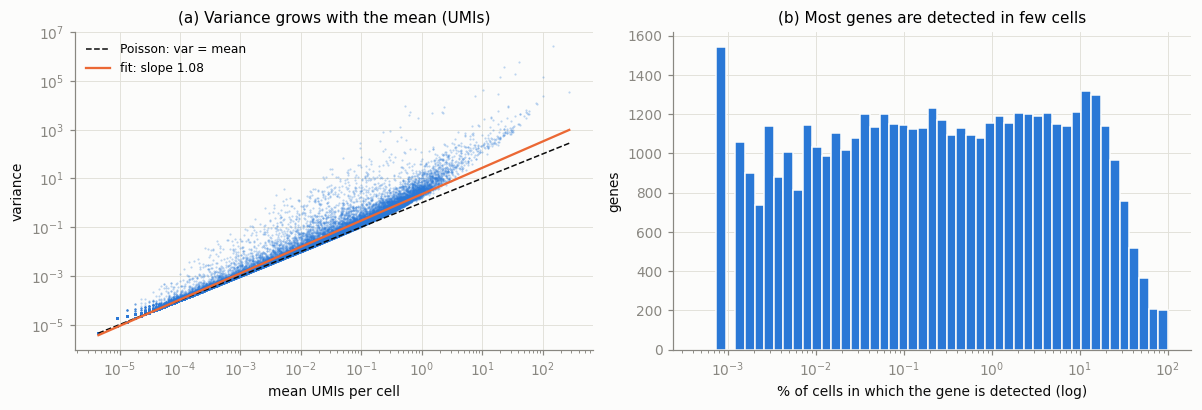

Fitted log-log slope of variance vs mean: 1.08


In [13]:
n_expr_g = gstats_g["n_cells"].to_numpy()
mean_g = gstats_g["sum"].to_numpy() / N_g
var_gl = gstats_g["sumsq"].to_numpy() / N_g - mean_g ** 2
print("Genes detected in at most k cells:")
for k in [0, 2, 9, 19, 49]:
    print(f"  <= {k:>2} cells: {(n_expr_g <= k).sum():>5}  ({100 * (n_expr_g <= k).mean():.1f}%)")
top_g = pd.Series(gstats_g["sum"].to_numpy() / gstats_g["sum"].sum() * 100, index=var_g.symbol.values).sort_values(ascending=False).head(15)
print("\nTop-15 genes by share of all UMIs (%):"); print(top_g.round(2).to_string())
slope_g = plot_gene_level(n_expr_g, mean_g, var_gl, N_g, "UMIs")
print(f"Fitted log-log slope of variance vs mean: {slope_g:.2f}")

**Gene-level observations** (all 223,390 cells, 60,725 genes)
* **Log-log slope 1.08**, the same as Baron's inDrop UMIs (≈ 1.1) and below every full-length dataset (1.4–1.5): 10x UMI
  counts are only mildly overdispersed.
* **Top genes:** MALAT1 3.49%, IGKC 1.89% (plasma cells), FTL 1.29%, and **seven mitochondrial transcripts among the top
  15** (MT-CO2, MT-RNR2, MT-CO3, MT-CO1, MT-CYB, MT-ND4, MT-ATP6), plus B2M, EEF1A1, RPLP1, TPT1 and TMSB4X. No single gene
  dominates the way the hormones did in pancreas.
* **Detection:** 16.8% of genes are never detected, 31.5% in fewer than 10 cells and 42.4% in fewer than 50, mostly the
  non-coding and pseudogene part of GENCODE. With 223k cells, "fewer than 10 cells" is a much weaker criterion than in
  A–F.

## G.6 Labels vs markers, and do protein and RNA agree?
Three checks: (1) the provisional **RNA** labels against the **protein** (independent modality, all cells), with the
RNA marker panel alongside for scale (subsample; partly the calling markers, so partly circular); (2) the **FACS sort
gates** of PDC101 against the gating proteins and the RNA markers of T-cell subsets; (3) protein vs RNA for the same
gene product, cell by cell, on the in-memory subsample (G.0).

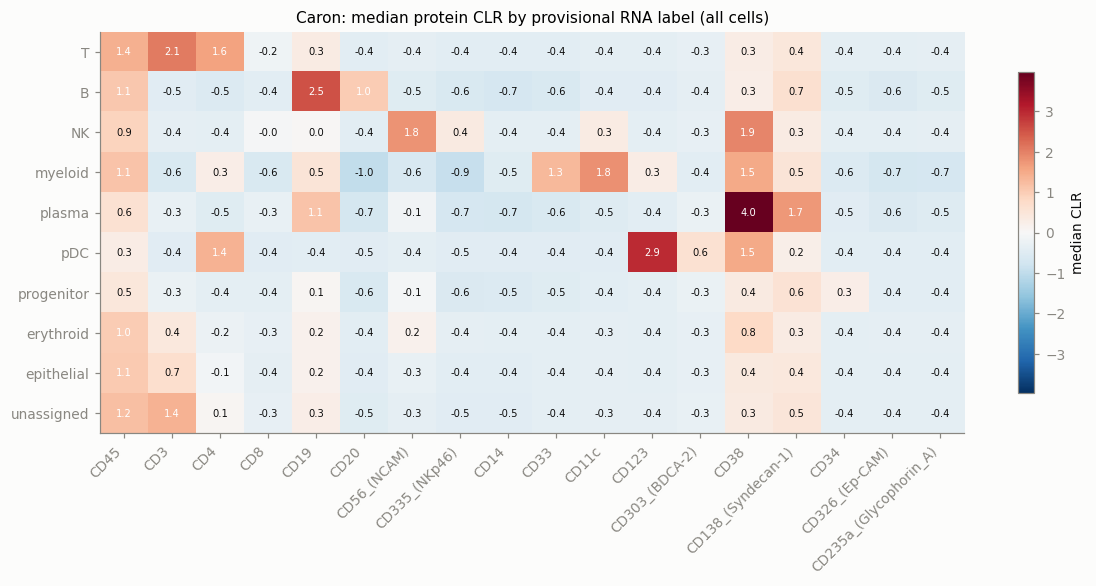

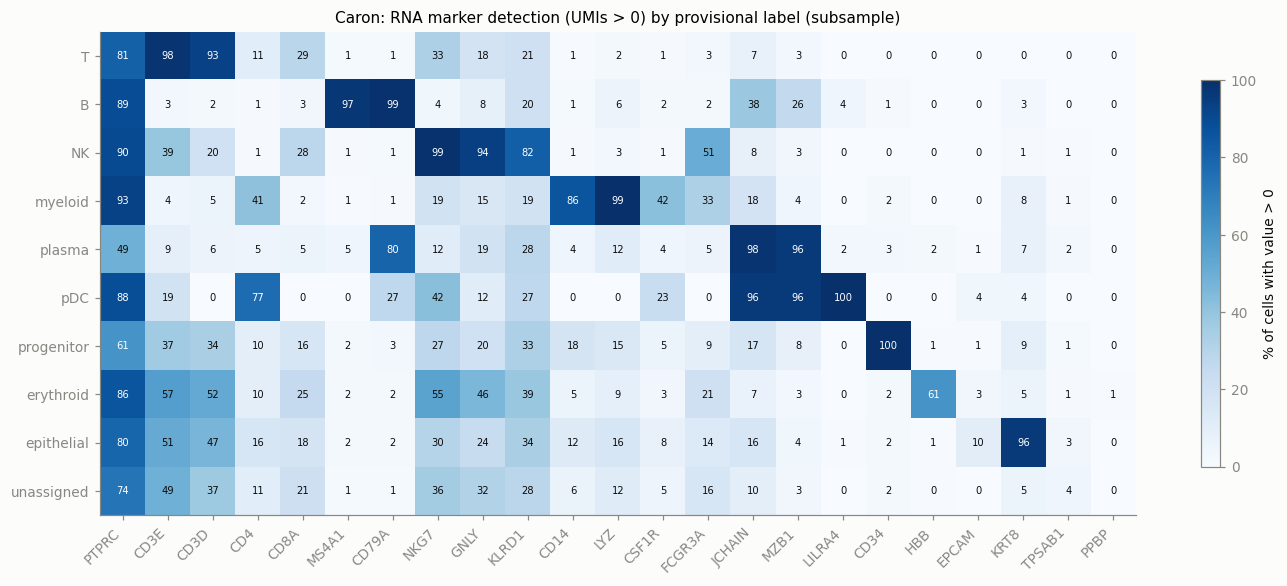

Panel markers not present (exactly once) in this dataset: []


In [14]:
# (1a) The provisional labels come from RNA markers, so the independent check is the protein: median CLR of lineage
# proteins per provisional label, over all cells.
C_g = clr(adt_g.X.toarray())                                            # per-cell CLR, cells x ADTs, float32
adt_names_g = adt_g.var["name"].astype(str).to_numpy()
LINEAGE_PROT = ["anti-human_CD45", "anti-human_CD3", "anti-human_CD4", "anti-human_CD8", "anti-human_CD19", "anti-human_CD20",
                "anti-human_CD56_(NCAM)", "anti-human_CD335_(NKp46)", "anti-human_CD14", "anti-human_CD33", "anti-human_CD11c",
                "anti-human_CD123", "anti-human_CD303_(BDCA-2)", "anti-human_CD38", "anti-human_CD138_(Syndecan-1)",
                "anti-human_CD34", "anti-human_CD326_(Ep-CAM)", "anti-human_CD235a_(Glycophorin_A)"]
med_lin = pd.DataFrame({n.replace("anti-human_", ""): pd.Series(C_g[:, adt_names_g == n].mean(1)).groupby(ct_g.to_numpy()).median()
                        for n in LINEAGE_PROT}).loc[PROV_ORDER]
value_heatmap(med_lin, "Caron: median protein CLR by provisional RNA label (all cells)", "median CLR", cmap="RdBu_r",
              vmin=-np.abs(med_lin.values).max(), vmax=np.abs(med_lin.values).max(), fmt="{:.1f}", center_white=1.0)
# (1b) RNA markers by provisional label on the subsample (partly the calling markers, so partly circular; shown for scale).
L_g = lognorm(gsub.X)
ct_sub = obs_g.loc[gsub.obs_names, "prov_label"].astype(str)
PROV_ORDER_SUB = [t for t in PROV_ORDER if t in set(ct_sub)]
detect_g = detection_heatmap(gsub, IMMUNE_CHECK, ct_sub, PROV_ORDER_SUB,
                             "Caron: RNA marker detection (UMIs > 0) by provisional label (subsample)")
missing = [g for g in IMMUNE_CHECK + TSUBSET_RNA if (gsub.var["symbol"] == g).sum() != 1]
print("Panel markers not present (exactly once) in this dataset:", missing)

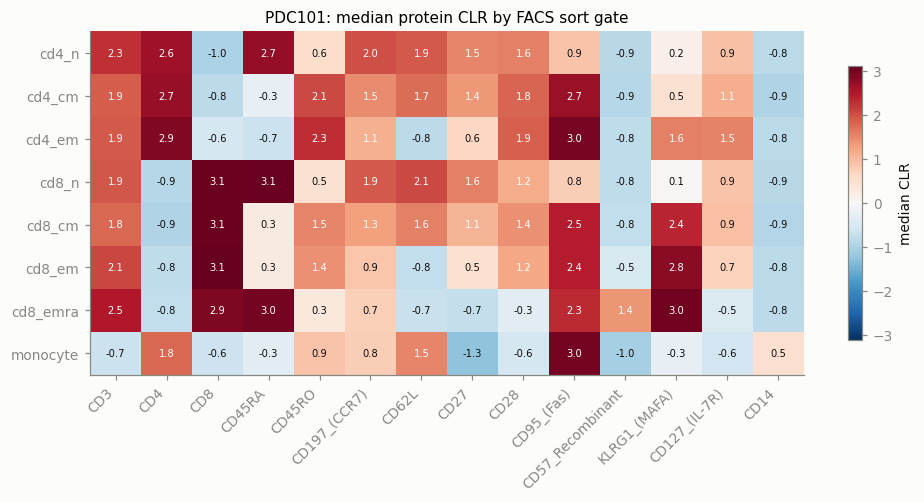

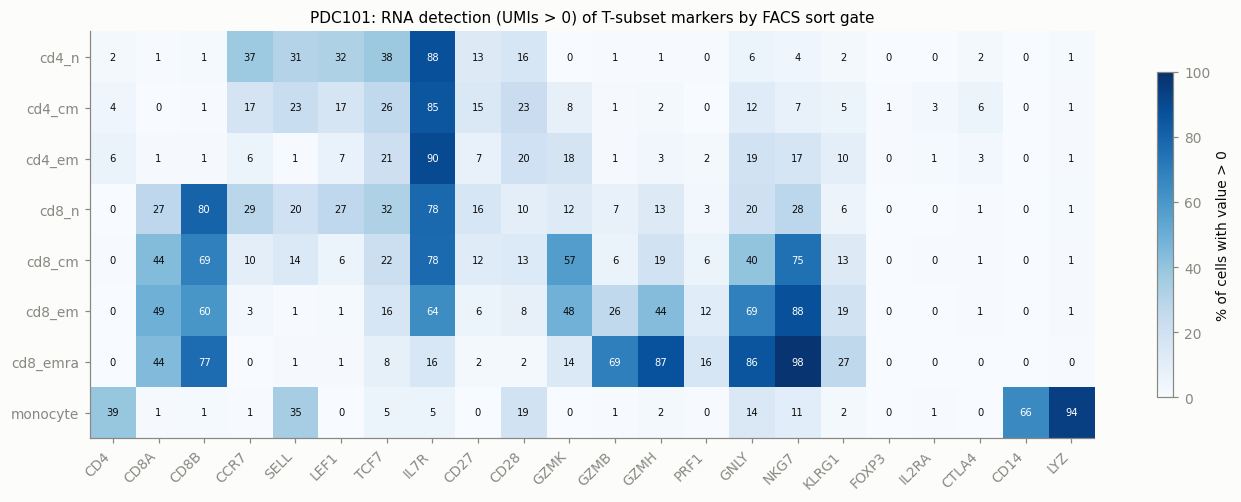

In [15]:
# (2) PDC101: FACS sort gates against the gating proteins (median CLR) and T-subset RNA markers (detection %).
GATE_ORDER = ["cd4_n", "cd4_cm", "cd4_em", "cd8_n", "cd8_cm", "cd8_em", "cd8_emra", "monocyte"]
GATE_PROT = ["anti-human_CD3", "anti-human_CD4", "anti-human_CD8", "anti-human_CD45RA", "anti-human_CD45RO",
             "anti-human_CD197_(CCR7)", "anti-human_CD62L", "anti-human_CD27", "anti-human_CD28", "anti-human_CD95_(Fas)",
             "anti-human_CD57_Recombinant", "anti-human_KLRG1_(MAFA)", "anti-human_CD127_(IL-7R)", "anti-human_CD14"]
med_clr = pd.DataFrame({n.replace("anti-human_", ""): pd.Series(C_g[pdc][:, adt_names_g == n].mean(1), index=gate_g.index)
                        .groupby(gate_g.to_numpy()).median() for n in GATE_PROT}).loc[GATE_ORDER]
value_heatmap(med_clr, "PDC101: median protein CLR by FACS sort gate", "median CLR", cmap="RdBu_r",
              vmin=-np.abs(med_clr.values).max(), vmax=np.abs(med_clr.values).max(), fmt="{:.1f}", center_white=1.0)
pdc_sub = gsub.obs["sample"].to_numpy() == "PDC101"
gate_sub = gsub.obs.loc[pdc_sub, "sort_gate"].astype(str)
detect_gate = detection_heatmap(gsub[pdc_sub], TSUBSET_RNA, gate_sub, GATE_ORDER,
                                "PDC101: RNA detection (UMIs > 0) of T-subset markers by FACS sort gate")

,gene,RNA detected %,Spearman (CLR vs log RNA),"median CLR, RNA > 0","median CLR, RNA = 0"
protein,,,,,
CD127_(IL-7R),IL7R,57.91,0.71,1.14,-0.35
CD161,KLRB1,28.51,0.65,1.23,-0.37
CD3,CD3E,60.74,0.60,2.07,-0.38
CD8,CD8A,21.61,0.57,3.10,-0.36
CD7,CD7,47.42,0.50,1.31,-0.35
CD2,CD2,42.38,0.48,1.08,-0.14
CD11c,ITGAX,15.83,0.47,1.49,-0.45
CD163,CD163,11.40,0.47,3.09,-0.33
CD62L,SELL,23.88,0.46,1.80,-0.30


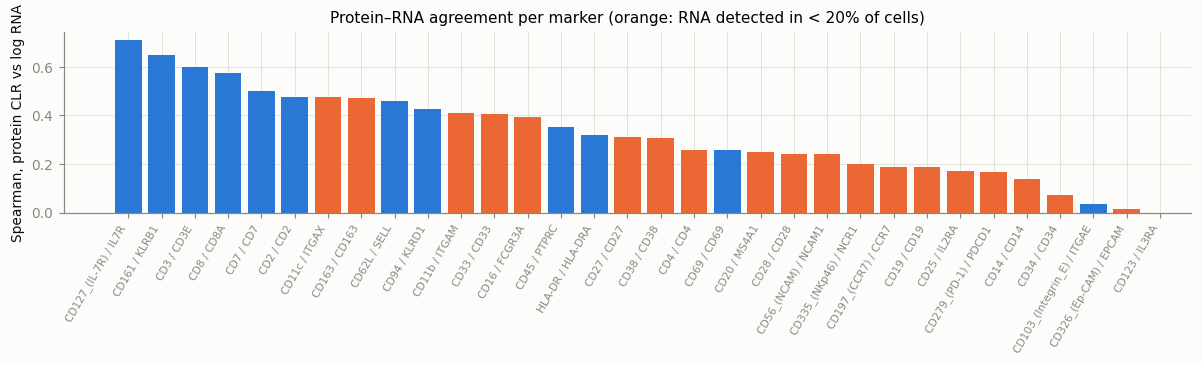

In [16]:
# (3) Protein vs RNA for the same gene product, cell by cell (subsample): Spearman of CLR vs log-normalised RNA.
PAIRS = {"anti-human_CD3": "CD3E", "anti-human_CD4": "CD4", "anti-human_CD8": "CD8A", "anti-human_CD19": "CD19",
         "anti-human_CD20": "MS4A1", "anti-human_CD14": "CD14", "anti-human_CD16": "FCGR3A", "anti-human_CD56_(NCAM)": "NCAM1",
         "anti-human_CD45": "PTPRC", "anti-human_CD197_(CCR7)": "CCR7", "anti-human_CD62L": "SELL",
         "anti-human_CD127_(IL-7R)": "IL7R", "anti-human_CD25": "IL2RA", "anti-human_CD27": "CD27", "anti-human_CD28": "CD28",
         "anti-human_CD38": "CD38", "anti-human_CD161": "KLRB1", "anti-human_CD11c": "ITGAX", "anti-human_CD33": "CD33",
         "anti-human_CD123": "IL3RA", "anti-human_CD34": "CD34", "anti-human_HLA-DR": "HLA-DRA",
         "anti-human_CD326_(Ep-CAM)": "EPCAM", "anti-human_CD279_(PD-1)": "PDCD1", "anti-human_CD69": "CD69",
         "anti-human_CD103_(Integrin_E)": "ITGAE", "anti-human_CD335_(NKp46)": "NCR1", "anti-human_CD94": "KLRD1",
         "anti-human_CD2": "CD2", "anti-human_CD7": "CD7", "anti-human_CD163": "CD163", "anti-human_CD11b": "ITGAM"}
sub_rows = obs_g.index.get_indexer(gsub.obs_names)
C_sub = C_g[sub_rows]                                  # CLR of the subsample cells
sym_sub = gsub.var.symbol.values
rows = []
for prot, gene in PAIRS.items():
    jg = np.flatnonzero(sym_sub == gene)
    if len(jg) != 1 or not (adt_names_g == prot).any():
        rows.append((prot.replace("anti-human_", ""), gene, np.nan, np.nan, np.nan, np.nan)); continue
    r = np.asarray(L_g[:, jg[0]].todense()).ravel()
    p = C_sub[:, adt_names_g == prot].mean(1)
    det = r > 0
    rows.append((prot.replace("anti-human_", ""), gene, 100 * det.mean(), spearmanr(p, r)[0],
                 np.median(p[det]) if det.any() else np.nan, np.median(p[~det])))
pr = pd.DataFrame(rows, columns=["protein", "gene", "RNA detected %", "Spearman (CLR vs log RNA)",
                                 "median CLR, RNA > 0", "median CLR, RNA = 0"]).set_index("protein").sort_values("Spearman (CLR vs log RNA)", ascending=False)
display(pr.round(2))
fig, ax = plt.subplots(figsize=(11, 3.4))
ax.bar(range(len(pr)), pr["Spearman (CLR vs log RNA)"], color=[PALETTE[0] if d >= 20 else PALETTE[1] for d in pr["RNA detected %"]])
ax.set_xticks(range(len(pr)), [f"{p} / {g}" for p, g in zip(pr.index, pr.gene)], rotation=60, ha="right", fontsize=7)
ax.set_ylabel("Spearman, protein CLR vs log RNA"); ax.set_title("Protein–RNA agreement per marker (orange: RNA detected in < 20% of cells)")
fig.tight_layout(); plt.show()

**Marker observations**
* **The protein supports the provisional RNA labels for the main lineages** (first heatmap, independent modality): T
  cells CD3 2.1 / CD4 1.6 (median CLR), B cells CD19 2.5 / CD20 1.0, NK cells CD56 1.8 / CD38 1.9, myeloid cells CD33 1.3
  / CD11c 1.8, plasma cells CD38 4.0 / CD138 1.7, pDC CD123 2.9 / CD4 1.4 / CD303 0.6. CD14 protein is low even in
  myeloid cells (median −0.5), so CD14 is a weak protein marker in these samples.
* **`epithelial`, `erythroid` and `unassigned` look like T/NK cells in both modalities:** CD3 protein 0.7 / 0.4 / 1.4 and
  CD3E mRNA in 51% / 57% / 49% of cells, while EpCAM and CD235a protein are negative in every group. They are lymphocytes
  with ambient KRT8 or HBB reads. `progenitor` (CD34 mRNA in 100%) has CD34 protein of only 0.3; in tissues these are
  more likely CD34+ endothelial or stromal cells than haematopoietic progenitors (they lie on the RNA PC2 arm with
  CALD1, DCN, MMP2, G.7).
* **PDC101: the sort gates are clean in protein** (second heatmap): CD4 vs CD8 by gate; CD45RA high in naive and TEMRA,
  CD45RO in the memory gates; CCR7 and CD62L high in naive and central memory, low in effector memory; CD27 and CD28 lost
  in TEMRA; CD95 high in the memory gates (2.3–3.0 vs 0.8–0.9 in naive); CD57 and KLRG1 highest in TEMRA (1.4, 3.0).
  These are the textbook gating definitions. Monocytes are CD3−, CD4 1.8, CD14 0.5.
* **In RNA the same gates are graded rather than separated** (third heatmap): CCR7, SELL, LEF1 and TCF7 fall from naive
  to effector, GZMK peaks in CD8 TCM/TEM (57% / 48%), and GZMB, GZMH, PRF1 and GNLY rise towards TEMRA (69 / 87 / 16 /
  86%). But **CD4 mRNA is detected in only 2–6% of the CD4 gates** (CD4 protein median CLR 2.6–2.9), and FOXP3 and IL2RA
  are essentially absent (≤ 3%). At this depth the protein is the only reliable readout for CD4 and several other
  gating markers.
* **Per-cell protein–RNA agreement is moderate and marker-dependent** (table and bar chart): Spearman 0.71 (CD127 /
  IL7R), 0.65 (CD161 / KLRB1), 0.60 (CD3 / CD3E), 0.57 (CD8 / CD8A), but ≤ 0.26 for CD4, CD20, CD56, CD28, CD69, NKp46,
  CCR7, CD19, CD25, PD-1, CD14, CD34, CD103 and EpCAM. Low agreement is mostly RNA dropout (MS4A1 detected in 3.9% of
  cells, NCAM1 3.5%, CD19 1.8%): where the mRNA is detected the protein is clearly higher (CD20 median CLR 0.64 vs −0.67;
  CD56 2.05 vs −0.44). CD103 / ITGAE (0.04) and CD14 (0.14) agree poorly even though the mRNA is often detected (25% and
  15%). CD123 / IL3RA could not be compared (IL3RA has a PAR-Y duplicate, G.2).

## G.7 Global structure: do cells group by type, donor or tissue, in RNA and in protein space?
RNA: the throw-away pipeline of A–F (normalise to 10k → log1p → 2,000 HVGs → z-score → PCA) on the subsample. Protein:
per-cell CLR → z-score → PCA on the 268 non-isotype ADTs. Silhouettes are computed on 20 PCs (on a seeded random
10,000-cell sample when there are more cells, see `silhouette()`). Inspection only.

In [17]:
P_g, evr_g, load_g = throwaway_pca(gsub)
iso = adt_g.var.is_isotype.to_numpy()

def adt_pca(Cm, n=30):
    t = ad.AnnData(X=Cm.astype(np.float32))
    sc.pp.scale(t, max_value=10)
    sc.tl.pca(t, n_comps=n, random_state=SEED)
    return t.obsm["X_pca"], t.uns["pca"]["variance_ratio"]

Pa_g, evra_g = adt_pca(C_sub[:, ~iso])
print(f"ADT PCA: PC1..PC5 explain {np.round(100 * evra_g[:5], 1)} %, 20 PCs {100 * evra_g[:20].sum():.1f}%")
lab_s, don_s, site_s = ct_sub.to_numpy(), gsub.obs["donor"].astype(str).to_numpy(), SITE.loc[gsub.obs_names].to_numpy()
known = lab_s != "unassigned"
org = gsub.obs["sample"].isin(["D496", "D503"]).to_numpy()
tiss_s = gsub.obs["tissue"].astype(str).to_numpy()
res = {}
for space, P in [("RNA", P_g), ("protein", Pa_g)]:
    res[space] = {"provisional label (assigned cells)": silhouette(P[known], lab_s[known]),
                  "donor/sample": silhouette(P, don_s),
                  "tissue (organ donors only)": silhouette(P[org], tiss_s[org]),
                  "tissue, within provisional T cells": silhouette(P[org & (lab_s == "T")], tiss_s[org & (lab_s == "T")]),
                  "donor, within provisional T cells (organ donors)": silhouette(P[org & (lab_s == "T")], don_s[org & (lab_s == "T")])}
display(pd.DataFrame(res).round(3))
for pc in load_g:
    print(f"RNA {pc} top +: {gsub.var.symbol[load_g[pc].nlargest(8).index].tolist()}\n        top -: {gsub.var.symbol[load_g[pc].nsmallest(8).index].tolist()}")

Explained variance, PC1..PC10 (%): [7.8 4.9 3.4 2.  1.7 1.5 1.3 1.2 1.1 0.9]
Cumulative variance in 20 / 50 PCs: 31.3% / 37.9%


ADT PCA: PC1..PC5 explain [15.3 10.   5.4  3.3  2.9] %, 20 PCs 51.2%


,RNA,protein
provisional label (assigned cells),0.244,0.068
donor/sample,0.079,0.184
tissue (organ donors only),-0.067,-0.024
"tissue, within provisional T cells",-0.032,-0.048
"donor, within provisional T cells (organ donors)",0.182,0.281


RNA PC1 top +: ['GRN', 'SERPINA1', 'CYBB', 'SPI1', 'CTSB', 'CD163', 'KLF4', 'LYZ']
        top -: ['CD8B', 'GZMA', 'GNLY', 'DNAJB1', 'CD8A', 'HOPX', 'GZMH', 'AC092580.4']
RNA PC2 top +: ['CALD1', 'NNMT', 'C1R', 'DCN', 'C1S', 'MMP2', 'TIMP3', 'C11orf96']
        top -: ['LYZ', 'AIF1', 'SPI1', 'S100A9', 'CSTA', 'LST1', 'S100A8', 'CYBB']


In [18]:
# PDC101 alone: are the FACS sort gates separated in RNA space, in protein space, or both? (PCA fitted on PDC101 only)
pdc_ad = gsub[pdc_sub].copy()
P_pr, _, _ = throwaway_pca(pdc_ad)
P_pp, _ = adt_pca(C_sub[pdc_sub][:, ~iso])
gs = gate_sub.to_numpy(); tmask = gs != "monocyte"
cd4 = np.isin(gs, ["cd4_n", "cd4_cm", "cd4_em"]); cd8 = np.isin(gs, ["cd8_n", "cd8_cm", "cd8_em", "cd8_emra"])
pdc_res = pd.DataFrame({sp_: {"all 8 gates": silhouette(P, gs), "7 T-cell gates": silhouette(P[tmask], gs[tmask]),
                              "CD4 gates (n/cm/em)": silhouette(P[cd4], gs[cd4]), "CD8 gates (n/cm/em/emra)": silhouette(P[cd8], gs[cd8]),
                              "CD4 vs CD8 (T cells)": silhouette(P[tmask], np.where(cd4, "CD4", "CD8")[tmask])}
                        for sp_, P in [("RNA", P_pr), ("protein", P_pp)]})
display(pdc_res.round(3))

Explained variance, PC1..PC10 (%): [10.8  1.8  0.7  0.7  0.5  0.4  0.3  0.3  0.3  0.3]
Cumulative variance in 20 / 50 PCs: 18.1% / 23.5%


,RNA,protein
all 8 gates,0.076,0.123
7 T-cell gates,0.003,0.060
CD4 gates (n/cm/em),0.063,0.112
CD8 gates (n/cm/em/emra),0.046,0.077
CD4 vs CD8 (T cells),0.123,0.138


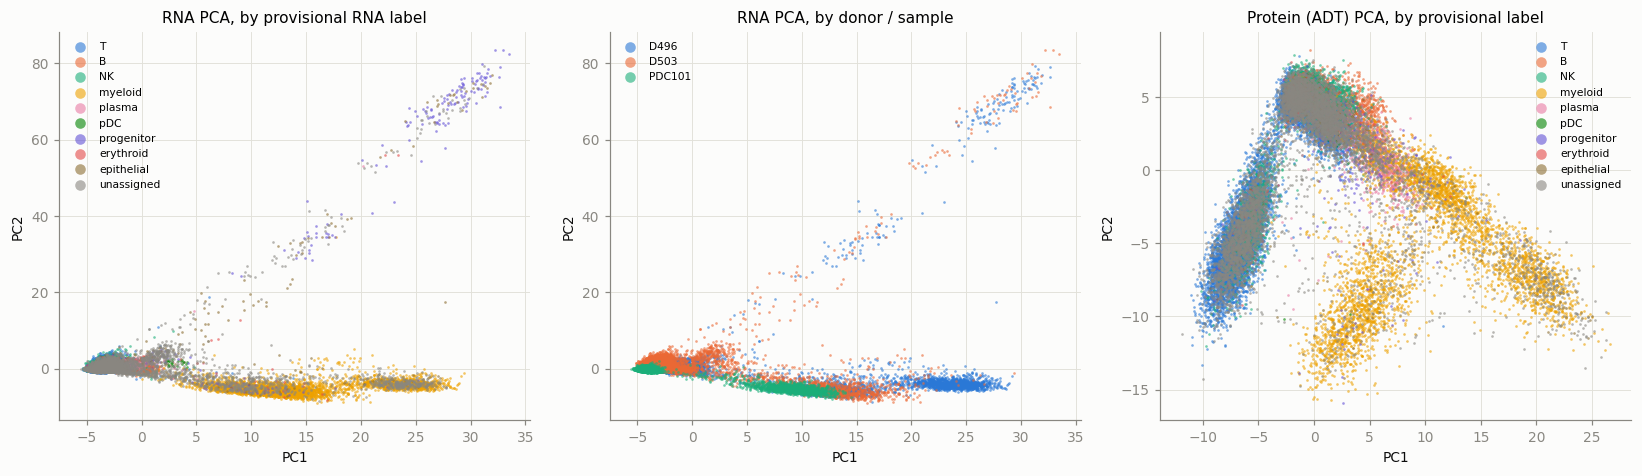

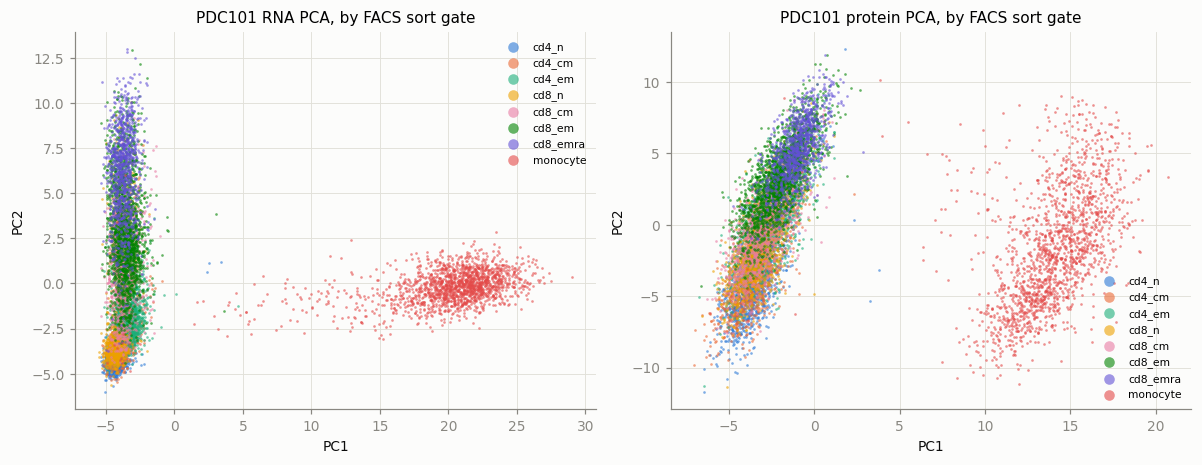

In [19]:
PROV_COLOR = dict(zip([t for t in PROV_ORDER if t != "unassigned"], PALETTE + ["#8c6d31", "#3b9ab2"])) | {"unassigned": MUTED}
rng = np.random.default_rng(SEED)
perm_g = rng.permutation(gsub.n_obs)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
scatter_groups(axes[0], P_g, lab_s, PROV_COLOR, "RNA PCA, by provisional RNA label", perm_g)
scatter_groups(axes[1], P_g, don_s, DONOR_COLOR_G, "RNA PCA, by donor / sample", perm_g)
scatter_groups(axes[2], Pa_g, lab_s, PROV_COLOR, "Protein (ADT) PCA, by provisional label", perm_g)
fig.tight_layout(); plt.show()
GATE_COLOR = dict(zip(GATE_ORDER, PALETTE))
perm_p = rng.permutation(len(gs))
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
scatter_groups(axes[0], P_pr, gs, GATE_COLOR, "PDC101 RNA PCA, by FACS sort gate", perm_p)
scatter_groups(axes[1], P_pp, gs, GATE_COLOR, "PDC101 protein PCA, by FACS sort gate", perm_p)
fig.tight_layout(); plt.show()

**Structure observations**
* **RNA: the provisional label dominates** (silhouette 0.244 on assigned cells; partly circular, since the labels come
  from RNA markers), donor/sample 0.079, tissue −0.067. PC1 (7.8%) separates myeloid cells (GRN, SERPINA1, CYBB, SPI1,
  CD163, LYZ) from cytotoxic lymphocytes (CD8A/B, GZMA, GZMH, GNLY); PC2 (4.9%) is a small stromal/endothelial-like arm
  (CALD1, NNMT, DCN, MMP2, C1R/C1S), mostly D496 cells, where the provisional `progenitor` and `epithelial` cells sit. 20
  PCs hold 31.3% of the variance.
* **Protein: the donor effect is larger than the label effect** (silhouette 0.184 by donor vs 0.068 by provisional
  label); within provisional T cells the donor silhouette is 0.281 in protein vs 0.182 in RNA. This is the 3× ADT depth
  difference of G.4 surviving per-cell CLR. A protein-based classifier across donors needs per-batch ADT normalisation;
  the MMoCHi paper itself uses landmark registration for this (SOFT summary).
* **Tissue is not a major axis within a cell type** (silhouette −0.032 / −0.048 within provisional T cells in RNA /
  protein): the tissue differences of G.3 are mostly composition, not a strong expression shift at this resolution.
* **PDC101: the sort gates are better separated in protein than in RNA** (PCA fitted on PDC101 alone): silhouette over
  all 8 gates 0.123 vs 0.076, over the 7 T-cell gates 0.060 vs 0.003, CD4 gates 0.112 vs 0.063, CD8 gates 0.077 vs
  0.046. In RNA, monocytes separate along PC1 (10.8%) and the T gates form one continuum; in protein, the T gates are
  ordered along a clear naive → effector gradient. The 7 T-subset labels are **protein-defined classes that RNA only
  partly recovers**, which is the problem MMoCHi addresses and a hard target for an RNA-only annotator.

## G.8 Summary of the Caron inspection

| aspect | Caron (GSE229791) |
|---|---|
| cells × features | 223,390 × 60,725 genes (GENCODE v24) + 277 ADTs (9 isotype controls); PDC101 also 14 hashtag counts |
| technology | CITE-seq + cell hashing, 10x 3' v3.1, UMIs; TotalSeq-A Human Universal Cocktail |
| values available | **raw UMI counts** (RNA) and raw ADT counts (protein), separate files, same cells (checked) |
| labels | **not in GEO**; FACS sort gates for PDC101 (8 classes, 10,487 cells); tissue for the organ donors; provisional RNA labels here (not ground truth) |
| missing values | none |
| prior QC | UMI threshold only (min 501 / 1,008 UMIs); 4,604 cells with > 50% MT still present |
| MT genes | present (37, `MT-`); median %MT 7.1, not type-biased |
| classes | sort gates 1,031–1,823 cells each; provisional: T, myeloid, NK, B, plasma, progenitor, pDC (+ doubtful epithelial / erythroid) |
| batch structure | 2 organ donors × 7–8 tissue sites + 1 volunteer, 34 10x lanes; strong donor effect in protein (3× ADT depth) |
| notable | protein separates T subsets better than RNA; CD4 mRNA in 2–6% of CD4 T cells; ADT and GEX columns in different order |

## G.9 Proposed preprocessing for Caron (for discussion)
Same rules R1–R5 as in `data_preview.ipynb` Part 2; only what is specific to Caron is listed.

* **Step 0 — labels (decision needed first).** GEO has no annotation for the 212,903 organ-donor cells. Options: (a)
  obtain the MMoCHi annotations from the authors / paper resources and use G as a large multi-tissue labelled set; (b)
  use **only PDC101** (10,487 cells, 8 FACS gates) as a labelled T-subset + monocyte set, closely matched to Zheng's
  sorted populations (H); (c) use the organ-donor cells unlabelled (tissue shift / open set). The provisional labels of
  this notebook must not be used for evaluation.
* **Step A — cell filtering (R4).** The shared rule removes 8,792 cells. %MT is measurable and not type-biased here, so a
  %MT ceiling (e.g. 20%, which would remove at most 12,315 cells) is a candidate dataset-specific rule. Hashtag singlet
  calling removed doublets between samples, not within a sample.
* **Step B — genes (R2, R5).** Restrict to detected genes; sum or drop the duplicated small-RNA symbols and the PAR-Y
  (`ENSGR`) copies before any symbol intersection. G shares 19,532 symbols with Baron and 20,809 with Zheng.
* **Step C — normalisation (R3).** RNA: `normalize_total` (10,000) + `log1p` on the UMI counts, as for Baron; no
  deviation. Protein, if used: CLR (or DSB with the isotype controls) **per donor/batch**, because ADT depth differs 3×
  between donors (G.4, G.7).
* **Step D — modality (decision needed).** RNA only (comparable with A–F and H) or RNA + protein? For RNA-only methods,
  G's T-subset labels are much harder than their FACS origin suggests (G.7).
* **Role in the study:** the first immune dataset with **tissue as a shift axis** (blood → tissue, crossed with donor);
  a FACS-labelled T-subset set that pairs with H (**H → G-PDC101: FACS-defined labels on both sides, different chemistry,
  era and donor**); and the only multimodal dataset.

In [20]:
# Keep what the cross-dataset section needs, free the large G objects before loading H.
sym_set_g = set(var_g.symbol[var_g.n_cells > 0])
sym_set_g_all = set(var_g.symbol)
g_summary = {"cells": N_g, "genes": G_g, "adts": adt_g.n_vars, "median_umis": float(obs_g.total_counts.median()),
             "median_genes": float(obs_g.n_genes.median()), "prov_counts": counts_g.to_dict(), "gate_counts": gate_g.value_counts().to_dict()}
del C_g, C_sub, L_g, gsub, pdc_ad, adt_g
gc.collect();

---
# Dataset H — Zheng et al. 2017 FACS-purified PBMC populations (10x), as pre-processed files supplied by the user

## H.0 What is in the two supplied files (h5ad + CSV), where they came from, and conversion
There is no SOFT file for H. The user supplied two pre-processed files, `zheng_purified_pbmc_counts.h5ad` (150 MB)
and `zheng_purified_pbmc_metadata.csv`, which were copied (not moved) from `~/Downloads/proj_data/pbmc_processed/` to
`data/raw/zheng_purified_pbmc/`. This section asks what the files contain (the h5ad's `obs`/`var`/`uns`/layers,
whether `X` holds raw counts), how the CSV relates to `obs`, and who produced them. Nothing extra was downloaded for H:
the h5ad already carries gene symbols.

In [21]:
# Everything stored in the h5ad, as HDF5 objects (no anndata interpretation yet).
with h5py.File(ZHENG_IN_H5, "r") as f:
    h5rows = []
    f.visititems(lambda name, obj: h5rows.append((name, "group" if isinstance(obj, h5py.Group) else "dataset",
                                                  obj.attrs.get("encoding-type", ""), getattr(obj, "shape", ""),
                                                  str(getattr(obj, "dtype", "")))))
    print("root attributes:", {k: str(v) for k, v in f.attrs.items()})
    print("empty top-level groups:", [k for k in f.keys() if isinstance(f[k], h5py.Group) and len(f[k]) == 0])
h5tab = pd.DataFrame(h5rows, columns=["HDF5 path", "kind", "anndata encoding", "shape", "dtype"])
display(h5tab[~h5tab["HDF5 path"].str.endswith(("/codes", "/mask", "/categories", "/values"))])

# Provenance: the project notebook sorted_pbmc.ipynb (read only) writes files with exactly these names.
import os, datetime
snb = json.load(open(SORTED_NB, encoding="utf-8"))
code = "\n".join("".join(c["source"]) for c in snb["cells"] if c["cell_type"] == "code")
print(f"\n{SORTED_NB.name}: {len(snb['cells'])} cells; lines that define inputs, outputs and every change to the data:")
for line in code.splitlines():
    if any(k in line for k in ("INPUT =", "OUTPUT =", "glob(", "mmread", ".T.tocsr", "ad.concat", "expressed", "adata[:,",
                               "obs[\"total_counts\"]", "obs[\"n_genes_by_counts\"]", "write_h5ad", "to_csv", "label_source", "\"cd34\"")):
        print("   ", line.strip())
outs = ["".join(o["text"]) if isinstance(o["text"], list) else o["text"] for c in snb["cells"] for o in c.get("outputs", []) if "text" in o]
print("\nIts stored output:\n" + textwrap.indent("".join(outs).strip(), "    "))
for p in [SORTED_NB, Path("/home/professor/Downloads/proj_data/pbmc_processed") / ZHENG_IN_H5.name,
          Path("/home/professor/Downloads/proj_data/pbmc_processed") / ZHENG_CSV.name]:
    print(f"last modified {datetime.datetime.fromtimestamp(os.stat(p).st_mtime):%Y-%m-%d %H:%M}  {p}")

root attributes: {'encoding-type': 'anndata', 'encoding-version': '0.1.0'}
empty top-level groups: ['layers', 'obsm', 'obsp', 'uns', 'varm', 'varp']


,HDF5 path,kind,anndata encoding,shape,dtype
0,X,group,csr_matrix,,
1,X/data,dataset,,"(60001026,)",float64
2,X/indices,dataset,,"(60001026,)",int32
3,X/indptr,dataset,,"(94656,)",int32
4,layers,group,dict,,
5,obs,group,dataframe,,
6,obs/barcode_original,group,categorical,,
9,obs/cell_id,group,nullable-string-array,,
12,obs/cell_type_original,group,categorical,,
15,obs/dataset,group,categorical,,



sorted_pbmc.ipynb: 2 cells; lines that define inputs, outputs and every change to the data:
    from scipy.io import mmread
    INPUT = Path("/home/professor/Downloads/proj_data/dataset")  # Change to your downloads directory
    OUTPUT = Path("/home/professor/Downloads/proj_data/pbmc_processed")
    "cd34": "CD34+",
    INPUT.glob(f"{dataset}_filtered_gene_bc_matrices.tar.gz")
    counts = mmread(handle).T.tocsr()
    "label_source": "purified_population_identity",
    adata = ad.concat(objects, axis=0, join="inner", merge="same")
    expressed = (adata.X.sum(axis=0).A1 > 0)
    adata = adata[:, expressed].copy()
    adata.obs["total_counts"] = adata.X.sum(axis=1).A1
    adata.obs["n_genes_by_counts"] = adata.X.getnnz(axis=1)
    adata.write_h5ad(
    adata.obs.to_csv(OUTPUT / "zheng_purified_pbmc_metadata.csv")

Its stored output:
    b_cells: 10,085 cells × 32,738 genes
    cd14_monocytes: 2,612 cells × 32,738 genes
    cd34: 9,232 cells × 32,738 genes
    cd4_t_helper: 11,213 cell

In [22]:
zin = ad.read_h5ad(ZHENG_IN_H5)
print(zin)
X_h = zin.X
print("\nX:", type(X_h).__name__, X_h.dtype, "| layers:", list(zin.layers.keys()), "| raw:", zin.raw, "| uns:", dict(zin.uns),
      "| obsm:", list(zin.obsm.keys()))
print(f"X values: min non-zero {X_h.data.min():g}, max {X_h.data.max():g}; non-integer entries: {int((X_h.data != np.round(X_h.data)).sum())}")
tot_h = np.asarray(X_h.sum(1)).ravel(); ng_h = X_h.getnnz(axis=1)
print("obs.total_counts == row sums of X:", bool(np.allclose(zin.obs.total_counts, tot_h)),
      "| obs.n_genes_by_counts == non-zeros per row:", bool((zin.obs.n_genes_by_counts.to_numpy() == ng_h).all()))
print("Per-cell totals: min", int(tot_h.min()), "| median", int(np.median(tot_h)), "| max", int(tot_h.max()),
      "-> integer UMI counts, not normalised (a normalised X would have fractional values / near-constant totals)")
print("var: index all Ensembl gene IDs:", bool(zin.var_names.str.match(r"^ENSG\d+$").all()), "| e.g.", zin.var.head(3).to_dict()["gene_symbol"])
print("genes with zero counts in every cell:", int((X_h.getnnz(axis=0) == 0).sum()))
print("obs columns:", {c: str(zin.obs[c].dtype) for c in zin.obs.columns}, "| constant:", [c for c in zin.obs if zin.obs[c].nunique() == 1])
print("cell_id == '<dataset>:<barcode_original>' for every cell:",
      bool((zin.obs_names == (zin.obs.dataset.astype(str) + ":" + zin.obs.barcode_original.astype(str))).all()))
bc = zin.obs.barcode_original.astype(str).str.rsplit("-", n=1, expand=True)
print("barcode length (without the '-N' suffix):", bc[0].str.len().value_counts().to_dict(), "nt | suffixes:", bc[1].value_counts().to_dict())

meta_h = pd.read_csv(ZHENG_CSV)
print(f"\nCSV: {meta_h.shape[0]} rows x {meta_h.shape[1]} columns: {list(meta_h.columns)}")
print("CSV first column = obs index, same order:", bool((meta_h.iloc[:, 0].to_numpy() == zin.obs_names.to_numpy()).all()),
      "| same set:", set(meta_h.iloc[:, 0]) == set(zin.obs_names))
cmp = {}
for c in zin.obs.columns:
    a_, b_ = zin.obs[c], meta_h[c]
    same = (np.allclose(a_.to_numpy(float), b_.to_numpy(float)) if pd.api.types.is_numeric_dtype(b_)
            else bool((a_.astype(str).to_numpy() == b_.astype(str).to_numpy()).all()))
    cmp[c] = {"dtype in h5ad": str(a_.dtype), "dtype in CSV": str(b_.dtype), "identical values": same}
display(pd.DataFrame(cmp).T)
print("CSV columns not in obs:", [c for c in meta_h.columns[1:] if c not in zin.obs.columns],
      "| obs columns not in CSV:", [c for c in zin.obs.columns if c not in meta_h.columns])

AnnData object with n_obs × n_vars = 94655 × 21952
    obs: 'barcode_original', 'dataset', 'cell_type_original', 'label_source', 'total_counts', 'n_genes_by_counts'
    var: 'gene_symbol'
    layers: None (.X)

X: csr_matrix float64 | layers: [None] | raw: None | uns: {} | obsm: []


X values: min non-zero 1, max 248; non-integer entries: 0
obs.total_counts == row sums of X: True | obs.n_genes_by_counts == non-zeros per row: True
Per-cell totals: min 334 | median 1426 | max 16658 -> integer UMI counts, not normalised (a normalised X would have fractional values / near-constant totals)
var: index all Ensembl gene IDs: True | e.g. {'ENSG00000238009': 'RP11-34P13.7', 'ENSG00000239945': 'RP11-34P13.8', 'ENSG00000237683': 'AL627309.1'}


genes with zero counts in every cell: 0
obs columns: {'barcode_original': 'category', 'dataset': 'category', 'cell_type_original': 'category', 'label_source': 'category', 'total_counts': 'float64', 'n_genes_by_counts': 'int32'} | constant: ['label_source']
cell_id == '<dataset>:<barcode_original>' for every cell: True
barcode length (without the '-N' suffix): {14: 94655} nt | suffixes: {'1': 94655}



CSV: 94655 rows x 7 columns: ['cell_id', 'barcode_original', 'dataset', 'cell_type_original', 'label_source', 'total_counts', 'n_genes_by_counts']
CSV first column = obs index, same order: True | same set: True


,dtype in h5ad,dtype in CSV,identical values
barcode_original,category,str,True
dataset,category,str,True
cell_type_original,category,str,True
label_source,category,str,True
total_counts,float64,float64,True
n_genes_by_counts,int32,int64,True


CSV columns not in obs: [] | obs columns not in CSV: []


**What the two files contain, and where they came from.**
* **The h5ad** holds one sparse CSR matrix `X` (94,655 cells × 21,952 genes, float64), `obs` (6 columns) and `var` (one
  column, `gene_symbol`). **`layers`, `obsm`, `obsp`, `varm`, `varp` and `uns` are empty and there is no `raw`.**
  Nothing in the file says who made it or how.
* **`X` holds raw integer UMI counts:** every non-zero value is an integer (1 to 248), per-cell totals range from 334 to
  16,658 (median 1,426), and `obs.total_counts` / `obs.n_genes_by_counts` equal the row sums / non-zeros of `X` exactly.
  It is neither normalised nor log-transformed.
* `var`: index = unversioned Ensembl gene IDs, `gene_symbol` = names such as `RP11-34P13.7` and `AL627309.1`, i.e. the
  older (hg19-era) annotation of 10x's reference. **No gene is all-zero**, so genes were filtered.
* `obs`: `cell_id` = `<population>:<barcode>` for every cell; `barcode_original` = 14-nt barcodes with suffix `-1`
  (G's barcodes are 16 nt; 14 nt is the barcode length of 10x's first-generation chemistry, consistent with Zheng et al.
  2017); `dataset` (10 population names); `cell_type_original` (10 labels); `label_source` (constant
  `purified_population_identity`); and the two QC columns.
* **The CSV is exactly `obs` written as text:** the same 94,655 rows in the same order, the same columns (index + 6),
  identical values; only the dtypes differ (categories → strings, int32 → int64). It adds nothing and conflicts with
  nothing.
* **Provenance: the files were produced by the project's own notebook `sorted_pbmc.ipynb`** (read here, not modified).
  It reads ten 10x `<population>_filtered_gene_bc_matrices.tar.gz` archives from `~/Downloads/proj_data/dataset/`,
  transposes each `matrix.mtx` to cells × genes, labels every cell with the population of its archive, checks that all ten
  share the same genes in the same order (32,738 each), concatenates them, **removes genes with zero counts in all cells
  (32,738 → 21,952)**, adds `total_counts` and `n_genes_by_counts`, and writes the h5ad and `obs.to_csv()`. Its stored
  output (cells per population, combined shape 94,655 × 21,952) matches these files, and the notebook and both files were
  last modified in the same minute (12:41). The `dataset/` folder itself was not used here.
* So H is **10x's filtered (cell-called) matrices with no further cell filtering by anyone**: no QC beyond 10x cell
  calling, no doublet removal, label = archive of origin. Donor information is not in the files.

The conversion below only brings the object into the project layout (`X` float32, `var['symbol']`, `obs['cell_type1']`)
and writes `data/interim/zheng_human.h5ad`.

In [23]:
def build_zheng():
    """User-supplied h5ad -> data/interim/zheng_human.h5ad in the project layout (X float32 counts, var 'symbol')."""
    var = pd.DataFrame({"ensembl_id": zin.var_names.astype(str), "symbol": zin.var.gene_symbol.astype(str).to_numpy()})
    dup = var.symbol.duplicated(keep=False)
    var.index = pd.Index(np.where(dup, var.symbol + "__" + var.ensembl_id, var.symbol), name="gene_id")
    assert var.index.is_unique
    o = pd.DataFrame({"cell_type1": zin.obs.cell_type_original.astype(str).to_numpy(),
                      "population": zin.obs.dataset.astype(str).to_numpy(),
                      "barcode": zin.obs.barcode_original.astype(str).to_numpy(),
                      "label_source": zin.obs.label_source.astype(str).to_numpy()}, index=zin.obs_names.astype(str))
    o.index.name = "cell_id"
    X = sp.csr_matrix(zin.X, dtype=np.float32)
    assert np.array_equal(np.asarray(X.sum(1)).ravel(), tot_h), "conversion mismatch"
    print("Row sums identical after float64 -> float32 (integers) -> conversion is lossless")
    a = ad.AnnData(X=X, obs=o, var=var)
    a.uns["X_source_assay"] = "counts"
    a.uns["source_files"] = [str(ZHENG_IN_H5), str(ZHENG_CSV)]
    a.uns["provenance"] = ("built by the user's sorted_pbmc.ipynb from the ten 10x '<population>_filtered_gene_bc_matrices.tar.gz' "
                           "archives; all-zero genes removed there; see data_preview_G_H.ipynb H.0")
    a.write_h5ad(ZHENG_H5, compression="gzip")
    print(f"-> {ZHENG_H5}: {a.n_obs} cells x {a.n_vars} genes")
    return a

zh = build_zheng()
del zin, X_h
gc.collect();

Row sums identical after float64 -> float32 (integers) -> conversion is lossless


-> /home/professor/cell-type-annotaion-benchmark/data/interim/zheng_human.h5ad: 94655 cells x 21952 genes


## H.1 Overview of the Zheng (purified PBMC) object

In [24]:
print(zh)
print("\nX is assay:", zh.uns["X_source_assay"], "| dtype:", zh.X.dtype, "| sparse:", sp.issparse(zh.X))
print(f"Sparsity (fraction of zeros): {1 - zh.X.nnz / np.prod(zh.shape):.3f}")
print("Per-cell UMIs:", pd.Series(tot_h).describe()[["min", "25%", "50%", "75%", "max"]].round(0).to_dict())
print("Per-cell detected genes:", pd.Series(ng_h).describe()[["min", "50%", "max"]].round(0).to_dict())
print("Cells per population (= per 10x library):", zh.obs.population.value_counts().to_dict())
zh.obs.head(3)

AnnData object with n_obs × n_vars = 94655 × 21952
    obs: 'cell_type1', 'population', 'barcode', 'label_source'
    var: 'ensembl_id', 'symbol'
    uns: 'X_source_assay', 'source_files', 'provenance'
    layers: None (.X)

X is assay: counts | dtype: float32 | sparse: True
Sparsity (fraction of zeros): 0.971
Per-cell UMIs: {'min': 334.0, '25%': 1135.0, '50%': 1426.0, '75%': 1830.0, 'max': 16658.0}
Per-cell detected genes: {'min': 142.0, '50%': 552.0, 'max': 3777.0}
Cells per population (= per 10x library): {'naive_cytotoxic': 11953, 'cd4_t_helper': 11213, 'naive_t': 10479, 'regulatory_t': 10263, 'memory_t': 10224, 'cytotoxic_t': 10209, 'b_cells': 10085, 'cd34': 9232, 'cd56_nk': 8385, 'cd14_monocytes': 2612}


,cell_type1,population,barcode,label_source
cell_id,,,,
b_cells:AAACATACAATGCC-1,CD19+ B,b_cells,AAACATACAATGCC-1,purified_population_identity
b_cells:AAACATACACGCAT-1,CD19+ B,b_cells,AAACATACACGCAT-1,purified_population_identity
b_cells:AAACATACGAATAG-1,CD19+ B,b_cells,AAACATACGAATAG-1,purified_population_identity


**What we have:** 94,655 cells × 21,952 genes, raw UMI counts, 97.1% zeros. **Very shallow:** median 1,426 UMIs and
552 genes per cell (minimum 334 UMIs / 142 genes), about 28% of Baron's median depth (5,075 UMIs, cross-dataset section)
and the shallowest of all eight datasets. 10 populations, one 10x library each, from 2,612 (CD14+ monocytes) to 11,953
cells (CD8+/CD45RA+ naive cytotoxic T). `obs` keeps the label, the population (= library) name, the barcode and the
constant `label_source`.

**Where the expression values live.** As for A–F: `zh.X` is the cells × genes matrix (for Zheng: raw UMI counts, stored as float64), its columns are
named by `zh.var_names`, and `zh.obs` / `zh.var` only describe its rows / columns. Markers are for blood cell types here: CD14 (monocytes), MS4A1 (B), NKG7 (NK), CD3E (T), CD4 / CD8A (T subsets), CD34 (progenitors). At about 1,400 UMIs per cell (H.1) most of these entries are zero even in the matching population, which is why H.6 works with per-population detection rates rather than single cells. One example cell per type
against the marker genes:

In [ ]:
# Where the expression values live: zh.X is the cells x genes matrix; its rows are named by zh.obs_names (cells)
# and its columns by zh.var_names (genes). zh.obs / zh.var describe those rows / columns and hold no expression.
print("X:", type(zh.X).__name__, zh.X.shape, "| holds:", zh.uns["X_source_assay"],
      "| other versions in layers:", [k for k in zh.layers.keys() if k is not None])   # None = X itself in this anndata
print("Gene names = column names of X (var_names):", list(zh.var_names[:5]), "...")
print(f"Stored non-zero values: {zh.X.nnz:,} of {np.prod(zh.shape):,} entries")

# A small window into X: one example cell per type (rows) x the marker gene of each type (columns).
ex_types = ['CD14+ Monocyte', 'CD19+ B', 'CD56+ NK', 'CD4+ Helper T', 'CD8+ Cytotoxic T', 'CD34+']
ex_genes = ['CD14', 'MS4A1', 'NKG7', 'CD3E', 'CD4', 'CD8A', 'CD34']
ex_cells = [zh.obs_names[zh.obs["cell_type1"] == t][0] for t in ex_types]
ex_window = zh[ex_cells, ex_genes].to_df()
ex_window.insert(0, "cell_type1", zh.obs.loc[ex_cells, "cell_type1"].values)
ex_window

X: csr_matrix (94655, 21952) | holds: counts | other versions in layers: []
Gene names = column names of X (var_names): ['RP11-34P13.7', 'RP11-34P13.8', 'AL627309.1', 'AP006222.2', 'RP5-857K21.4'] ...
Stored non-zero values: 60,001,026 of 2,077,866,560 entries


gene_id,cell_type1,CD14,MS4A1,NKG7,CD3E,CD4,CD8A,CD34
cell_id,,,,,,,,
cd14_monocytes:AAACATACCACTAG-1,CD14+ Monocyte,2.0,0.0,0.0,0.0,0.0,0.0,0.0
b_cells:AAACATACAATGCC-1,CD19+ B,0.0,3.0,0.0,0.0,0.0,0.0,0.0
cd56_nk:AAACATACCCAATG-1,CD56+ NK,0.0,0.0,12.0,0.0,0.0,2.0,0.0
cd4_t_helper:AAACATACAACGAA-1,CD4+ Helper T,0.0,0.0,0.0,0.0,0.0,0.0,0.0
cytotoxic_t:AAACATACAAAAGC-1,CD8+ Cytotoxic T,0.0,0.0,0.0,1.0,0.0,0.0,0.0
cd34:AAACATACATTCTC-1,CD34+,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## H.2 Data integrity and missing values
Same checklist. Each population is a separate 10x library, so the same barcode can legitimately occur in several
populations; within one population it must not.

In [25]:
display(integrity_checks(zh, integer_expected=True))
constant_cols = [c for c in zh.obs.columns if zh.obs[c].nunique() == 1]
print(f"{len(constant_cols)} constant obs columns (no information):", constant_cols)
dup_h = zh.var.symbol[zh.var.symbol.duplicated(keep=False)]
print(f"Gene symbols shared by several Ensembl IDs: {dup_h.nunique()} symbols on {len(dup_h)} rows, e.g. {dup_h.value_counts().head(5).to_dict()}")
print("Barcodes occurring in more than one population:", int(zh.obs.barcode.duplicated(keep=False).sum()), "cells /",
      int(zh.obs.barcode[zh.obs.barcode.duplicated(keep=False)].nunique()), "barcodes | duplicated within a population:",
      int(zh.obs.duplicated(["population", "barcode"]).sum()))

,count,expected
NaN/Inf in matrix,0,0
negative values,0,0
non-integer values,0,0
NaN cells in obs,0,0
NaN cells in var,0,0
duplicated cell IDs,0,0
duplicated gene names,0,0
cells with zero total,0,0
genes detected in 0 cells,0,-


1 constant obs columns (no information): ['label_source']
Gene symbols shared by several Ensembl IDs: 36 symbols on 72 rows, e.g. {'7SK': 2, 'ANKRD18A': 2, 'CLN3': 2, 'CRIP1': 2, 'CRYBG3': 2}
Barcodes occurring in more than one population: 10282 cells / 5057 barcodes | duplicated within a population: 0


In [26]:
names_h = zh.var.symbol
mt_h = names_h.str.startswith("MT-").to_numpy()
print("genes named 'MT-':      ", int(mt_h.sum()), list(names_h[mt_h]))
print("RPL/RPS ribosomal genes:", int(names_h.str.match(r"^RP[LS]\d").sum()))
print("ERCC spike-ins:         ", int(names_h.str.startswith("ERCC-").sum()), "| ERCC* real genes:", list(names_h[names_h.str.match(r"^ERCC\d")]))
print("clone-style names (RP11-, AC0.., AL.., CTD-..):", int(names_h.str.match(r"^(RP\d+-|A[CLP]\d{6}\.|CT[ABCD]-)").sum()))

genes named 'MT-':       13 ['MT-ND1', 'MT-ND2', 'MT-CO1', 'MT-CO2', 'MT-ATP8', 'MT-ATP6', 'MT-CO3', 'MT-ND3', 'MT-ND4L', 'MT-ND4', 'MT-ND5', 'MT-ND6', 'MT-CYB']
RPL/RPS ribosomal genes: 97
ERCC spike-ins:          0 | ERCC* real genes: ['ERCC3', 'ERCC8', 'ERCC6L', 'ERCC6L2', 'ERCC6', 'ERCC5', 'ERCC4', 'ERCC2', 'ERCC1']
clone-style names (RP11-, AC0.., AL.., CTD-..): 4894


**Integrity results**
* **No missing values, no negative or non-integer counts, no duplicated cell or gene IDs, no empty cells, no undetected
  genes** (those were removed by `sorted_pbmc.ipynb`). The float64 → float32 conversion is exact.
* 36 symbols occur on two Ensembl IDs (72 rows, e.g. `7SK`, `ANKRD18A`, `CLN3`, `CRIP1`), kept apart as
  `<symbol>__<ENSG>`.
* **Mitochondrial genes are present (the 13 protein-coding `MT-` genes)**, so %MT can be measured. 97 RPL/RPS genes; no
  ERCC spike-ins (`ERCC1…8` are the real genes); 4,894 clone-style names (`RP11-…`, `AC0…`, …) from the older
  annotation, which will not match G's GENCODE v24 names one-to-one.
* **5,057 barcodes occur in more than one population (10,282 cells)**, never twice within one. This is expected: each
  population is a separate 10x library drawn from the same barcode whitelist, so cell IDs must keep the population
  prefix.

## H.3 Cell-type labels: what are we classifying?
The label is `cell_type_original` (copied to `cell_type1`), one value per 10x library: each library was made from one
FACS- or bead-purified population, so **the label is the purification gate, not the result of clustering or marker
annotation**. `label_source = purified_population_identity` says the same. Three consequences are checked below and in
H.6: labels are only as pure as the sort, some gates are nested (by their names), and label = library = batch.

In [27]:
H_ORDER = ["CD4+/CD45RA+/CD25- Naive T", "CD4+/CD45RO+ Memory T", "CD4+/CD25+ Regulatory T", "CD4+ Helper T",
           "CD8+/CD45RA+ Naive Cytotoxic T", "CD8+ Cytotoxic T", "CD56+ NK", "CD19+ B", "CD14+ Monocyte", "CD34+"]
ct_h = zh.obs.cell_type1.astype(str)
assert set(ct_h) == set(H_ORDER)
counts_h = ct_h.value_counts().loc[H_ORDER]
GATE_IMPLIED = {   # what each population name states about its gate (from the name only)
    "CD4+/CD45RA+/CD25- Naive T": "CD4+ CD45RA+ CD25-", "CD4+/CD45RO+ Memory T": "CD4+ CD45RO+", "CD4+/CD25+ Regulatory T": "CD4+ CD25+",
    "CD4+ Helper T": "CD4+ (contains the three CD4 gates above by name)", "CD8+/CD45RA+ Naive Cytotoxic T": "CD8+ CD45RA+",
    "CD8+ Cytotoxic T": "CD8+ (contains the CD8 naive gate by name)", "CD56+ NK": "CD56+", "CD19+ B": "CD19+",
    "CD14+ Monocyte": "CD14+", "CD34+": "CD34+"}
display(pd.DataFrame({"population (obs.population)": zh.obs.groupby("cell_type1").population.first().loc[H_ORDER],
                      "n_cells": counts_h, "fraction_%": (100 * counts_h / counts_h.sum()).round(2),
                      "gate implied by the name": pd.Series(GATE_IMPLIED).loc[H_ORDER],
                      "lineage": [LINEAGE[t.lower()] for t in H_ORDER]}))
print(f"{len(counts_h)} labels; imbalance ratio largest/smallest = {counts_h.max() / counts_h.min():.1f}x")
print("Donor / batch / condition columns in the files:", [c for c in zh.obs.columns if c not in ("cell_type1", "population", "barcode", "label_source")] or "none")

,population (obs.population),n_cells,fraction_%,gate implied by the name,lineage
CD4+/CD45RA+/CD25- Naive T,naive_t,10479,11.07,CD4+ CD45RA+ CD25-,immune
CD4+/CD45RO+ Memory T,memory_t,10224,10.80,CD4+ CD45RO+,immune
CD4+/CD25+ Regulatory T,regulatory_t,10263,10.84,CD4+ CD25+,immune
CD4+ Helper T,cd4_t_helper,11213,11.85,CD4+ (contains the three CD4 gates above by name),immune
CD8+/CD45RA+ Naive Cytotoxic T,naive_cytotoxic,11953,12.63,CD8+ CD45RA+,immune
CD8+ Cytotoxic T,cytotoxic_t,10209,10.79,CD8+ (contains the CD8 naive gate by name),immune
CD56+ NK,cd56_nk,8385,8.86,CD56+,immune
CD19+ B,b_cells,10085,10.65,CD19+,immune
CD14+ Monocyte,cd14_monocytes,2612,2.76,CD14+,immune
CD34+,cd34,9232,9.75,CD34+,progenitor


10 labels; imbalance ratio largest/smallest = 4.6x
Donor / batch / condition columns in the files: none


**Label observations**
* **10 labels, one per purified population**, 2,612 (CD14+ monocytes) to 11,953 cells; imbalance only 4.6×. Six of the
  ten are T-cell populations.
* **The labels are sort gates, and some are nested by definition.** By their names, `CD4+ Helper T` (CD4+) contains the
  cells of the three CD4 subset gates (naive CD45RA+CD25−, memory CD45RO+, regulatory CD25+), and `CD8+ Cytotoxic T`
  (CD8+) contains `CD8+/CD45RA+ Naive Cytotoxic T`. A cell from the `CD4+ Helper T` library may be a naive or a memory CD4
  T cell. The label set is a **hierarchy, not a partition**; treated as flat classes it guarantees confusions that are
  not model errors (H.6, H.7).
* **Label = library = batch.** Each population was captured and sequenced separately, so any library effect (depth,
  ambient RNA, capture efficiency) is perfectly confounded with the label (H.4), and a classifier can learn library
  signatures.
* **No donor, batch or condition column:** the files do not say how many donors the populations came from, so donor
  effects cannot be assessed.

## H.4 Per-cell quality metrics: library size, detected genes, mitochondrial share
UMI counts. Each population is its own library, so every per-population difference here is also a library effect.

In [28]:
X_hh = zh.X
qc_h = pd.DataFrame({"total_counts": tot_h, "n_genes": ng_h,
                     "pct_mt": 100 * np.asarray(X_hh[:, mt_h].sum(1)).ravel() / tot_h,
                     "top_gene_frac": np.asarray(X_hh.max(1).todense()).ravel() / tot_h,
                     "population": ct_h.to_numpy()}, index=zh.obs_names)
display(qc_h.describe().round(3).T)
print("Medians per population:")
display(qc_h.groupby("population")[["total_counts", "n_genes", "pct_mt", "top_gene_frac"]].median().round(3).loc[H_ORDER])
SHARED_H = ((qc_h.n_genes >= 500) & (qc_h.total_counts >= 1000)).to_numpy()
print(f"Cells passing the shared rule (>= 500 genes, >= 1,000 UMIs): {SHARED_H.sum()} of {zh.n_obs}")
display(pd.Series(SHARED_H, index=zh.obs_names).groupby(ct_h.to_numpy()).agg(["sum", "size", "mean"]).loc[H_ORDER]
        .rename(columns={"sum": "pass", "size": "cells", "mean": "pass fraction"}).round(3))
thr = [0, 200, 300, 500, 1000, 2000]
display(pd.DataFrame({"cells with >= t UMIs": [(qc_h.total_counts >= t).sum() for t in thr],
                      "cells with >= t genes": [(qc_h.n_genes >= t).sum() for t in thr]}, index=thr).T)
print("Cells with %MT > 5 / > 10 / > 20:", int((qc_h.pct_mt > 5).sum()), "/", int((qc_h.pct_mt > 10).sum()), "/", int((qc_h.pct_mt > 20).sum()))

,count,mean,std,min,25%,50%,75%,max
total_counts,94655.0,1726.422,1148.396,334.000,1135.000,1426.000,1830.000,16658.000
n_genes,94655.0,633.892,304.166,142.000,464.000,552.000,683.000,3777.000
pct_mt,94655.0,1.941,0.896,0.000,1.402,1.859,2.354,30.267
top_gene_frac,94655.0,0.027,0.009,0.006,0.021,0.025,0.030,0.201


Medians per population:


,total_counts,n_genes,pct_mt,top_gene_frac
population,,,,
CD4+/CD45RA+/CD25- Naive T,1186.0,490.0,1.456,0.024
CD4+/CD45RO+ Memory T,1506.0,557.0,1.735,0.022
CD4+/CD25+ Regulatory T,1223.0,547.0,1.498,0.024
CD4+ Helper T,1326.0,546.0,1.549,0.024
CD8+/CD45RA+ Naive Cytotoxic T,1442.0,502.0,2.145,0.022
CD8+ Cytotoxic T,1630.0,573.0,1.698,0.029
CD56+ NK,1590.0,710.0,2.247,0.039
CD19+ B,1237.0,478.0,2.143,0.030
CD14+ Monocyte,782.0,382.0,1.843,0.026


Cells passing the shared rule (>= 500 genes, >= 1,000 UMIs): 61395 of 94655


,pass,cells,pass fraction
CD4+/CD45RA+/CD25- Naive T,4844,10479,0.462
CD4+/CD45RO+ Memory T,7235,10224,0.708
CD4+/CD25+ Regulatory T,6552,10263,0.638
CD4+ Helper T,7263,11213,0.648
CD8+/CD45RA+ Naive Cytotoxic T,6131,11953,0.513
CD8+ Cytotoxic T,7856,10209,0.770
CD56+ NK,7526,8385,0.898
CD19+ B,4292,10085,0.426
CD14+ Monocyte,519,2612,0.199
CD34+,9177,9232,0.994


,0,200,300,500,1000,2000
cells with >= t UMIs,94655,94655,94655,94333,80112,18604
cells with >= t genes,94655,94626,93240,61667,8637,565


Cells with %MT > 5 / > 10 / > 20: 606 / 83 / 9


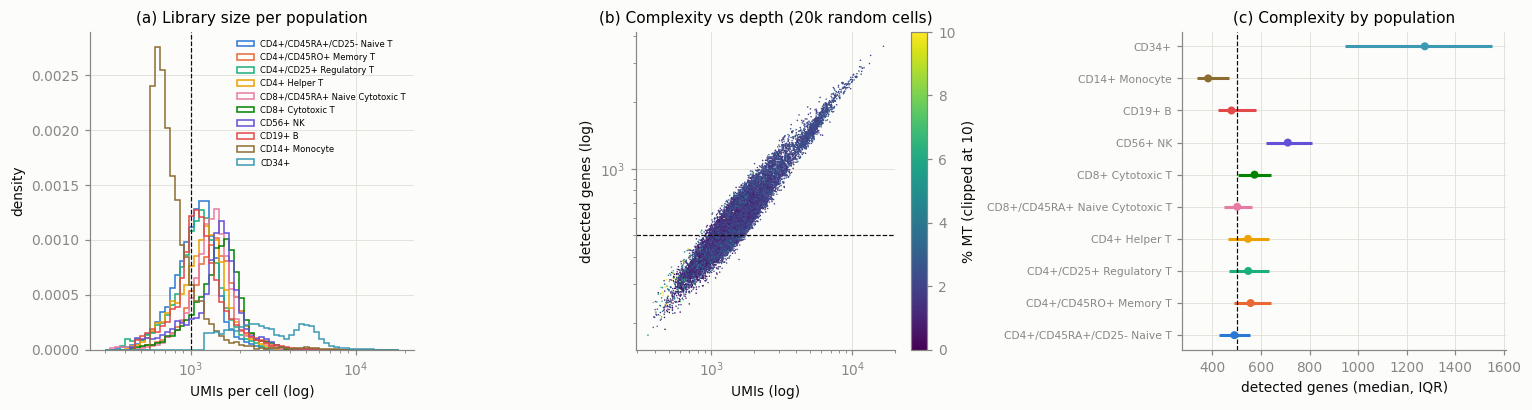

In [29]:
H_COLOR = dict(zip(H_ORDER, PALETTE + ["#8c6d31", "#3b9ab2"]))
rng = np.random.default_rng(SEED)
ps = rng.choice(zh.n_obs, 20_000, replace=False)
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
bins = np.logspace(np.log10(qc_h.total_counts.min() * 0.9), np.log10(qc_h.total_counts.max() * 1.1), 60)
for t in H_ORDER:
    axes[0].hist(qc_h.loc[qc_h.population == t, "total_counts"], bins=bins, histtype="step", lw=1.2, color=H_COLOR[t], label=t, density=True)
axes[0].axvline(1000, color=INK, lw=0.8, ls="--")
axes[0].set_xscale("log"); axes[0].set_xlabel("UMIs per cell (log)"); axes[0].set_ylabel("density")
axes[0].set_title("(a) Library size per population"); axes[0].legend(fontsize=5.5)
q = qc_h.iloc[ps]
sca = axes[1].scatter(q.total_counts, q.n_genes, c=q.pct_mt.clip(upper=10), s=1, cmap="viridis", linewidths=0, rasterized=True)
fig.colorbar(sca, ax=axes[1], label="% MT (clipped at 10)")
axes[1].axhline(500, color=INK, lw=0.8, ls="--")
axes[1].set_xscale("log"); axes[1].set_yscale("log"); axes[1].set_xlabel("UMIs (log)"); axes[1].set_ylabel("detected genes (log)")
axes[1].set_title("(b) Complexity vs depth (20k random cells)")
g = qc_h.groupby("population")["n_genes"]
med, q1, q3 = g.median()[H_ORDER], g.quantile(.25)[H_ORDER], g.quantile(.75)[H_ORDER]
y = np.arange(len(H_ORDER))
axes[2].hlines(y, q1, q3, color=[H_COLOR[t] for t in H_ORDER], lw=2); axes[2].scatter(med, y, color=[H_COLOR[t] for t in H_ORDER], s=18, zorder=3)
axes[2].axvline(500, color=INK, lw=0.8, ls="--")
axes[2].set_yticks(y, H_ORDER, fontsize=7); axes[2].set_xlabel("detected genes (median, IQR)"); axes[2].set_title("(c) Complexity by population")
fig.tight_layout(); plt.show()

**QC observations**
* **Depth differs by population (= library):** median UMIs from 782 (CD14+ monocytes) to 4,169 (CD34+), detected genes
  from 382 to 1,274; the T, NK and B populations lie at 1,186–1,630 UMIs and 478–710 genes. The monocyte library is
  clearly the weakest (mode below 1,000 UMIs in panel a).
* **The shared rule (≥ 500 genes, ≥ 1,000 UMIs) is too strict for this depth:** it keeps only 61,395 of 94,655 cells,
  and very unevenly: **19.9% of monocytes, 42.6% of B cells and 46.2% of CD4 naive T cells, but 99.4% of CD34+ cells**.
  Only 61,667 cells have ≥ 500 genes. Applied as written, R4 would remove most monocytes and turn a balanced label set
  into a skewed one; a depth-appropriate gene threshold is needed (93,240 cells have ≥ 300 genes, 94,626 ≥ 200).
* **%MT is low everywhere** (median 1.9%; 606 cells > 5%, 83 > 10%, 9 > 20%): 10x cell calling plus purification left
  few dying cells. No %MT filter is needed.
* The top gene takes only 2.5% of a median cell's UMIs; no gene dominates.

## H.5 Gene-level behaviour: detection, top genes, mean–variance relationship
All 94,655 cells (no cell filter applied), UMI counts.

In [30]:
n_expr_h, mean_h, var_h = gene_level(zh, "UMIs")

Genes detected in at most k cells:
  <=  0 cells:     0  (0.0%)
  <=  2 cells:  2508  (11.4%)
  <=  9 cells:  4897  (22.3%)
  <= 19 cells:  6285  (28.6%)
  <= 49 cells:  7902  (36.0%)

Top-15 genes by share of all UMIs (%):
MALAT1    2.11
RPL13     1.59
RPS2      1.50
RPL10     1.42
RPL13A    1.31
RPS6      1.16
B2M       1.12
RPS18     1.10
RPS4X     1.02
TMSB4X    1.01
RPL3      1.00
RPS27     0.98
RPS14     0.96
RPS3      0.96
RPL32     0.95


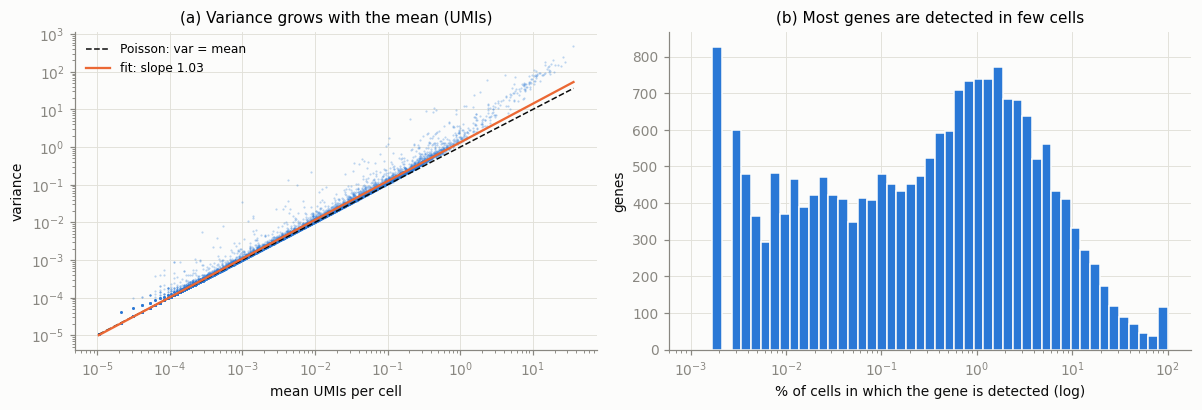

Fitted log-log slope of variance vs mean: 1.03


In [31]:
slope_h = plot_gene_level(n_expr_h, mean_h, var_h, zh.n_obs, "UMIs")
print(f"Fitted log-log slope of variance vs mean: {slope_h:.2f}")

**Gene-level observations** (94,655 cells, 21,952 genes)
* **Log-log slope 1.03**, close to Poisson and the lowest of all datasets (Baron ≈ 1.1, G 1.08): very shallow UMI data.
* **The top genes are ribosomal** (12 of the top 15: RPL13, RPS2, RPL10, RPL13A, RPS6, …) plus MALAT1, B2M and TMSB4X;
  **no mitochondrial gene in the top 15** (G: seven).
* Detection: no gene is undetected (pre-filtered), 22.3% are detected in fewer than 10 cells and 36.0% in fewer than 50.

## H.6 Labels vs markers: how pure are the sorted populations?
Because the labels are sort gates, the marker check here measures **sort purity** (and contamination) rather than
annotation quality. First the immune lineage panel and the T-subset panel by population; then an RNA-only provisional
lineage call (same `marker_call()` as for G) cross-tabulated against the population.

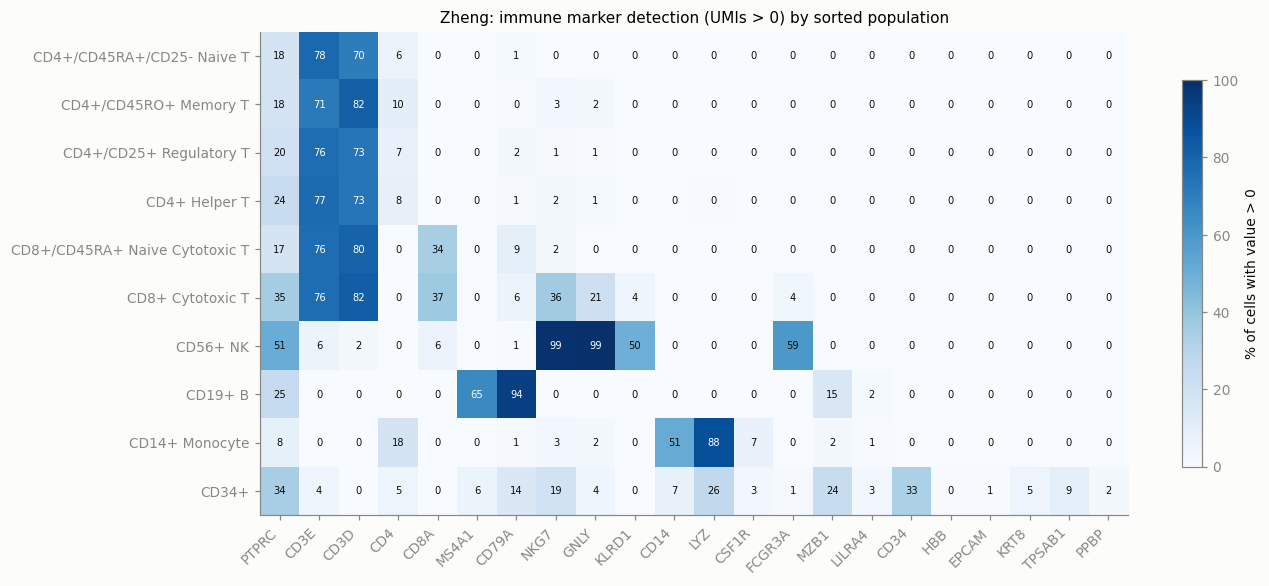

Panel markers not present (exactly once) in this dataset: ['JCHAIN']


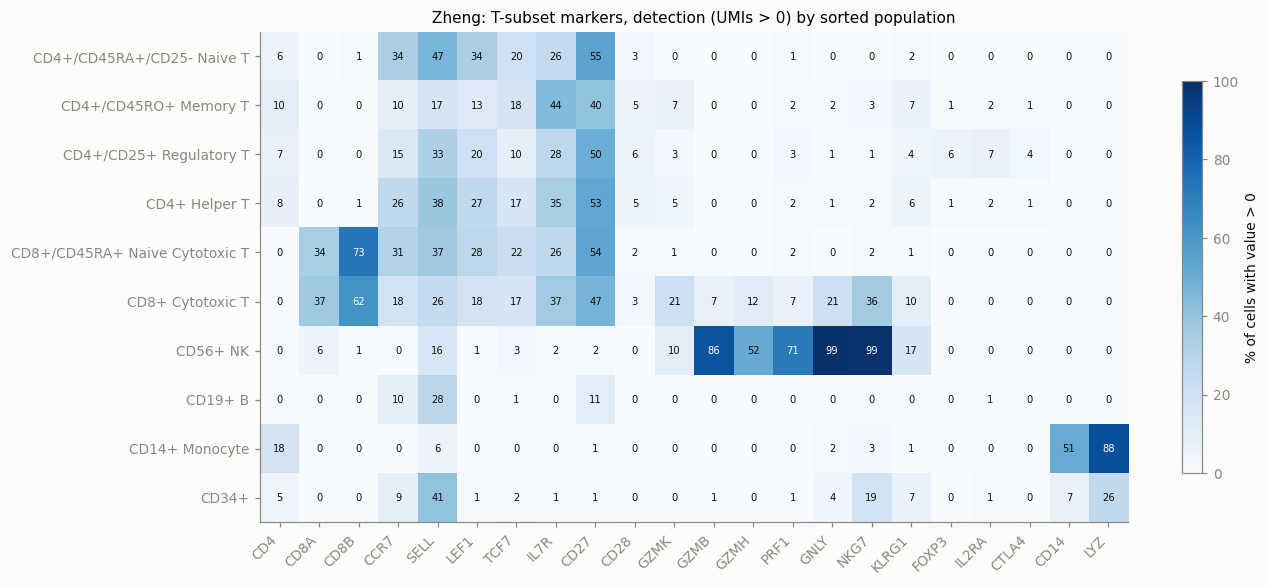

In [32]:
detect_h = detection_heatmap(zh, IMMUNE_CHECK, ct_h, H_ORDER, "Zheng: immune marker detection (UMIs > 0) by sorted population")
missing = [g for g in IMMUNE_CHECK + TSUBSET_RNA if (zh.var["symbol"] == g).sum() != 1]
print("Panel markers not present (exactly once) in this dataset:", missing)
detect_th = detection_heatmap(zh, TSUBSET_RNA, ct_h, H_ORDER, "Zheng: T-subset markers, detection (UMIs > 0) by sorted population")

In [33]:
L_h = lognorm(zh.X)
call_h, used_h = marker_call(L_h, zh.var.symbol.values, IMMUNE_CALL)
print("Markers used per call:", used_h)
EXPECTED_H = {t: ("T" if t.endswith(" T") else {"CD56+ NK": "NK", "CD19+ B": "B", "CD14+ Monocyte": "myeloid", "CD34+": "progenitor"}[t]) for t in H_ORDER}
xt_call = pd.crosstab(ct_h, pd.Series(call_h, index=ct_h.index, name="RNA call"), normalize="index").loc[H_ORDER] * 100
display(xt_call.round(1))
agree = np.array([c == EXPECTED_H[t] for t, c in zip(ct_h, call_h)])
assigned = call_h != "unassigned"
print("Per population: % of cells whose RNA call is the population's expected lineage (all cells / assigned cells only):")
display(pd.DataFrame({"expected lineage": pd.Series(EXPECTED_H),
                      "% agree (all)": pd.Series(agree).groupby(ct_h.to_numpy()).mean() * 100,
                      "% unassigned": pd.Series(~assigned).groupby(ct_h.to_numpy()).mean() * 100,
                      "% agree (assigned)": pd.Series(agree[assigned]).groupby(ct_h.to_numpy()[assigned]).mean() * 100}).loc[H_ORDER].round(1))
del L_h
gc.collect();

Markers used per call: {'T': ['CD3E', 'CD3D'], 'B': ['MS4A1', 'CD79A'], 'NK': ['NKG7', 'GNLY', 'KLRD1'], 'myeloid': ['CD14', 'LYZ', 'CSF1R'], 'plasma': ['MZB1'], 'pDC': ['LILRA4', 'IL3RA'], 'progenitor': ['CD34'], 'erythroid': ['HBB', 'HBA1'], 'epithelial': ['EPCAM', 'KRT8']}


RNA call,B,NK,T,epithelial,erythroid,myeloid,pDC,plasma,progenitor,unassigned
cell_type1,,,,,,,,,,
CD4+/CD45RA+/CD25- Naive T,0.0,0.1,75.8,0.0,0.0,0.0,0.0,0.2,0.1,23.7
CD4+/CD45RO+ Memory T,0.0,0.0,74.2,0.0,0.0,0.0,0.0,0.1,0.0,25.6
CD4+/CD25+ Regulatory T,0.1,0.0,74.9,0.0,0.0,0.1,0.0,0.1,0.0,24.7
CD4+ Helper T,0.0,0.0,75.3,0.0,0.0,0.1,0.0,0.1,0.0,24.3
CD8+/CD45RA+ Naive Cytotoxic T,0.2,0.1,76.7,0.0,0.0,0.0,0.0,0.0,0.0,23.0
CD8+ Cytotoxic T,0.1,5.5,69.3,0.0,0.0,0.0,0.0,0.2,0.0,24.9
CD56+ NK,0.0,98.6,0.1,0.0,0.0,0.0,0.1,0.0,0.0,1.1
CD19+ B,77.2,0.0,0.0,0.0,0.0,0.0,2.0,6.9,0.0,13.8
CD14+ Monocyte,0.0,0.1,0.2,0.1,0.0,88.9,1.0,1.3,0.0,8.4


Per population: % of cells whose RNA call is the population's expected lineage (all cells / assigned cells only):


,expected lineage,% agree (all),% unassigned,% agree (assigned)
CD4+/CD45RA+/CD25- Naive T,T,75.8,23.7,99.3
CD4+/CD45RO+ Memory T,T,74.2,25.6,99.7
CD4+/CD25+ Regulatory T,T,74.9,24.7,99.5
CD4+ Helper T,T,75.3,24.3,99.5
CD8+/CD45RA+ Naive Cytotoxic T,T,76.7,23.0,99.6
CD8+ Cytotoxic T,T,69.3,24.9,92.4
CD56+ NK,NK,98.6,1.1,99.7
CD19+ B,B,77.2,13.8,89.6
CD14+ Monocyte,myeloid,88.9,8.4,97.0
CD34+,progenitor,26.4,42.2,45.7


**Marker observations**
* **The coarse lineages are pure.** Among cells with an RNA lineage call, 99.3–99.7% of the five CD4 / CD8-naive
  populations are called T, 99.7% of NK cells NK, 97.0% of monocytes myeloid and 89.6% of B cells B. 23–26% of the T cells
  and 13.8% of the B cells are `unassigned` (too few marker UMIs at this depth), so over all cells the agreement is
  69.3–76.7% for the T populations. CD3E/CD3D are detected in 70–82% of T cells, MS4A1/CD79A in 65% / 94% of B cells,
  NKG7/GNLY in 99% of NK cells and LYZ in 88% of monocytes.
* **Two populations are not pure:**
  * `CD8+ Cytotoxic T`: 5.5% of its cells are called NK, and NKG7/GNLY are detected in 36% / 21% (≤ 3% / ≤ 2% in the CD4
    populations). This broad CD8+ gate contains effector-like cytotoxic cells and possibly NK cells: the same CD8
    effector / NK overlap as in G.
  * **`CD34+` is heterogeneous:** only 26.4% of its cells are called progenitor (CD34 mRNA detected in 33%), 42.2% are
    unassigned, and the rest are called plasma (MZB1) 9.7%, myeloid 8.5%, pDC 7.7% and B 3.4%. In PCA (H.7) the CD34+
    cells spread along the monocyte arm. As a class it is not one cell type.
  * In addition, 6.9% of `CD19+ B` cells are called plasma (MZB1 detected in 15%).
* **T-cell subset markers are almost invisible at this depth.** CD4 mRNA is detected in only 6–10% of the cells of the
  CD4 populations (and in 18% of monocytes, which express CD4), CD8A in 34–37% of the CD8 populations. **FOXP3 is
  detected in 6% of `CD4+/CD25+ Regulatory T` cells** (1% in CD4 helper and memory, 0% in naive) and IL2RA in 7%;
  CCR7 / SELL / LEF1 are detected in 34 / 47 / 34% of CD4 naive vs 10 / 17 / 13% of CD4 memory cells. The CD4 subset
  labels can hardly be recovered from a single cell's RNA here.

## H.7 Global structure: do cells group by population?
Same throw-away pipeline as for A–F on a stratified subsample of 2,000 cells per population (all 2,612 monocytes
would not change the picture; the subsample keeps memory and silhouette cost bounded). Inspection only.

In [34]:
rng = np.random.default_rng(SEED)
sub_h = np.sort(np.concatenate([rng.choice(np.flatnonzero(ct_h.to_numpy() == t), min(2000, (ct_h == t).sum()), replace=False) for t in H_ORDER]))
zsub = zh[sub_h].copy()
P_h, evr_h, load_h = throwaway_pca(zsub)
lab_h = ct_h.to_numpy()[sub_h]
Tm = np.isin(lab_h, [t for t in H_ORDER if t.endswith(" T")])
cd4m = np.isin(lab_h, H_ORDER[:4]); cd8m = np.isin(lab_h, H_ORDER[4:6])
sil_h = {"all 10 populations": silhouette(P_h, lab_h), "6 T-cell populations": silhouette(P_h[Tm], lab_h[Tm]),
         "4 CD4 populations": silhouette(P_h[cd4m], lab_h[cd4m]), "2 CD8 populations": silhouette(P_h[cd8m], lab_h[cd8m]),
         "4 non-T populations (NK, B, mono, CD34)": silhouette(P_h[~Tm], lab_h[~Tm])}
print({k: round(v, 3) for k, v in sil_h.items()})
for pc in load_h:
    print(f"{pc} top +: {zsub.var.symbol[load_h[pc].nlargest(8).index].tolist()}\n    top -: {zsub.var.symbol[load_h[pc].nsmallest(8).index].tolist()}")

Explained variance, PC1..PC10 (%): [4.6 2.2 1.5 1.  0.5 0.4 0.3 0.3 0.2 0.2]
Cumulative variance in 20 / 50 PCs: 13.1% / 17.9%


{'all 10 populations': 0.118, '6 T-cell populations': 0.004, '4 CD4 populations': -0.003, '2 CD8 populations': 0.088, '4 non-T populations (NK, B, mono, CD34)': 0.412}
PC1 top +: ['CST3', 'S100A9', 'LYZ', 'S100A8', 'FCN1', 'TYMP', 'LST1', 'CFD']
    top -: ['RPS27', 'LTB', 'B2M', 'RPS3A', 'MALAT1', 'IL32', 'RPL13', 'CD8B']
PC2 top +: ['GNLY', 'NKG7', 'GZMB', 'GZMA', 'CST7', 'CLIC3', 'FGFBP2', 'PRF1']
    top -: ['RPL13', 'LTB', 'CD79A', 'HLA-DRA', 'MS4A1', 'CD79B', 'HLA-DPA1', 'HLA-DPB1']


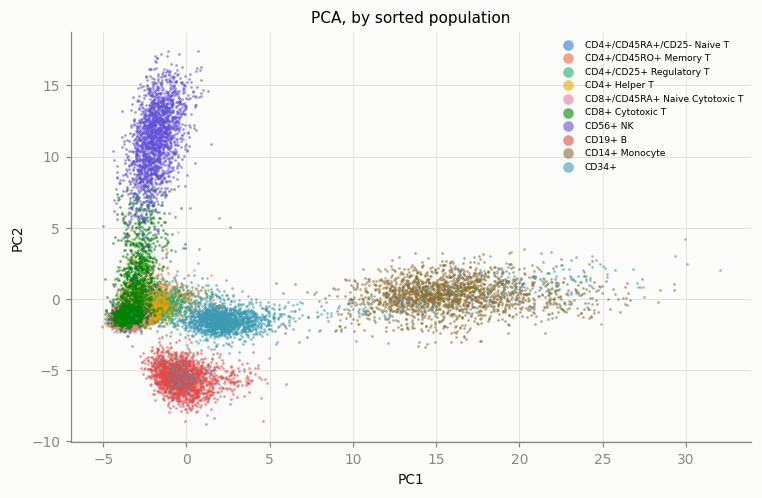

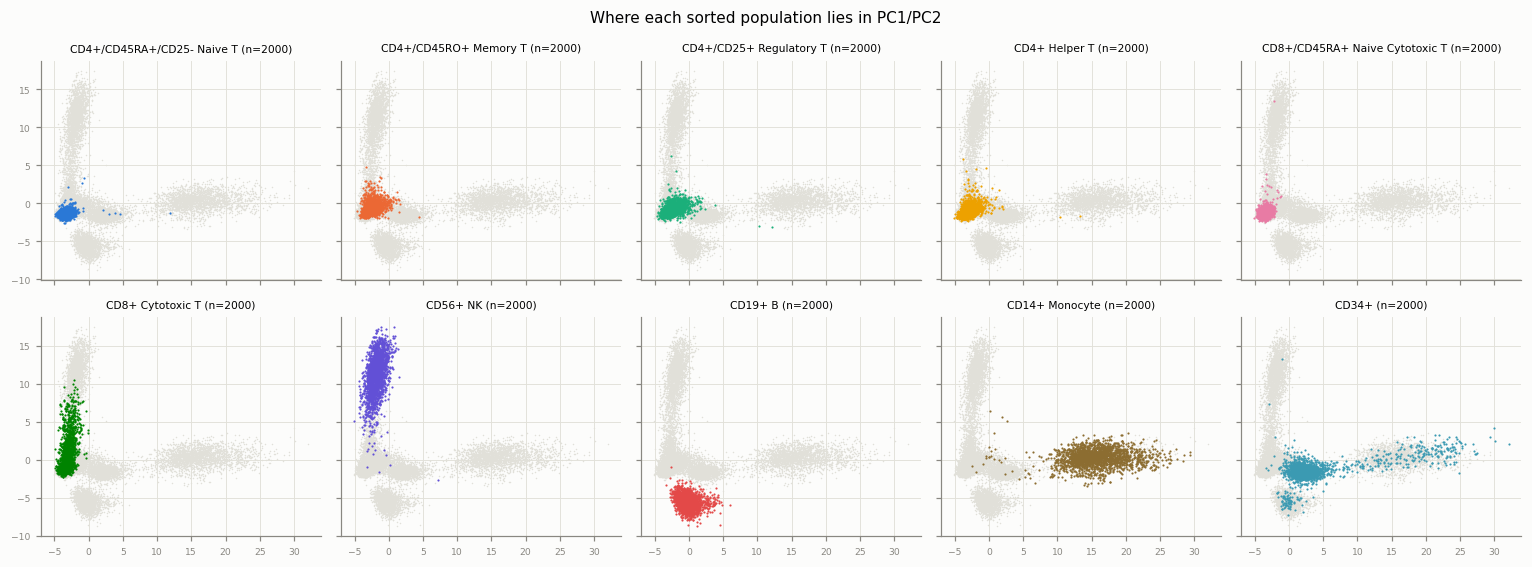

In [35]:
perm_h = np.random.default_rng(SEED).permutation(len(lab_h))
fig, ax = plt.subplots(figsize=(7, 4.6))
scatter_groups(ax, P_h, lab_h, H_COLOR, "PCA, by sorted population", perm_h)
ax.legend(markerscale=4, fontsize=6, loc="best")
fig.tight_layout(); plt.show()
fig, axes = plt.subplots(2, 5, figsize=(14, 5.2), sharex=True, sharey=True)
for ax, t in zip(axes.ravel(), H_ORDER):
    s = lab_h == t
    ax.scatter(P_h[~s, 0], P_h[~s, 1], s=1, color=GRID, linewidths=0, rasterized=True)
    ax.scatter(P_h[s, 0], P_h[s, 1], s=2, color=H_COLOR[t], linewidths=0, rasterized=True)
    ax.set_title(f"{t} (n={s.sum()})", fontsize=7); ax.tick_params(labelsize=6)
fig.suptitle("Where each sorted population lies in PC1/PC2", fontsize=10)
fig.tight_layout(); plt.show()
del zsub
gc.collect();

**Structure observations** (2,000 cells per population)
* **Non-T populations separate well, T-cell populations do not:** silhouette 0.412 among NK, B, monocytes and CD34+,
  but **0.004 among the six T-cell populations and −0.003 among the four CD4 populations** (0.088 for the two CD8
  populations); 0.118 overall. PC1 (4.6%) is myeloid (CST3, S100A8/9, LYZ, FCN1) vs lymphoid, PC2 (2.2%) NK/cytotoxic
  (GNLY, NKG7, GZMB, PRF1) vs B (CD79A/B, MS4A1, HLA class II). 20 PCs hold only 13.1% of the variance (shallow data).
* All four CD4 populations and the CD8 naive population occupy the same spot; `CD8+ Cytotoxic T` extends towards the NK
  cluster; CD34+ cells spread from the lymphoid core along the monocyte arm.
* H therefore offers a clean **lineage-level** task (T / B / NK / monocyte / CD34+) and a **T-subset task that is close
  to impossible from RNA alone** at this depth, consistent with G, where the same subsets separated mainly in protein.
  Because label = library, part of whatever separation exists may be a library effect; these files cannot tell.

## H.8 Summary of the Zheng inspection

| aspect | Zheng purified PBMC (supplied files) |
|---|---|
| cells × genes | 94,655 × 21,952 (all-zero genes of the original 32,738 removed by `sorted_pbmc.ipynb`) |
| technology | 10x Genomics 3' with UMIs (14-nt barcodes, first-generation chemistry); one library per purified population |
| values available | **raw UMI counts** |
| labels | purification gate of each library (`cell_type_original`), 10 classes; CD4/CD8 gates nested |
| missing values | none |
| prior QC | 10x cell calling only (min 334 UMIs / 142 genes); all-zero genes removed |
| MT genes | present (13); median %MT 1.9 |
| classes | 10, 2,612–11,953 cells, imbalance 4.6× |
| batch structure | label = library; donors unknown |
| provenance | built by `sorted_pbmc.ipynb` from the ten 10x filtered matrices; CSV = `obs` |
| notable | shallowest dataset (median 1,426 UMIs); T subsets inseparable by RNA; CD34+ heterogeneous; shared QC rule keeps 19.9% of monocytes |

## H.9 Proposed preprocessing for Zheng (for discussion)

* **Step A — cell filtering (R4, decision needed).** The shared rule is too strict for this depth (keeps 61,395 of 94,655
  cells, 19.9% of monocytes). Use a lower gene threshold for H (≥ 300 genes keeps 93,240 cells, ≥ 200 keeps 94,626), or
  accept the loss and the skew? No %MT filter needed (83 cells > 10%).
* **Step B — labels (decision needed).** Handle the nested gates explicitly: either (a) drop `CD4+ Helper T` and
  `CD8+ Cytotoxic T` (supersets) and keep 8 disjoint classes, or (b) keep them as parent nodes in the hierarchy (CD4 T ⊃
  naive / memory / regulatory; CD8 T ⊃ naive). Exclude or relabel `CD34+` (heterogeneous). Evaluate T subsets only with
  the caveat that RNA barely separates them.
* **Step C — genes (R2, R5).** hg19-era names: 20,809 symbols shared with G, 15,482 with Baron; sum or drop the 36
  duplicated symbols; MT genes only for QC.
* **Step D — normalisation (R3).** `normalize_total` (10,000) + `log1p` on the UMI counts, as for Baron; no deviation.
* **Role in the study:** a large, balanced, FACS-defined PBMC reference. With G-PDC101 it forms an **immune
  cross-dataset pair with FACS-defined labels on both sides** (CD4 naive, CD8 naive and monocytes shared directly; memory
  gates at different granularity). Because label = library, a within-H split mostly measures library recognition, so H
  is better used as a reference evaluated on another dataset (H → G-PDC101) than as a within-dataset benchmark.

---
# Cross-dataset comparison: G (Caron), H (Zheng), and A–F
Analogous to the cross-dataset sections of `data_preview_dataset_B_and_C.ipynb` and `data_preview_dataset_D_E_F.ipynb`:
gene overlap, label vocabularies and one summary table. A–F are read one at a time from the existing
`data/interim/*_human.h5ad` files (read only; nothing is rebuilt or written). G and H are the first immune datasets,
so the label comparison is mainly G ↔ H, plus the few immune labels of A and D.

In [36]:
def sym_set(k, a):
    v = a.var
    if k == "A Baron":
        return set(a.var_names)
    if k == "B Xin":
        return set(v.symbol[v.mapped])
    if k == "D Segerstolpe":
        return set(v.symbol[~v.is_ercc & ~v.is_egfp])
    if k in ("C Muraro", "F Enge"):
        return set(v.symbol[~v.is_ercc])
    return set(v.symbol)

LABEL_DONOR = {"A Baron": ("cell_type1", "human"), "B Xin": ("cell_type1", "donor"), "C Muraro": ("cell_type1", "donor"),
               "D Segerstolpe": ("cell_type1", "donor"), "E Lawlor": ("cell_type1", "donor"), "F Enge": ("cell_type1", "donor")}
genes, table, immune_labels = {}, {}, {}
for k, p in EARLIER_H5.items():
    a = ad.read_h5ad(p)
    genes[k] = sym_set(k, a)
    lc, dc = LABEL_DONOR[k]
    lab = a.obs[lc].dropna().astype(str).str.lower()
    tot = np.asarray(a.X.sum(1)).ravel(); nz = np.asarray((a.X > 0).sum(1)).ravel()
    table[k] = {"cells deposited": a.n_obs, "features": a.n_vars, "labelled cells": len(lab), "author labels": lab.nunique(),
                "donors": a.obs[dc].nunique(), "median per-cell total (deposited unit)": float(np.median(tot)),
                "median detected features": float(np.median(nz))}
    immune_labels[k] = lab[lab.map(lambda t: LINEAGE.get(t) == "immune")].value_counts().to_dict()
    del a; gc.collect()
genes["G Caron"], genes["H Zheng"] = sym_set_g_all, set(zh.var.symbol)
table["G Caron"] = {"cells deposited": g_summary["cells"], "features": g_summary["genes"],
                    "labelled cells": sum(g_summary["gate_counts"].values()), "author labels": len(g_summary["gate_counts"]),
                    "donors": 3, "median per-cell total (deposited unit)": g_summary["median_umis"],
                    "median detected features": g_summary["median_genes"]}
table["H Zheng"] = {"cells deposited": zh.n_obs, "features": zh.n_vars, "labelled cells": zh.n_obs, "author labels": ct_h.nunique(),
                    "donors": np.nan, "median per-cell total (deposited unit)": float(np.median(tot_h)),
                    "median detected features": float(np.median(ng_h))}
display(pd.DataFrame(table).T)
print("G: labelled cells = PDC101 cells with a FACS sort gate (the organ-donor cells have no labels in GEO); donors = D496, D503, PDC101 volunteer.")
print("H: donors cannot be determined from the files (NaN).")
print("Immune labels in A-F:", {k: v for k, v in immune_labels.items() if v})

,cells deposited,features,labelled cells,author labels,donors,median per-cell total (deposited unit),median detected features
A Baron,8569.0,20125.0,8569.0,14.0,4.0,5.075000e+03,1847.0
B Xin,1600.0,39851.0,1600.0,4.0,18.0,5.385261e+05,5687.5
C Muraro,3072.0,19140.0,2126.0,10.0,4.0,1.477645e+04,4509.5
D Segerstolpe,3514.0,26271.0,3514.0,15.0,10.0,1.750905e+05,4957.5
E Lawlor,638.0,26616.0,638.0,8.0,8.0,1.502768e+06,8333.5
F Enge,2544.0,23460.0,2544.0,7.0,8.0,5.088825e+05,3236.5
G Caron,223390.0,60725.0,10487.0,8.0,3.0,5.435000e+03,2025.0
H Zheng,94655.0,21952.0,94655.0,10.0,NaN,1.426000e+03,552.0


G: labelled cells = PDC101 cells with a FACS sort gate (the organ-donor cells have no labels in GEO); donors = D496, D503, PDC101 volunteer.
H: donors cannot be determined from the files (NaN).
Immune labels in A-F: {'A Baron': {'macrophage': 55, 'mast': 25, 't_cell': 7}, 'D Segerstolpe': {'mast': 7, 'mhc_class_ii': 5}}


In [37]:
ov = pd.DataFrame({a: {b: len(genes[a] & genes[b]) for b in genes} for a in genes})
display(ov)
gh = genes["G Caron"] & genes["H Zheng"]
all8 = set.intersection(*genes.values())
print(f"Genes shared by G and H: {len(gh)} | shared by all eight datasets: {len(all8)} | by A-F (six): {len(set.intersection(*[genes[k] for k in EARLIER_H5]))}")
imm = ["PTPRC", "CD3E", "CD4", "CD8A", "MS4A1", "CD79A", "NKG7", "GNLY", "CD14", "LYZ", "FCGR3A", "CCR7", "SELL", "IL7R",
       "FOXP3", "IL2RA", "GZMB", "GZMK", "CD34", "HLA-DRA", "INS", "GCG"]
print("Immune (and two pancreas) markers missing per dataset:", {g: [k for k in genes if g not in genes[k]] for g in imm if g not in all8})

,A Baron,B Xin,C Muraro,D Segerstolpe,E Lawlor,F Enge,G Caron,H Zheng
A Baron,20125,18199,16475,18936,18143,18148,19532,15482
B Xin,18199,37987,16650,21732,17652,19736,28864,15200
C Muraro,16475,16650,19046,18361,16826,18237,17576,15312
D Segerstolpe,18936,21732,18361,25453,18909,21511,23147,16501
E Lawlor,18143,17652,16826,18909,26491,18797,24325,17946
F Enge,18148,19736,18237,21511,18797,23368,20603,15493
G Caron,19532,28864,17576,23147,24325,20603,58828,20809
H Zheng,15482,15200,15312,16501,17946,15493,20809,21916


Genes shared by G and H: 20809 | shared by all eight datasets: 13313 | by A-F (six): 14746
Immune (and two pancreas) markers missing per dataset: {'CD3E': ['C Muraro'], 'GNLY': ['C Muraro'], 'GZMK': ['C Muraro'], 'HLA-DRA': ['A Baron'], 'INS': ['H Zheng'], 'GCG': ['H Zheng']}


In [38]:
# Label vocabularies of G (PDC101 sort gates) and H (sorted populations) on one harmonised scale. Only spelling/nesting is
# made explicit; nothing is merged. Nested gates are marked as such.
HARM_G = {"cd4_n": "CD4 naive T", "cd4_cm": "CD4 central memory T", "cd4_em": "CD4 effector memory T", "cd8_n": "CD8 naive T",
          "cd8_cm": "CD8 central memory T", "cd8_em": "CD8 effector memory T", "cd8_emra": "CD8 TEMRA", "monocyte": "monocyte"}
HARM_H = {"CD4+/CD45RA+/CD25- Naive T": "CD4 naive T", "CD4+/CD45RO+ Memory T": "CD4 memory T (CM + EM)",
          "CD4+/CD25+ Regulatory T": "CD4 regulatory T", "CD4+ Helper T": "CD4 T, all (nested)", "CD8+/CD45RA+ Naive Cytotoxic T": "CD8 naive T",
          "CD8+ Cytotoxic T": "CD8 T, all (nested)", "CD56+ NK": "NK", "CD19+ B": "B", "CD14+ Monocyte": "monocyte", "CD34+": "CD34+ progenitor"}
harm = pd.DataFrame({"G Caron (PDC101 sort gate)": pd.Series(g_summary["gate_counts"]).rename(HARM_G).groupby(level=0).sum(),
                     "H Zheng (sorted population)": counts_h.rename(HARM_H).groupby(level=0).sum()}).fillna(0).astype(int)
harm["in both"] = (harm > 0).all(axis=1)
display(harm.sort_values(["in both", "H Zheng (sorted population)"], ascending=False))
print("G provisional protein labels (organ donors + PDC101; not ground truth):", g_summary["prov_counts"])

,G Caron (PDC101 sort gate),H Zheng (sorted population),in both
CD8 naive T,1205,11953,True
CD4 naive T,1134,10479,True
monocyte,1668,2612,True
"CD4 T, all (nested)",0,11213,False
CD4 regulatory T,0,10263,False
CD4 memory T (CM + EM),0,10224,False
"CD8 T, all (nested)",0,10209,False
B,0,10085,False
CD34+ progenitor,0,9232,False
NK,0,8385,False


G provisional protein labels (organ donors + PDC101; not ground truth): {'T': 86719, 'unassigned': 50131, 'myeloid': 31002, 'NK': 29782, 'B': 8600, 'plasma': 5675, 'epithelial': 5311, 'progenitor': 3327, 'erythroid': 2532, 'pDC': 311}


## Summary across datasets

| aspect | A: Baron | B: Xin | C: Muraro | D: Segerstolpe | E: Lawlor | F: Enge | G: Caron | H: Zheng |
|---|---|---|---|---|---|---|---|---|
| accession | GSE84133 | GSE81608 | GSE85241 | E-MTAB-5061 | GSE86469 | GSE81547 | GSE229791 | none (10x downloads, via `sorted_pbmc.ipynb`) |
| tissue | pancreas | pancreas | pancreas | pancreas | pancreas | pancreas | immune cells, 8 tissue sites + sorted blood | sorted blood |
| cells deposited × features | 8,569 × 20,125 | 1,600 × 39,851 | 3,072 × 19,140 | 3,514 × 26,271 | 638 × 26,616 | 2,544 × 23,460 | 223,390 × 60,725 (+ 277 ADTs) | 94,655 × 21,952 |
| technology | inDrop, 3' UMI | C1 SMARTer, full-length | CEL-seq2, 3' UMI | Smart-seq2, full-length | C1 SMARTer, full-length | Smart-seq2-like, full-length | 10x 3' v3.1, UMI, CITE-seq | 10x 3' (first generation), UMI |
| values | raw UMI counts | RPKM only | UMI-corrected transcripts | raw reads + RPKM | RSEM expected counts | raw reads (deduplicated) | raw UMI + raw ADT counts | raw UMI counts |
| median per-cell total / detected features (deposited unit) | 5,075 / 1,847 | (RPKM) / 5,687.5 | 14,776 / 4,509.5 | 175,091 / 4,957.5 (all wells) | 1.50M / 8,333.5 | 508,883 / 3,236.5 | 5,435 / 2,025 | 1,426 / 552 |
| labelled cells / labels / real types | 8,569 / 14 / 14 | 1,600 / 4 / 4 | 2,126 / 10 / 9 | 2,209 / 14 / 11 | 638 / 8 / 7 | 2,544 / 7 / 6 | 10,487 / 8 / 8 (PDC101 only) | 94,655 / 10 / 10 (2 nested) |
| label source | curated `.rds` | GEO SOFT | ExperimentHub EH2693 | ArrayExpress SDRF | GEO SOFT | GEO SOFT | **not in GEO**; FACS gates (hashtag) for PDC101 | purification gate (library) |
| MT genes | removed | present (no prefix) | absent | absent | present (`MT-`) | absent | present (37) | present (13) |
| donors | 4 | 18 | 4 | 10 | 8 | 8 | 2 organ donors + 1 volunteer | unknown |
| var/mean slope | ≈ 1.1 | ≈ 1.5 | ≈ 1.2 | 1.41 | 1.51 | 1.43 | 1.08 | 1.03 |
| silhouette by type | 0.31 | 0.27 | – | 0.30 | 0.36 | 0.29 | 0.24 (provisional, RNA); PDC101 gates 0.08 RNA / 0.12 protein | 0.12 (T populations 0.004) |

Cells, features, median totals and donors for A–H are from the table printed above (A–F read from the existing
`data/interim` files, nothing rewritten). The label counts, slopes and silhouettes of A–F are those stated in
`data_preview_dataset_D_E_F.ipynb` (D's 2,209 = author-QC-pass cells); the table above counts D's
`not_applicable` wells as labelled. Xin's median total is in RPKM and not comparable.

**Gene overlap:** G and H share 20,809 symbols; **all eight datasets share 13,313** (A–F: 14,746). G's GENCODE v24
gene set (58,828 distinct symbols) is by far the largest; H's hg19-era names overlap A–F least (15,200–17,946). Among the immune markers checked, CD3E, GNLY and GZMK are missing
only from Muraro, HLA-DRA only from Baron (its R-converted names write `HLA.DRA`, see `preprocessing.ipynb`), and INS /
GCG are absent from H (removed there as all-zero genes, as expected for blood).

**Label overlap:** G-PDC101 and H share three classes directly (CD4 naive T, CD8 naive T, monocyte). H's
`CD4+/CD45RO+ Memory T` corresponds to G's CD4 central + effector memory gates, and G's CD8 TCM/TEM/TEMRA lie inside
H's `CD8+ Cytotoxic T`. H's regulatory T, B, NK and CD34+ populations have no PDC101 counterpart (B, NK and progenitor
cells exist only provisionally among G's organ-donor cells). A–F contain hardly any immune cells (Baron: 55 macrophages,
25 mast cells, 7 T cells; Segerstolpe: 7 mast, 5 MHC class II cells), so pancreas ↔ immune transfer could only serve
as an unseen-class test.

**Technology pattern:** G and H are 10x UMI datasets like Baron and share its low mean–variance slope (1.03–1.1), but
H is 3.8× shallower than G (median 1,426 vs 5,435 UMIs). In both, the labels that are defined by FACS (T-cell subsets)
are the ones RNA separates worst: a property of the labels, not of the technology.

## Questions to agree on before preprocessing G and H
1. **G labels:** GEO has none for the 212,903 organ-donor cells. Obtain the MMoCHi annotations from the authors / paper,
   use only the 10,487 FACS-labelled PDC101 cells, or use the organ-donor cells unlabelled (tissue shift / open set)?
2. **G modality:** RNA only (comparable with A–F and H), or also the 277-ADT protein panel? If protein is used, normalise
   the ADTs per donor (3× depth difference): CLR, or DSB with the 9 isotype controls?
3. **H cell filter:** the shared rule keeps only 61,395 of 94,655 cells (19.9% of monocytes). Lower the gene threshold for
   H (≥ 200 / 300 genes), or apply the shared rule and accept the skew?
4. **H nested labels:** drop `CD4+ Helper T` / `CD8+ Cytotoxic T` (supersets), or model them as parent nodes in the
   hierarchy (HOE)? Keep or drop the heterogeneous `CD34+` population?
5. **T-cell subset granularity:** RNA barely separates CD4 naive / memory / regulatory (H) or the 7 T gates
   (G-PDC101). Evaluate at lineage level (T / B / NK / monocyte), at CD4 / CD8 level, or at full subset level with the
   caveat documented?
6. **G %MT filter:** add a %MT ceiling (e.g. 20%) as a documented dataset-specific rule for G, where %MT is measurable
   and not type-biased?
7. **Scenarios:** H → G-PDC101 (FACS-defined PBMC labels across chemistry, era and donor) as the immune cross-dataset
   test; blood → tissue within G as a biological shift; G/H as unseen-lineage queries for pancreas-trained models. Which
   of these enter the study?